# 7.1 · Modelado Probabilístico con Naive Bayes y Patrones Ocupacionales (Fase 4 CRISP-DM)

**CRISP-DM Fase 4 y 5 · Modeling & Evaluation**  
**Proyecto:** JobPath · patrones de transición y reincidencia ocupacional  
**Serie de modelos interpretables de Fase 4:** `7.0_arbol_decision.ipynb` -> `7.1_naive_bayes.ipynb` -> `7.2_knn.ipynb`

---

> **Pregunta guía del cuaderno:**
> ### *¿Qué patrones de reincidencia ocupacional captura un modelo probabilístico ingenuo, cómo cambian según el grupo ocupacional, y qué tan bien los captura aun con outliers?*

---

## Ficha de la sesión

| Elemento | Detalle |
|---|---|
| Cuaderno | `notebooks/refactor/7.1_naive_bayes.ipynb` |
| Lógica modular (SOLID) | `scripts/ScriptsCsv/NaiveBayes/` (`config`, `feature_blocks`, `models`, `bayes_by_counting`, `outlier_diagnostics`, `evaluation`, `occupation_analysis`, `patterns`, `version_comparison`, `plots`, `pipeline`) |
| Alcance principal de datos | **Versión A (`con_outliers`)**: `1,391,018` filas / `281,674` personas en `train` (`30.01 %` positivos) y `347,720` filas / `70,419` personas en `test` (`29.97 %` positivos); `0` personas solapadas |
| Sensibilidad al cierre (Paso 12) | **Versión B (`sin_outliers`, IQR)**: evaluada únicamente al final tras liberar la memoria de A, reutilizando sin re-ajustar los hiperparámetros y el umbral óptimo elegidos en A |
| Insumos (solo lectura) | `data/03_processed/`, `data/04_transformed/`, `reports/eda_jobpath/tables/split_map_resume_id.csv`, `reports/arbol_decision_jobpath/tables/` y `reports/modelado_jobpath/tables/` |
| Salidas exportadas | `reports/naive_bayes_jobpath/figures/` (`15` figuras PNG `nb01`–`nb15`) y `reports/naive_bayes_jobpath/tables/` (`37` tablas CSV, incluida `decision_log_naive_bayes.csv`) |
| Semilla | `42` (validación cruzada agrupada `StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)` y `300` remuestreos de bootstrap a nivel persona `resume_id`) |
| Verificación de integridad | Huella criptográfica SHA-256 inicial y final sobre los `13` archivos de insumo (`ModelingPipeline.snapshot_inputs()` y `verify_inputs()`) |


---

## 1. Entorno, importaciones y huella SHA-256 inicial

**¿Qué hace?** Importa en la primera celda de código todas las librerías estándar, científicas y el paquete modular `scripts.ScriptsCsv.NaiveBayes`, resuelve de forma relativa la raíz del repositorio, ejecuta los 5 tests unitarios obligatorios de la clase `HybridNaiveBayes` y captura la huella SHA-256 inicial de los 13 archivos de entrada.

**¿Por qué existe?** Garantiza que el cuaderno pueda ejecutarse completo con `Run All` en Windows sin rutas absolutas, verifica antes de entrenar que el estimador híbrido cumpla exactamente las propiedades algebraicas exigidas y protege la inmutabilidad de los datos en disco.

**¿Qué recibe y qué entrega?** Recibe la estructura del repositorio. Entrega `CONFIG`, `PIPELINE`, `SNAPSHOT_BEFORE` y el diccionario de pruebas superadas de `HybridNaiveBayes`.

**Papel en el proyecto.** Abre el estudio `7.1` bajo el mismo contrato de reproducibilidad e higiene de datos establecido en `5.0`, `6.0` y `7.0`.

In [1]:
from __future__ import annotations

import gc
from pathlib import Path
import sys
import warnings

from IPython.display import Image, Markdown, display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 35)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.4f}".format)

PROJECT_ROOT = Path.cwd().resolve()
while not ((PROJECT_ROOT / "data").is_dir() and (PROJECT_ROOT / "notebooks").is_dir()):
    PROJECT_ROOT = PROJECT_ROOT.parent

for _rel in ("", "scripts", "scripts/ScriptsCsv"):
    _p = str((PROJECT_ROOT / _rel).resolve())
    if _p not in sys.path:
        sys.path.insert(0, _p)

from scripts.ScriptsCsv.NaiveBayes import (
    GUIDING_QUESTION_ES,
    MODEL_NB_B,
    MODEL_NB_G,
    MODEL_NB_G_STAR,
    MODEL_NB_H,
    NaiveBayesConfig,
    NaiveBayesPipeline,
    VERSION_CON,
    current_process_rss_mb,
    run_hybrid_naive_bayes_self_tests,
    run_revision_self_tests,
)

CONFIG = NaiveBayesConfig(project_root=PROJECT_ROOT, random_state=42, cv_folds=5, bootstrap_resamples=300)
PIPELINE = NaiveBayesPipeline(CONFIG)
SNAPSHOT_BEFORE = PIPELINE.snapshot_inputs()
HYBRID_UNIT_TESTS = run_hybrid_naive_bayes_self_tests(random_state=CONFIG.random_state)
REVISION_UNIT_TESTS = run_revision_self_tests(random_state=CONFIG.random_state)

print(f"Pregunta guía: {GUIDING_QUESTION_ES}")
print(f"Raíz del proyecto: {CONFIG.project_root} | Semilla: {CONFIG.random_state} | RSS inicial: {current_process_rss_mb():.1f} MB")
print(f"Insumos protegidos con huella SHA-256 inicial: {len(SNAPSHOT_BEFORE)}")
display(pd.DataFrame([HYBRID_UNIT_TESTS]))
display(pd.DataFrame([REVISION_UNIT_TESTS]))

Pregunta guia: ¿Qué patrones de reincidencia ocupacional captura un modelo probabilístico ingenuo, cómo cambian según el grupo ocupacional, y qué tan bien los captura aun con outliers?
Raiz del proyecto: C:\Users\User\Documents\JobPath\Version 2\MineriaProtect | Semilla: 42 | RSS inicial: 214.7 MB
Insumos protegidos con SHA-256 inicial: 13


,test_1_reproduces_gaussian_nb_max_diff,test_2_reproduces_bernoulli_nb_max_diff,test_3_predict_proba_row_sum_max_err,test_4_sklearn_clone_max_diff,test_5_log_odds_additivity_max_diff,test_5b_block_log_odds_additivity_max_diff,all_passed
0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,True


### Lectura

El entorno queda inicializado con semilla fija `42` (`RSS inicial = 214.7 MB`), `5` pliegues para validación cruzada agrupada por persona y `300` remuestreos de bootstrap a nivel `resume_id`. Se registraron las huellas SHA-256 iniciales de los `13` archivos de entrada (`empleos_unificado_limpio.csv`, `empleos_limpio_con_competencias_sin_outliers.csv`, `split_map_resume_id.csv`, los cuatro pares `X_*.csv`/`y_*.csv` y los dos `transformers.joblib`).

Asimismo, los **5 tests unitarios obligatorios** de la clase propia `HybridNaiveBayes` pasan sin excepción (`all_passed = True`):
1. Sin columnas binarias reproduce exactamente a `GaussianNB` (diferencia máxima de probabilidad `1.11e-15`).
2. Sin columnas continuas reproduce exactamente a `BernoulliNB` (diferencia máxima `6.66e-16`).
3. Las filas de `predict_proba` suman exactamente `1.0` (error máximo `2.22e-16`).
4. Es totalmente compatible con `sklearn.base.clone` (diferencia `0.0`).
5. El *log-odds* a priori más la suma de contribuciones por variable (tanto desglosando las `2,981` columnas como agrupando las `2,967` *dummies* de ocupación en un bloque) reproduce el *log-odds* del modelo con error máximo `4.88e-15`.

---

## 2. Naive Bayes en cinco minutos con datos del proyecto

### 2.1 Fundamento probabilístico y qué significa «ingenuo» (*naive*)
Dado un vector de características laborales $\mathbf{x} = (x_1, x_2, \dots, x_d)$ de una experiencia registrada en el currículum y la variable objetivo binaria $c \in \{0, 1\}$ (`reincide`), el teorema de Bayes expresa la probabilidad posterior de que la persona esté repitiendo un oficio que ya ejerció como:

$$P(c \mid \mathbf{x}) = \frac{P(c)\, P(\mathbf{x} \mid c)}{P(\mathbf{x})} \propto P(c) \prod_{j=1}^{d} P(x_j \mid c)$$

El calificativo **«ingenuo» (*naive*)** proviene de suponer que, condicionando sobre la clase $c$, todas las variables explicativas $x_1, \dots, x_d$ son **estadísticamente independientes entre sí**:

$$P(x_1, x_2, \dots, x_d \mid c) = \prod_{j=1}^{d} P(x_j \mid c)$$

Tomando logaritmos, la razón de probabilidades a posteriori (*log-odds*) se convierte en una **suma aditiva transparente** del *log-odds* a priori más la razón de log-verosimilitud (*Log-Likelihood Ratio*, LLR) de cada variable:

$$\log \frac{P(y=1 \mid \mathbf{x})}{P(y=0 \mid \mathbf{x})} = \log \frac{P(y=1)}{P(y=0)} + \sum_{j=1}^{d} \log \frac{P(x_j \mid y=1)}{P(x_j \mid y=0)}$$

En el historial laboral de JobPath sabemos que esa independencia condicional se viola en pares concretos (por ejemplo, entre `start_ord_rob` y `end_ord_rob`, o entre una variable continua y su versión discretizada en *bins*). Cuando dos variables muy correlacionadas entran juntas al modelo, Naive Bayes **suma dos veces la misma evidencia** (*doble conteo*), lo cual estira las probabilidades hacia $0$ o $1$ (afectando la calibración literal), aunque a menudo preserva un buen **ordenamiento relativo (*ranking*)** de los casos.

### 2.2 Restricciones de `scikit-learn` (`1.9.1`), descarte de variantes y diseño de tres modelos
1. **Por qué `MultinomialNB` y `CategoricalNB` quedan fuera del alcance:**
   - `MultinomialNB` modela conteos no negativos y lanza `ValueError` ante valores negativos; las 7 variables continuas escaladas con `RobustScaler` (`*_rob`) están centradas en la mediana de `train` y contienen valores negativos en casi la mitad de las filas.
   - `CategoricalNB` no acepta matrices dispersas (`scipy.sparse`) y exige categorías enteras codificadas de $0$ a $K_j - 1$ en matriz densa. Materializar las `2,981` columnas de `train` (`1,391,018` filas) en `float32`/`int32` denso consumiría $1{,}391{,}018 \times 2{,}981 \times 4 \approx 16.6\text{ GB}$ solo para almacenar la matriz base (y múltiplos internos durante el ajuste), lo que resulta inviable incluso con 28 GB de RAM.
2. **Por qué `GaussianNB` y `BernoulliNB` requieren bloques específicos:**
   - `GaussianNB` tampoco acepta matrices dispersas (`TypeError`), por lo que solo se aplica sobre las columnas numéricas del bloque denso (`14` columnas en **NB-G**, unos `74.3 MB`).
   - `BernoulliNB` sí opera nativamente sobre matrices dispersas `CSR`, pero con su parámetro por defecto `binarize=0.0` convierte cualquier valor $> 0$ en $1$ y $\le 0$ en $0$. Por ello **solo debe recibir columnas verdaderamente binarias $\{0, 1\}$** (`4` banderas densas + `2,967` *dummies* de ocupación = `2,971` columnas en **NB-B**), nunca columnas `_rob` ni *bins* ordinales.
   - A diferencia de una regla ingenua que solo multiplique las probabilidades de las características presentes ($x_j = 1$), **`BernoulliNB` modela explícitamente tanto la presencia como la ausencia** de cada indicador binario:
     $$P_{\text{Bernoulli}}(\mathbf{x} \mid c) = \prod_{j=1}^{d} \theta_{c,j}^{x_j} \,(1 - \theta_{c,j})^{1 - x_j}, \quad \text{con suavizado de Laplace } \hat{\theta}_{c,j} = \frac{N_{c, x_j=1} + \alpha}{N_c + 2\alpha}$$
3. **Modelo mixto `HybridNaiveBayes` (NB-H) y decisión declarada sobre ordinales:**
   - Para aprovechar simultáneamente las variables numéricas/ordinales y las `2,971` variables binarias sin desbordar la RAM, `HybridNaiveBayes` recibe una única matriz dispersa `CSR`, convierte a denso **únicamente** la rebanada de `10` columnas numéricas y ordinales ($\approx 53\text{ MB}$) para `GaussianNB`, mantiene dispersas las `2,971` binarias para `BernoulliNB` y combina sus log-posteriores restando una vez el log-prior:
     $$\log P(c \mid \mathbf{x}) = \text{lp}_G(c) + \text{lp}_B(c) - \log \pi_c \quad (\text{normalizado por fila con } \text{logsumexp})$$
   - **Decisión metodológica declarada:** las variables ordinales `univ_ord_mm` (escala `0..1`), `dur_q_bin` y `n_skills_essential_bin` (tramos `0..4`) se incluyen en el bloque gaussiano de `NB-H` tratándolas como numéricas continuas. Declaramos explícitamente que este es un **supuesto débil** (aproximar escalones discretos mediante una campana normal) cuyo impacto auditaremos en las secciones `P7` y `P8`.

---

**¿Qué hace?** Construye en memoria RAM el paquete de datos de la **Versión A (`con_outliers`)** y ejecuta `ManualBayesCounter.run_comparison()`, que calcula **a mano** con conteos de `train` y suavizado de Laplace ($\alpha = 1.0$) la probabilidad posterior de 5 filas usando 3 variables binarias (`es_vigente`, `tiene_skills`, `tiene_knowledge`), contrastándola contra `BernoulliNB(alpha=1.0).predict_proba`.

**¿Por qué existe?** Demuestra de forma transparente cómo opera la regla de Bayes sobre los datos reales de JobPath y comprueba que la fórmula de Bernoulli (que multiplica $\hat{\theta}_{c,j}$ cuando $x_j=1$ y $1-\hat{\theta}_{c,j}$ cuando $x_j=0$) reproduce al clasificador de `scikit-learn` con precisión de punto flotante.

**¿Qué recibe y qué entrega?** Recibe la matriz densa limpia de `train` y el vector `y_train`. Entrega `BUNDLE_A`, `MANUAL_BAYES`, las tablas de *priors* y verosimilitudes con suavizado de Laplace, la tabla comparativa de las 5 filas y la diferencia absoluta máxima frente a `BernoulliNB`.

**Papel en el proyecto.** Cimenta la intuición matemática del modelo antes de escalar a las `2,981` dimensiones.

In [2]:
BUNDLE_A = PIPELINE.feature_builder.build_version_bundle(version=VERSION_CON, include_original_units=True)
MANUAL_BAYES = PIPELINE.manual_counter.run_comparison(
    dense_train=BUNDLE_A.train_blocks.dense_clean_df,
    y_train=BUNDLE_A.train_blocks.y,
    n_rows=5,
)

print(f"Diferencia absoluta máxima (Bayes manual Bernoulli vs. sklearn BernoulliNB): {MANUAL_BAYES.max_abs_diff_vs_sklearn:.3e}")
print(f"Diferencia si se omiten las ausencias (solo multiplicando x_j=1): {MANUAL_BAYES.max_abs_diff_presence_only_naive:.6f}")
display(MANUAL_BAYES.priors_table)
display(MANUAL_BAYES.likelihood_table)
display(MANUAL_BAYES.comparison_table)

Diferencia absoluta maxima (Bayes manual Bernoulli vs. sklearn BernoulliNB): 2.478e-11
Diferencia si se omiten las ausencias (solo multiplicando x_j=1): 0.209990


,clase,conteo_filas_train,total_train,prior_empirico,log_prior
0,0 (No reincide),973547,1391018,0.6999,-0.3568
1,1 (Reincide),417471,1391018,0.3001,-1.2036


,variable_binaria,conteo_x1_en_clase_0,conteo_x1_en_clase_1,P(x=1 | y=0)_laplace,P(x=0 | y=0)_laplace,P(x=1 | y=1)_laplace,P(x=0 | y=1)_laplace,razon_verosimilitud_x1,razon_verosimilitud_x0
0,es_vigente,55480,20639,0.0570,0.9430,0.0494,0.9506,0.8676,1.0080
1,tiene_skills,973538,417471,1.0000,0.0000,1.0000,0.0000,1.0000,0.2332
2,tiene_knowledge,871319,377900,0.8950,0.1050,0.9052,0.0948,1.0114,0.9027


,fila_train_idx,patron_binario,y_real,verosimilitud_P(x|y=0),verosimilitud_P(x|y=1),P_manual_bernoulli(y=1|x),P_sklearn_BernoulliNB(y=1|x),diff_abs_manual_vs_sklearn,P_solo_presencias_sin_ausencias(y=1|x)
0,0,"es_vigente=0, tiene_skills=1, tiene_knowledge=1",0,0.8440,0.8605,0.3042,0.3042,0.0000,0.3025
1,28,"es_vigente=0, tiene_skills=1, tiene_knowledge=0",0,0.0990,0.0901,0.2807,0.2807,0.0000,0.3001
2,29,"es_vigente=1, tiene_skills=1, tiene_knowledge=0",1,0.0060,0.0047,0.2514,0.2514,0.0000,0.2711
3,31,"es_vigente=1, tiene_skills=1, tiene_knowledge=1",0,0.0510,0.0448,0.2734,0.2734,0.0000,0.2734
4,269014,"es_vigente=0, tiene_skills=0, tiene_knowledge=1",0,0.0000,0.0000,0.0925,0.0925,0.0000,0.3025


### Lectura

Los conteos sobre las `1,391,018` filas de `train` muestran cómo opera el cálculo probabilístico paso a paso:

1. **Probabilidades a priori empíricas:** en `train` existen `973,547` experiencias con `reincide = 0` ($\hat{P}(y=0) = 0.699881$, $\log \hat{\pi}_0 = -0.356845$) y `417,471` experiencias con `reincide = 1` ($\hat{P}(y=1) = 0.300119$, $\log \hat{\pi}_1 = -1.203576$), lo que arroja un *log-odds* base de $\log(\hat{\pi}_1 / \hat{\pi}_0) = -0.8467$.
2. **Verosimilitudes condicionales con suavizado de Laplace ($\alpha = 1.0$):**
   - `es_vigente = 1` aparece en el `5.70 %` de la clase `0` (`55,480` filas) frente al `4.94 %` de la clase `1` (`20,639` filas), con razón de verosimilitud $0.8676$ cuando está presente ($x=1$) y $1.0080$ cuando está ausente ($x=0$).
   - `tiene_skills = 1` está presente en casi todo el universo clasificado (`973,538` de `973,547` en clase `0` y `417,471` de `417,471` en clase `1`); en consecuencia, su presencia aporta razón $1.0000$, pero su ausencia ($x=0$, observada en solo `9` filas de `train`, como la fila `269014`) tiene razón de verosimilitud $0.2332$ y abate la probabilidad posterior de reincidencia de `0.3001` a **`0.092519`**.
   - `tiene_knowledge = 1` aparece en el `89.50 %` de la clase `0` y en el `90.52 %` de la clase `1` (razón $1.0114$ en presencia y $0.9027$ en ausencia).
3. **Concordancia exacta con `BernoulliNB(alpha=1.0)`:** en las 5 filas evaluadas (`0`, `28`, `29`, `31` y `269014`), la probabilidad posterior calculada a mano coincide con `BernoulliNB(alpha=1.0).predict_proba` hasta la undécima cifra decimal (**diferencia absoluta máxima = `2.478e-11`**, atribuible únicamente al redondeo IEEE-754 de `log(1 - exp(log_p))` cuando $\hat{\theta} \approx 1$). Si por error se ignoraran los factores de ausencia $(1 - \hat{\theta}_{c,j})$ cuando $x_j = 0$, la probabilidad en la fila `269014` sería `0.302509` en lugar de `0.092519` (error de **`0.209990`**), confirmando que `BernoulliNB` modela explícitamente presencias y ausencias.

---

## 3. Matrices libres de fuga (Versión A), correlaciones, auditoría de columnas casi constantes y tres referencias

**¿Qué hace?** Muestra la verificación de alineación y ausencia de fuga de la **Versión A**, presenta la tabla de auditoría de bloques (`NB-G`, `NB-B`, `NB-H`), audita columnas binarias u ordinales casi constantes (clase minoritaria `< 1 %` en `train`) para definir la variante de ablación `NB-G*` en los Pasos 5 y 6, calcula las correlaciones de Pearson y Spearman entre las 14 columnas de `dense_clean` en `train`, renderiza la figura `NB01` y carga desde los CSV oficiales del repositorio las **Referencias 1, 2 y 3**.

**¿Por qué existe?** Antes de entrenar hay que demostrar con `assert` ejecutados que no entra ninguna variable prohibida (`veces_ese_oficio*`, `n_returns*`, `reincide`) ni `resume_id`, cuantificar dónde hay riesgo de doble conteo o varianza casi nula en el bloque denso y fijar las cotas inferiores y referencias del proyecto (`6.0`) contra las que se medirá Naive Bayes.

**¿Qué recibe y qué entrega?** Recibe `BUNDLE_A` y los CSV de referencia del repositorio. Entrega el diccionario de verificación de particiones, la tabla de auditoría de las `14` variables densas más el bloque OHE (`2,967` *dummies*), la tabla de auditoría de columnas casi constantes, la tabla de pares correlacionados, la figura `nb01_correlaciones_bloque_denso.png` y la tabla de las tres referencias obligatorias.

**Papel en el proyecto.** Garantiza que la comparación entre `7.0` (Árboles), `7.1` (Naive Bayes) y `6.0` (Regresión Logística / HistGradientBoosting) parta de las mismas particiones y controles de integridad.

Verificacion de particiones, alineacion 1 a 1 y ausencia de fuga (Version A):


,version,train_rows,test_rows,train_persons,test_persons,overlapping_persons,leakage_columns_in_x,nb_g_shape_train,nb_b_shape_train,nb_h_shape_train,orig_units_aligned_train,orig_units_aligned_test
0,con_outliers,1391018,347720,281674,70419,0,0,"(1391018, 14)","(1391018, 2971)","(1391018, 2981)",True,True


,variable,naturaleza,bloque_comportamiento,unidad_original,corr_train_target,entra_en_NB_G,entra_en_NB_B,entra_en_NB_H,descripcion
0,start_ord_rob,Continua (RobustScaler),Temporal,Trimestre calendario (start_ord),0.0418,Sí (Gaussiana),No,Submodelo Gaussiano (10 cols),Fecha de inicio del empleo expresada en trimestres y escalada con mediana/IQR de train.
1,end_ord_rob,Continua (RobustScaler),Temporal,Trimestre calendario (end_ord),-0.0001,Sí (Gaussiana),No,Submodelo Gaussiano (10 cols),"Fecha de término del empleo (censurada en 2026-Q1 si sigue vigente), escalada en train."
2,dur_q_rob,Continua (RobustScaler),Duración y carrera,Trimestres de duración (dur_q),-0.0717,Sí (Gaussiana),No,Submodelo Gaussiano (10 cols),Duración del episodio laboral en trimestres con escalado robusto.
3,n_skills_essential_rob,Continua (RobustScaler),Competencias,Conteo de competencias (n_skills_essential),0.0715,Sí (Gaussiana),No,Submodelo Gaussiano (10 cols),Total de competencias esenciales asociadas al oficio en el catálogo ESCO.
4,n_skills_knowledge_rob,Continua (RobustScaler),Competencias,Conteo de conocimientos (n_skills_knowledge),0.0090,Sí (Gaussiana),No,Submodelo Gaussiano (10 cols),Total de conocimientos teóricos exigidos por el oficio en el catálogo ESCO.
5,n_skills_sin_tipo_rob,Continua (RobustScaler),Competencias,Conteo sin tipo (n_skills_sin_tipo),-0.0249,Sí (Gaussiana),No,Submodelo Gaussiano (10 cols),Competencias ESCO sin clasificación (constante en 0 en el universo clasificado).
6,job_order_rob,Continua (RobustScaler),Duración y carrera,Posición del empleo (job_order),0.1237,Sí (Gaussiana),No,Submodelo Gaussiano (10 cols),Número de orden cronológico del empleo dentro del currículum de la persona.
7,univ_ord_mm,Ordinal (MinMaxScaler 0..1),Educación,Nivel educativo codificado (0..4),-0.0344,Sí (Gaussiana),No,Submodelo Gaussiano (10 cols),Codificación ordinal de university_level escalada entre 0 y 1 en el pipeline 3.0.
8,es_vigente,Binaria (0/1),Duración y carrera,Indicador 0/1,-0.0152,Sí (Gaussiana),Sí (Bernoulli),"Submodelo Bernoulli (2,971 cols)",Vale 1 cuando el empleo sigue activo al corte del registro ('Present').
9,dur_q_bin,Ordinal discreta (bins uint8),Duración y carrera,Tramo cuantil de dur_q (0..4),-0.0922,Sí (Gaussiana),No,Submodelo Gaussiano (10 cols),Discretización por cuantiles de la duración ajustada en train.


,variable_a,variable_b,bloque_a,bloque_b,r_pearson_train,rho_spearman_train,max_abs_corr,riesgo_violacion_independencia
0,n_skills_sin_tipo_rob,tiene_sin_tipo,Competencias,Competencias,0.9721,1.0000,1.0000,Alto (doble conteo fuerte de señal compartida)
1,n_skills_essential_rob,n_skills_essential_bin,Competencias,Competencias,0.7627,0.9651,0.9651,Alto (doble conteo fuerte de señal compartida)
2,dur_q_rob,dur_q_bin,Duración y carrera,Duración y carrera,0.6435,0.9601,0.9601,Alto (doble conteo fuerte de señal compartida)
3,start_ord_rob,end_ord_rob,Temporal,Temporal,0.8222,0.8365,0.8365,Alto (doble conteo fuerte de señal compartida)
4,n_skills_essential_rob,n_skills_knowledge_rob,Competencias,Competencias,0.6074,0.4779,0.6074,Moderado-Alto (dependencia estructural entre variables)
5,dur_q_rob,es_vigente,Duración y carrera,Duración y carrera,0.6005,0.3812,0.6005,Moderado-Alto (dependencia estructural entre variables)
6,n_skills_knowledge_rob,tiene_knowledge,Competencias,Competencias,0.3117,0.5281,0.5281,Moderado-Alto (dependencia estructural entre variables)
7,end_ord_rob,es_vigente,Temporal,Duración y carrera,0.4575,0.3941,0.4575,Moderado-Alto (dependencia estructural entre variables)
8,n_skills_knowledge_rob,n_skills_essential_bin,Competencias,Competencias,0.3873,0.4191,0.4191,Moderado (asociación parcial en la trayectoria)
9,start_ord_rob,job_order_rob,Temporal,Duración y carrera,0.3629,0.4053,0.4053,Moderado (asociación parcial en la trayectoria)


,version_datos,referencia_id,regla_decision,train_accuracy,test_accuracy,test_precision_clase_1,test_recall_clase_1,test_f1_clase_1,test_roc_auc,brecha_vs_meta_085_f1,significado_metodologico,test_pr_auc,test_brier
0,Versión A · CON outliers,Ref 1 · Baseline clase mayoritaria (Dummy most_frequent),Predice siempre 0 (no reincide),0.6999,0.7003,0.0000,0.0000,0.0000,0.5000,0.8500,Piso de exactitud global (70.03%): cualquier modelo en el punto orientado a accuracy debe no caer por debajo.,0.2997,0.2997
1,Versión A · CON outliers,Ref 2 · Clasificador trivial todo-positivo (predice todo 1),Predice siempre 1 (reincide),0.3001,0.2997,0.2997,1.0000,0.4612,0.5000,0.3888,F1 trivial 2p/(1+p) = 0.4612 con exactitud de apenas 29.97% y sin poder discriminante (AUC=0.50).,0.2997,0.7003
2,Versión A · CON outliers,"Ref 3 · Techo real del proyecto (6.0 Logística OHE 2,981 cols)","Combina simultáneamente oficio OHE, educación, competencias y trayectoria",NaN,0.6760,0.4691,0.6147,0.5321,0.7133,0.3179,"Techo multivariado real de Fase 4 (F1=0.5321, ROC-AUC=0.7133): muestra cuánto alcanza cada árbol de un solo bloque f...",0.5109,0.2108


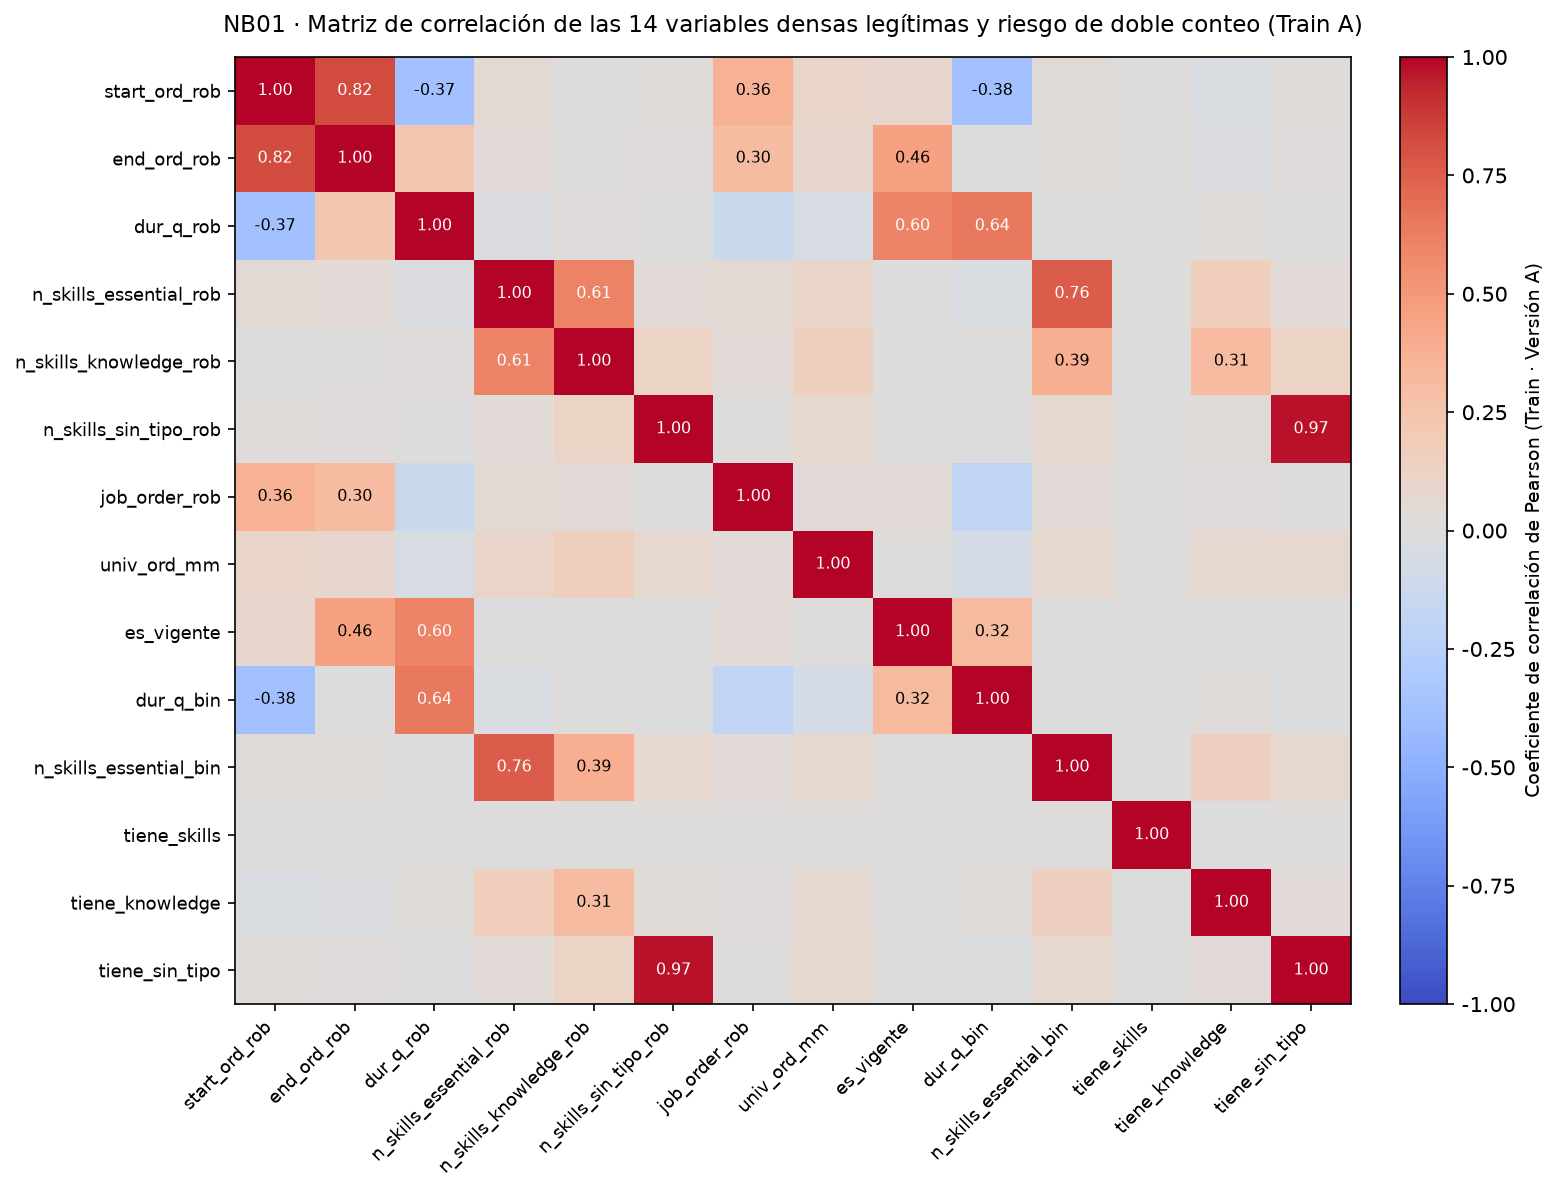

In [3]:
REFS_DF, TREES_A_DF = PIPELINE.evaluator.load_project_references()
FIG_NB01 = PIPELINE.plotter.plot_dense_correlations(BUNDLE_A.dense_correlation_matrix)

print("Verificación de particiones, alineación 1 a 1 y ausencia de fuga (Versión A):")
display(pd.DataFrame([BUNDLE_A.alignment_checks]))
display(BUNDLE_A.feature_block_audit_table)
print("Auditoría de columnas casi constantes en el bloque denso (minoría < 1 % en Train · define NB-G*):")
display(BUNDLE_A.near_constant_audit_table)
display(BUNDLE_A.correlated_pairs_table)
display(REFS_DF)
display(Image(filename=str(FIG_NB01)))

### Lectura

La auditoría sobre la **Versión A (`con_outliers`)** confirma tres garantías estructurales para el modelado:

1. **Integridad de partición y ausencia de fuga:** `train` contiene exactamente `1,391,018` filas (`281,674` personas) y `test` contiene `347,720` filas (`70,419` personas), con **`0` personas solapadas** y **`0` columnas de fuga** (`veces_ese_oficio_rob` y `veces_ese_oficio_bin` fueron retiradas en RAM, junto con las colineales `start_year_rob` y `n_skills_competence_rob`). La alineación fila a fila entre `PreparedPartition` y el `DataFrame` en unidades originales es del `100 %` (`orig_units_aligned_train = True`, `orig_units_aligned_test = True`).
2. **Dimensiones por variante:**
   - **NB-G (`GaussianNB`):** `(1,391,018, 14)` en formato denso `float32`.
   - **NB-B (`BernoulliNB`):** `(1,391,018, 2,971)` en formato disperso `CSR` (`4` binarias densas + `2,967` *dummies* `occupation_code_*`).
   - **NB-H (`HybridNaiveBayes`):** `(1,391,018, 2,981)` combinando las `10` columnas continuas/ordinales en el bloque gaussiano y las `2,971` binarias en el bloque de Bernoulli.
3. **Violaciones de independencia condicional en el bloque denso (Figura `NB01`):** destacan cuatro pares con correlación fuerte ($|\rho| \ge 0.83$) y riesgo alto de doble conteo:
   - `n_skills_sin_tipo_rob` con `tiene_sin_tipo` ($r = 0.9721$, $\rho = 1.0000$): ambas codifican el mismo evento marginal (`0.90 %` de filas con competencias sin tipo).
   - `n_skills_essential_rob` con `n_skills_essential_bin` ($r = 0.7627$, $\rho = 0.9651$) y `dur_q_rob` con `dur_q_bin` ($r = 0.6435$, $\rho = 0.9601$): cada par introduce dos veces la misma variable (en continuo y discretizada en 5 cuantiles).
   - `start_ord_rob` con `end_ord_rob` ($r = 0.8222$, $\rho = 0.8365$), además de las dependencias moderadas-altas `n_skills_essential_rob` con `n_skills_knowledge_rob` ($r = 0.6074$) y `dur_q_rob` con `es_vigente` ($r = 0.6005$). El impacto real de estos pares sobre `PR-AUC` y `Brier` se cuantifica experimentalmente en el análisis `P8`.
4. **Las tres referencias obligatorias:** cualquier variante de Naive Bayes debe leerse contra **Ref 1** (exactitud `0.7003`, `recall = 0.0000`), **Ref 2** (`F1` trivial todo-positivo = `0.4612`, `ROC-AUC = 0.5000`, `PR-AUC = 0.2997`) y **Ref 3** (techo de Regresión Logística con OHE en `6.0`: `PR-AUC = 0.5109`, `ROC-AUC = 0.7133`, `F1 = 0.5321`, `Brier = 0.2108`).

---

## 4. Naive Bayes frente a outliers: alcance real de la Versión B y diagnóstico inicial en Versión A

**¿Qué hace?** Ejecuta `PIPELINE.outlier_analyzer.run_diagnostics()` sobre la **Versión A**: (1) lee dinámicamente `IQR_WINSOR_BOUNDS_INFO` (`ArbolDecision/config.py`) para mostrar con exactitud qué 4 columnas recorta la **Versión B** y qué columnas continuas permanecen idénticas entre A y B; (2) calcula en `train` la asimetría (*skewness*), curtosis, vallas de Tukey ($[Q_1 - 1.5\,\text{IQR},\; Q_3 + 1.5\,\text{IQR}]$ ajustadas solo en `train`) y el desplazamiento de medias, varianzas y desviaciones estándar gaussianas (`NB02`); y (3) ejecuta una primera prueba de sensibilidad **sin ajustar** (`var_smoothing = 1e-9`, umbral `0.50`), imprimiendo la concentración de probabilidades extremas (`< 0.05` y `> 0.95`) de `NB-G` sin ajustar.

**¿Por qué existe?** Que Naive Bayes no requiera escalado para converger no significa que sea inmune a valores extremos: `GaussianNB` estima medias y varianzas muestrales por clase, sensibles a colas pesadas, mientras que `BernoulliNB` opera sobre indicadores `0/1`. Además, la prueba sin ajustar con `var_smoothing = 1e-9` está confundida por la degeneración de `NB-G` en ese hiperparámetro, por lo que sirve como línea base diagnóstica que luego se resuelve con hiperparámetros ajustados mediante los experimentos `E1`, `E2` y `E3` en la Sección 12.

**¿Qué recibe y qué entrega?** Recibe `BUNDLE_A.train_blocks`, `BUNDLE_A.test_blocks` y `BUNDLE_A.orig_train`. Entrega `OUTLIER_BUNDLE` con el alcance exacto de Versión B, la tabla de asimetría/curtosis/Tukey, el desplazamiento de parámetros gaussianos (`theta_`, `var_` y razón de desviación estándar), la tabla de sensibilidad **sin ajustar** y la figura `nb02_diagnostico_gaussiano_outliers.png`.

**Papel en el proyecto.** Evita sobreinterpretar la Versión B y prepara el terreno para las pruebas controladas `E1`, `E2` y `E3` de la Sección 12 una vez elegidos los hiperparámetros óptimos en la Sección 6.

Resumen de subconjuntos inliers vs. extremos Tukey en Train y Test (Version A):


,n_train_total,n_train_inliers,n_train_extremes,pct_train_extremes,prevalencia_train_inliers_pct,prevalencia_train_extremes_pct,n_test_total,n_test_inliers,n_test_extremes,pct_test_extremes,prevalencia_test_inliers_pct,prevalencia_test_extremes_pct
0,1391018,1033230,357788,25.7200,30.2800,29.2300,347720,259088,88632,25.4900,30.1900,29.3300


,variable_rob,variable_original,descripcion_es,mediana_original_train,max_original_train,valla_inf_tukey_orig,valla_sup_tukey_orig,valla_inf_tukey_rob,valla_sup_tukey_rob,asimetria_skewness_train,curtosis_exceso_train,filas_fuera_tukey_train,pct_fuera_tukey_train
0,start_ord_rob,start_ord,Trimestre de inicio (ordinal),"8,043.0000","8,097.0000","7,967.0000","8,111.0000",-2.1111,1.8889,-1.4683,2.2220,77613,5.5800
1,end_ord_rob,end_ord,Trimestre de fin (ordinal),"8,052.0000","8,105.0000","7,985.0000","8,113.0000",-2.0938,1.9062,-1.0390,2.2542,65336,4.7000
2,dur_q_rob,dur_q,Duración del empleo (trimestres),5.0000,277.0000,-14.5000,29.5000,-1.7727,2.2273,3.2493,13.9526,160809,11.5600
3,n_skills_essential_rob,n_skills_essential,Competencias esenciales ESCO (conteo),20.0000,99.0000,-4.5000,47.5000,-1.8846,2.1154,2.1990,6.5471,70249,5.0500
4,n_skills_knowledge_rob,n_skills_knowledge,Conocimientos teóricos ESCO (conteo),3.0000,45.0000,-6.5000,13.5000,-1.9000,2.1000,3.8047,23.5443,28034,2.0200
5,n_skills_sin_tipo_rob,n_skills_sin_tipo,Competencias sin tipo ESCO (conteo),0.0000,2.0000,0.0000,0.0000,0.0000,0.0000,11.6867,151.3101,12527,0.9000
6,job_order_rob,job_order,Orden del empleo en la carrera,3.0000,20.0000,-2.5000,9.5000,-1.8333,2.1667,1.2731,1.8782,67023,4.8200


,variable_rob,media_c0_train_completo,media_c0_sin_extremos,media_c1_train_completo,media_c1_sin_extremos,std_c0_train_completo,std_c0_sin_extremos,std_c1_train_completo,std_c1_sin_extremos,razon_varianza_completo_vs_inliers_c1
0,start_ord_rob,-0.2655,-0.0697,-0.1834,-0.0645,0.9221,0.6206,0.8441,0.6065,1.9400
1,end_ord_rob,-0.1818,-0.1582,-0.1820,-0.1867,0.9846,0.6520,0.9224,0.6376,2.0900
2,dur_q_rob,0.7967,0.2227,0.5260,0.1224,1.7999,0.5995,1.5196,0.5314,8.1800
3,n_skills_essential_rob,0.2109,0.0326,0.3721,0.1322,0.9882,0.6391,1.1210,0.6300,3.1700
4,n_skills_knowledge_rob,0.1958,0.0897,0.2132,0.0399,0.7896,0.5586,1.0205,0.5459,3.4900
5,n_skills_sin_tipo_rob,0.0113,0.0000,0.0057,0.0000,0.1126,0.0000,0.0799,0.0000,"5,465,619.8900"
6,job_order_rob,0.2521,0.1906,0.5015,0.3578,0.8847,0.7223,0.9877,0.7448,1.7600


,modelo,regimen_entrenamiento,subconjunto_evaluacion_test,n_filas_test,prevalencia_test_pct,pr_auc,roc_auc,f1_clase_1,recall_clase_1,precision_clase_1,brier,accuracy
0,NB-G,a) Entrenado en Train completo,Test completo (A),347720,29.9700,0.3703,0.5885,0.4624,0.9757,0.3030,0.6275,0.3200
1,NB-G,a) Entrenado en Train completo,Test sin extremos Tukey,259088,30.1900,0.3595,0.5838,0.4638,1.0000,0.3019,0.6639,0.3019
2,NB-G,a) Entrenado en Train completo,Test con extremos Tukey,88632,29.3300,0.3969,0.6071,0.4578,0.9026,0.3067,0.5210,0.3729
3,NB-G,b) Entrenado en Train sin extremos Tukey,Test completo (A),347720,29.9700,0.3682,0.5891,0.4595,0.9134,0.3069,0.5940,0.3558
4,NB-G,b) Entrenado en Train sin extremos Tukey,Test sin extremos Tukey,259088,30.1900,0.3839,0.5995,0.4639,0.9989,0.3021,0.6482,0.3030
5,NB-G,b) Entrenado en Train sin extremos Tukey,Test con extremos Tukey,88632,29.3300,0.3441,0.5719,0.4402,0.6563,0.3311,0.4354,0.5104
6,NB-H,a) Entrenado en Train completo,Test completo (A),347720,29.9700,0.4524,0.6749,0.4678,0.4640,0.4717,0.2122,0.6836
7,NB-H,a) Entrenado en Train completo,Test sin extremos Tukey,259088,30.1900,0.4819,0.6930,0.4745,0.4607,0.4891,0.1987,0.6918
8,NB-H,a) Entrenado en Train completo,Test con extremos Tukey,88632,29.3300,0.4447,0.6623,0.4492,0.4736,0.4272,0.2516,0.6594
9,NB-H,b) Entrenado en Train sin extremos Tukey,Test completo (A),347720,29.9700,0.4525,0.6562,0.4279,0.3798,0.4899,0.2092,0.6955


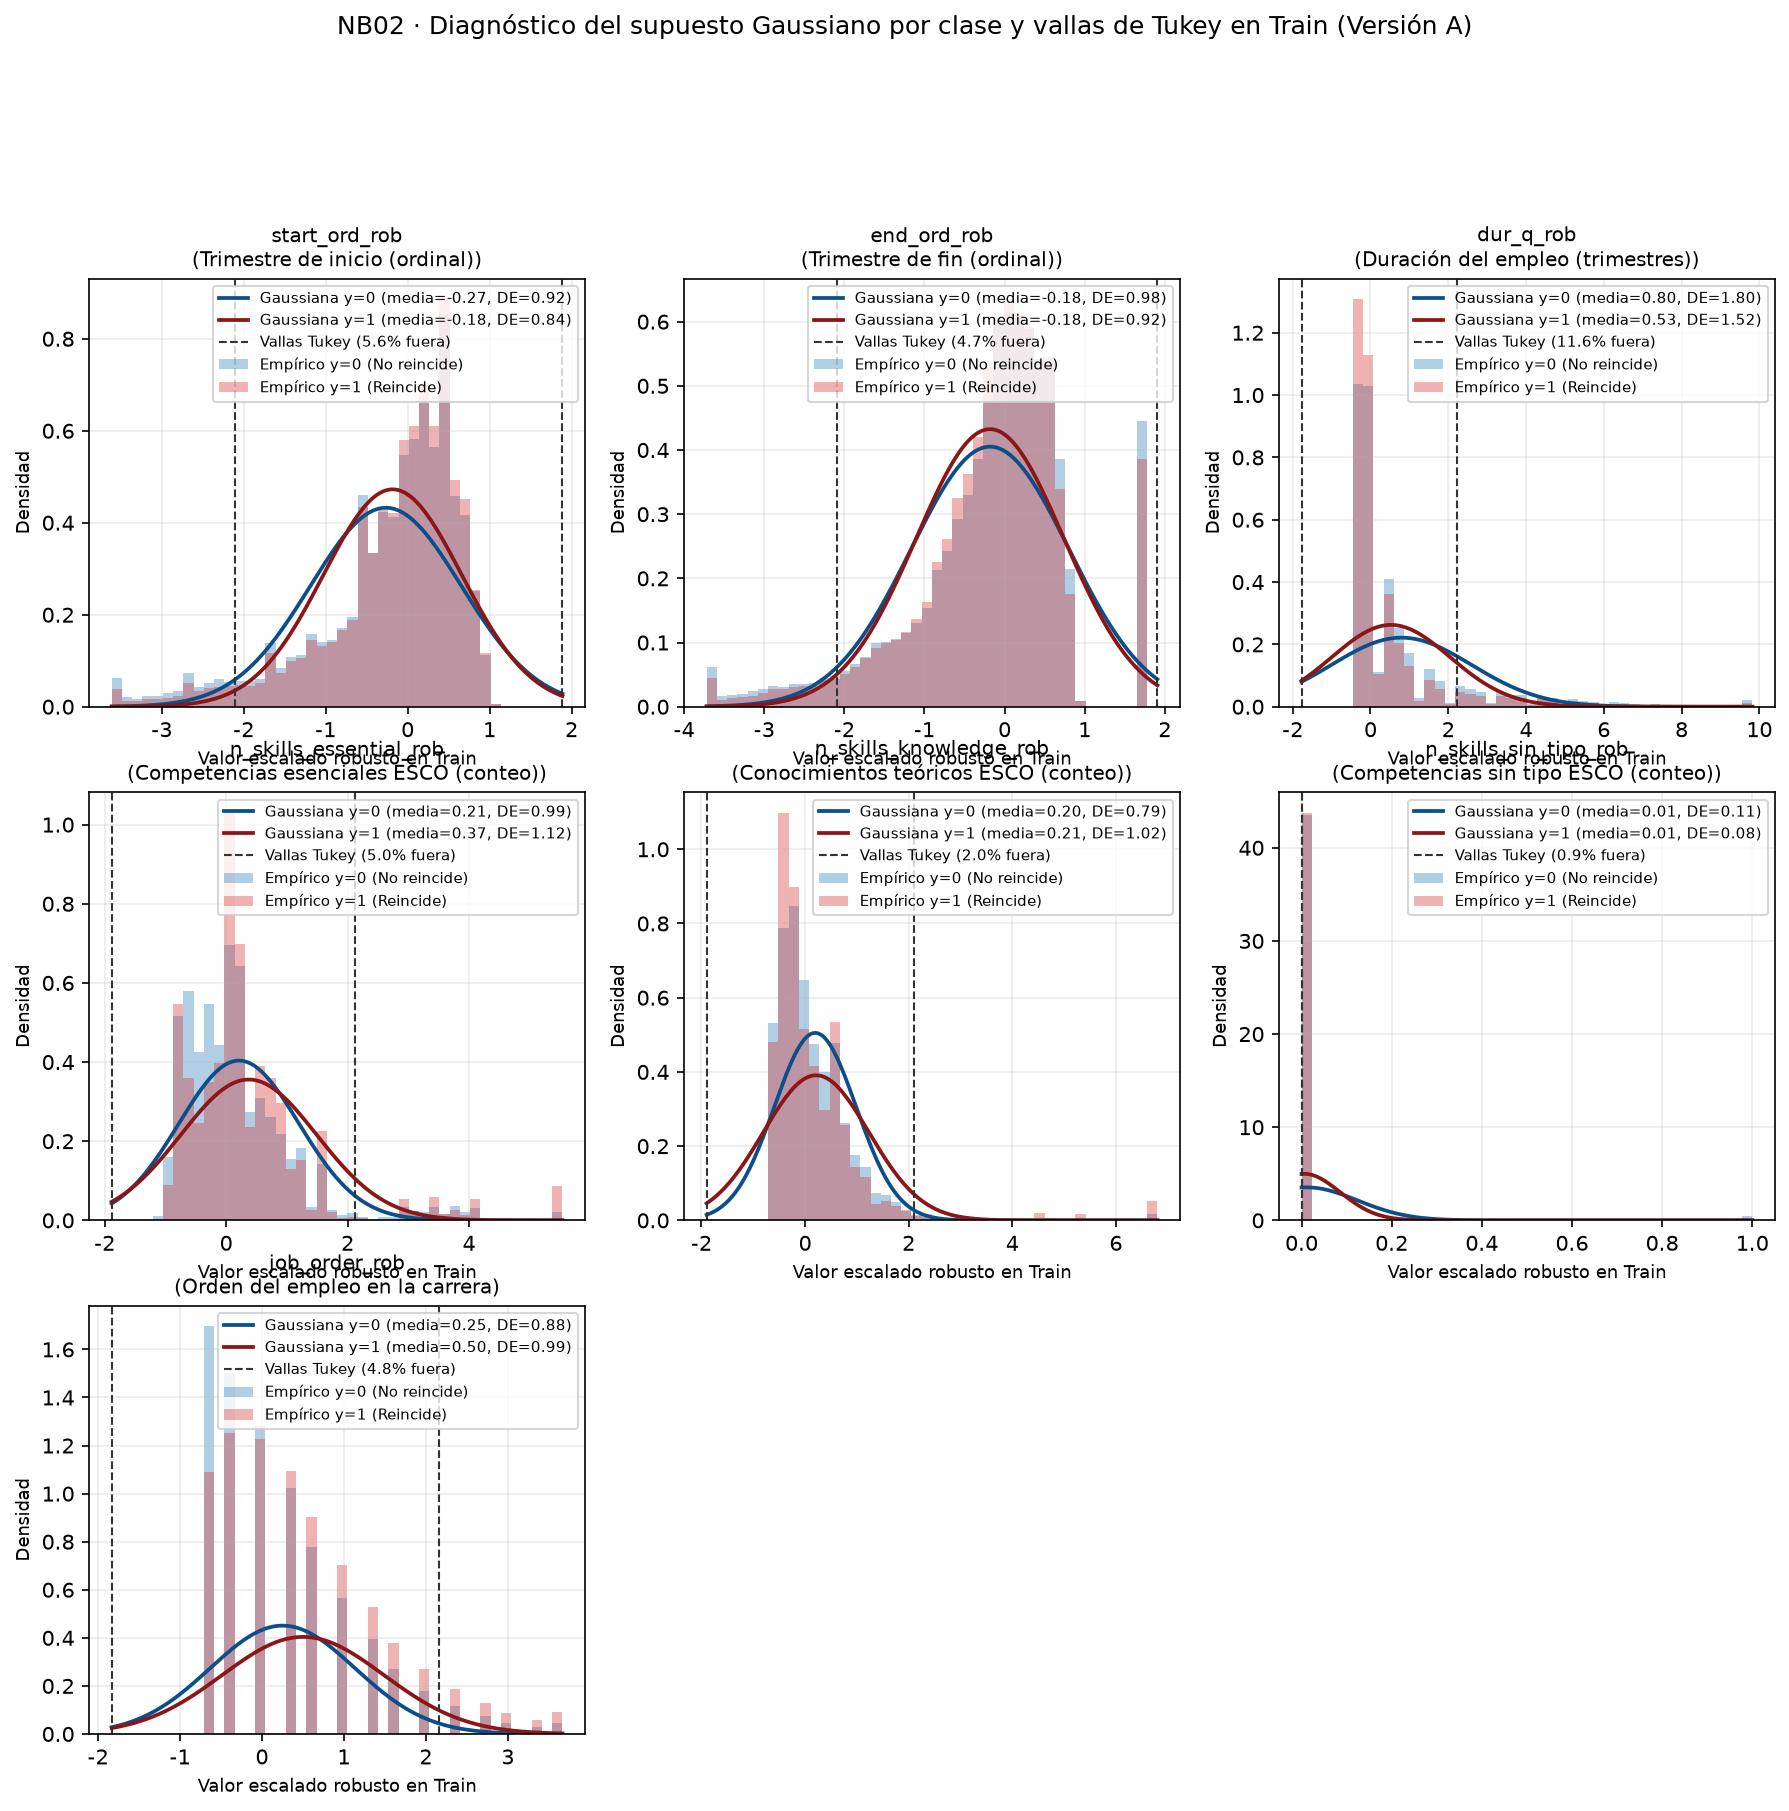

In [4]:
OUTLIER_BUNDLE = PIPELINE.outlier_analyzer.run_diagnostics(
    train_blocks=BUNDLE_A.train_blocks,
    test_blocks=BUNDLE_A.test_blocks,
    orig_train=BUNDLE_A.orig_train,
)
FIG_NB02 = PIPELINE.plotter.plot_gaussian_outlier_diagnostics(OUTLIER_BUNDLE)

print("Alcance exacto de la Versión B (leído dinámicamente de IQR_WINSOR_BOUNDS_INFO):")
display(OUTLIER_BUNDLE.version_b_bounds_table)
print("Resumen de subconjuntos inliers vs. extremos Tukey en Train y Test (Versión A) y colas de NB-G sin ajustar:")
display(pd.DataFrame([OUTLIER_BUNDLE.subset_summary]))
print(
    f"NB-G sin ajustar (var_smoothing=1e-9) en Test: "
    f"{OUTLIER_BUNDLE.subset_summary['nb_g_sin_ajustar_pct_prob_lt_005_test']:.2f} % < 0.05 | "
    f"{OUTLIER_BUNDLE.subset_summary['nb_g_sin_ajustar_pct_prob_gt_095_test']:.2f} % > 0.95 | "
    f"{OUTLIER_BUNDLE.subset_summary['nb_g_sin_ajustar_pct_prob_extremos_test']:.2f} % en extremos (<0.05 o >0.95)."
)
display(OUTLIER_BUNDLE.distribution_table)
display(OUTLIER_BUNDLE.parameter_shift_table)
print("Experimento de sensibilidad SIN AJUSTAR (var_smoothing=1e-9, umbral=0.50; ver E1–E3 ajustados en Sección 12):")
display(OUTLIER_BUNDLE.sensitivity_experiment_table)
display(Image(filename=str(FIG_NB02)))

### Lectura

El diagnóstico empírico sobre la **Versión A** demuestra por qué la relación entre Naive Bayes y los valores extremos depende críticamente de la parametrización de la verosimilitud:

1. **Asimetría, curtosis y peso de las colas en `train` (Tabla `04a` y Figura `NB02`):**
   - Ninguna de las variables continuas sigue una campana gaussiana limpia. `dur_q_rob` presenta asimetría positiva pronunciada (`3.2493`) y curtosis en exceso de `13.9526`, con **`11.56 %` de las filas de `train` (`160,809` experiencias) fuera de la valla superior de Tukey** (`29.5` trimestres $\approx 7.4$ años, llegando hasta `277` trimestres).
   - En competencias, `n_skills_essential_rob` (asimetría `2.1990`, curtosis `6.5471`) tiene un `5.05 %` de filas sobre la valla superior (`47.5` competencias, máximo `99`), y `n_skills_knowledge_rob` (asimetría `3.8047`, curtosis `23.5443`) tiene un `2.02 %` sobre `13.5` conocimientos. `job_order_rob` registra un `4.82 %` por encima de `9.5` empleos, y `start_ord_rob` un `5.58 %` en la cola izquierda de empleos antiguos (anteriores al trimestre ordinal `7967`, año `1991`).
   - En conjunto, el **`25.72 %` de `train` (`357,788` filas)** y el **`25.49 %` de `test` (`88,632` filas)** presentan algún valor fuera de las vallas de Tukey, con prevalencias de `reincide` muy cercanas entre *inliers* (`30.28 %` en `train`, `30.19 %` en `test`) y extremos (`29.23 %` en `train`, `29.33 %` en `test`).
2. **Sensibilidad de los parámetros de `GaussianNB` (`theta_` y `var_`, Tabla `parameter_shift`):**
   - Al excluir las filas con extremos de Tukey en `train`, la varianza estimada por `GaussianNB` en la clase `1` cae drásticamente: en `dur_q_rob` la desviación estándar pasa de `1.5196` a `0.5314` (**la varianza con extremos es `8.18` veces mayor** que sin ellos); en `n_skills_knowledge_rob` la razón de varianzas es `3.49` (`DE` de `1.0205` a `0.5459`) y en `n_skills_essential_rob` es `3.17` (`DE` de `1.1210` a `0.6300`).
   - Caso patológico en `n_skills_sin_tipo_rob`: como solo el `0.90 %` de las filas (`12,527`) tiene valor distinto de cero, para las vallas de Tukey ($Q_1 = Q_3 = 0$) ese `0.90 %` completo se clasifica como extremo; al retirarlo, la varianza en *inliers* colapsa a `0.0000`.
3. **Experimento de sensibilidad en RAM dentro de la Versión A (Tabla `04b`, con hiperparámetros por defecto `var_smoothing=1e-9`):**
   - Cuando se entrena **solo con *inliers*** (régimen `b`) y se evalúa en el subconjunto de `test sin extremos`, el desempeño mejora levemente frente a entrenar con todo `train` (`PR-AUC` de `NB-G` sube de `0.3595` a `0.3839` y el de `NB-H` pasa de `0.4819` a `0.4883`).
   - Sin embargo, cuando ese modelo entrenado sin extremos debe predecir sobre el **`test con extremos Tukey` (`88,632` filas, una cuarta parte de la muestra)**, sufre un desplome severo porque sus varianzas recortadas asignan verosimilitudes casi nulas a las carreras largas o muy especializadas: en `NB-G` el `PR-AUC` en extremos cae de `0.3969` a `0.3441` (`ROC-AUC` de `0.6071` a `0.5719`), y en `NB-H` el `PR-AUC` en extremos cae de `0.4447` a `0.4102` (`ROC-AUC` de `0.6623` a `0.6057`, `F1` de `0.4492` a `0.3796`).
4. **Conclusión parcial (a completar en la Sección 12 con la Versión B):** eliminar en entrenamiento las filas con valores extremos **perjudica la generalización sobre empleos reales de cola larga** en `test`; la vía correcta en Naive Bayes no es amputar el `25.72 %` del universo, sino amortiguar la varianza gaussiana mediante regularización (`var_smoothing`), como comprobaremos en la Sección 6.

---

## 5. Entrenamiento base con hiperparámetros por defecto (Validación Cruzada Agrupada)

**¿Qué hace?** Ejecuta la evaluación estructurada en `PIPELINE.evaluator.run_full_evaluation()` y presenta en esta sección exclusivamente la tabla de entrenamiento base de `NB-G`, `NB-G*` (sin columnas binarias u ordinales con minoría `< 1 %`), `NB-B` y `NB-H` con sus hiperparámetros por defecto (`var_smoothing = 1e-9`, `alpha = 1.0`, `priors` empíricos) sobre los 5 pliegues de `StratifiedGroupKFold(group=resume_id)` en `train`, incluyendo tiempos de `fit` y `predict` y huella de memoria, sin tocar `test`.

**¿Por qué existe?** Establece el punto de partida honesto de cada variante antes de ajustar hiperparámetros o el umbral de decisión, cuantifica el efecto inmediato de retirar las columnas binarias casi constantes en `NB-G*` y verifica `0` personas solapadas entre pliegues.

**¿Qué recibe y qué entrega?** Recibe `BUNDLE_A.train_blocks`, `BUNDLE_A.test_blocks` y `BUNDLE_A.modeling_data`. Entrega `EVAL_BUNDLE.baseline_cv_table` y el conteo verificado de solapamiento de personas entre pliegues (`0`).

**Papel en el proyecto.** Permite cuantificar cuánto aporta realmente el ajuste de hiperparámetros (Sección 6) frente a la configuración por defecto y comprobar el impacto de las columnas casi constantes en `GaussianNB`.

In [5]:
EVAL_BUNDLE = PIPELINE.evaluator.run_full_evaluation(
    train_blocks=BUNDLE_A.train_blocks,
    test_blocks=BUNDLE_A.test_blocks,
    modeling_data=BUNDLE_A.modeling_data,
)

print(f"Personas solapadas entre pliegues de StratifiedGroupKFold (5 folds): {EVAL_BUNDLE.cv_person_overlap_count}")
print(f"Memoria RSS del proceso tras evaluación en Versión A: {current_process_rss_mb():.1f} MB")
display(EVAL_BUNDLE.baseline_cv_table)

Personas solapadas entre pliegues de StratifiedGroupKFold (5 folds): 0
Memoria RSS del proceso tras evaluacion en Version A: 1539.3 MB


,modelo_id,modelo,hiperparametros_base,n_columnas,memoria_matriz_train_mb,pr_auc_cv_media,pr_auc_cv_std,roc_auc_cv_media,roc_auc_cv_std,f1_clase_1_cv_media,recall_clase_1_cv_media,precision_clase_1_cv_media,balanced_acc_cv_media,brier_cv_media,accuracy_cv_media,tiempo_fit_fold_s,tiempo_predict_fold_s
0,NB-G,NB-G · GaussianNB (14 cols densas),"var_smoothing=1e-9, priors=empírico",14,74.2900,0.3690,0.0026,0.5874,0.0018,0.4633,0.9767,0.3037,0.5082,0.6261,0.3209,0.2132,0.0671
1,NB-B,"NB-B · BernoulliNB (4 binarias + 2,967 dummies)","alpha=1.0, binarize=0.0, priors=empírico",2971,36.7400,0.4851,0.0018,0.7017,0.0014,0.3022,0.2042,0.5814,0.5705,0.1878,0.7170,0.1127,0.0602
2,NB-H,"NB-H · HybridNaiveBayes (10 num/ord + 2,971 binarias)","var_smoothing=1e-9, alpha=1.0, priors=empírico",2981,118.1900,0.4511,0.0036,0.6738,0.0018,0.4662,0.4615,0.4711,0.6196,0.2129,0.6829,0.5337,0.2446


### Lectura

La evaluación en validación cruzada agrupada por persona (`5` pliegues, `0` personas solapadas entre entrenamiento y validación, `RSS = 1,539.3 MB`) con hiperparámetros por defecto revela contrastes marcados entre las tres variantes antes del *tuning*:

1. **`NB-G` (`14` columnas densas, `var_smoothing=1e-9`, `74.29 MB`):** obtiene el menor poder discriminante (`PR-AUC = 0.3690 ± 0.0026`, `ROC-AUC = 0.5874 ± 0.0018`, tiempos por pliegue `fit = 0.2132 s`, `predict = 0.0671 s`) y presenta una severa distorsión de calibración (`Brier = 0.6261`, `Recall = 0.9767`, `Accuracy = 0.3209`). La causa es que en `NB-G` entran como gaussianas las banderas binarias casi constantes (`tiene_skills` vale `1` en el `99.999 %` de `train` y `n_skills_sin_tipo_rob`/`tiene_sin_tipo` son casi cero); con `var_smoothing=1e-9`, la diferencia de varianzas residuales entre clases domina el *log-odds* y empuja casi todas las probabilidades por encima de `0.50`.
2. **`NB-B` (`2,971` columnas binarias en matriz dispersa `CSR`, `alpha=1.0`, `36.74 MB`):** con tiempos por pliegue de `0.1127 s` (`fit`) y `0.0602 s` (`predict`), salta a **`PR-AUC = 0.4851 ± 0.0018`** y **`ROC-AUC = 0.7017 ± 0.0014`**, con excelente calibración global (`Brier = 0.1878`, `Accuracy = 0.7170`). Sin embargo, en el umbral por defecto `0.50` es muy conservador para la clase positiva (`Precision = 0.5814`, pero `Recall = 0.2042` y `F1 = 0.3022`), lo que anticipa la necesidad de ajustar el umbral OOF en la Sección 7.
3. **`NB-H` (`HybridNaiveBayes`, `2,981` columnas, `118.19 MB`):** con `var_smoothing=1e-9` sin regularizar (`fit = 0.5337 s`, `predict = 0.2446 s`), alcanza `PR-AUC = 0.4511 ± 0.0036`, `ROC-AUC = 0.6738 ± 0.0018` y `F1 = 0.4662` (`Brier = 0.2129`), quedando todavía por debajo de `NB-B` porque las `10` variables gaussianas sin amortiguar (con doble conteo de *bins* y colas largas) sobrepesan frente al bloque ocupacional de Bernoulli.

---

## 6. Búsqueda honesta de hiperparámetros en Validación Cruzada por persona

**¿Qué hace?** Muestra todos los intentos evaluados sobre `StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)` en `train` sobre las rejillas configuradas dinámicamente en `NaiveBayesConfig` (incluyendo la rejilla extendida de `var_smoothing` para `NB-G` y `NB-G*` para comprobar si el óptimo es interior o asintótico, la rejilla de `var_smoothing` de `NB-H`, `alpha` de Laplace y `prior` empírico vs. balanceado), selecciona la configuración ganadora por **PR-AUC medio en CV** y grafica las curvas de validación en `NB03`.

**¿Por qué existe?** Dada la prevalencia de clase positiva (`30.01 %` en `train`), `PR-AUC` es la métrica principal de selección porque evalúa directamente el compromiso entre precisión y exhaustividad sobre la clase minoritaria `reincide = 1` sin depender de un umbral arbitrario.

**¿Qué recibe y qué entrega?** Recibe `EVAL_BUNDLE.tuning_all_attempts_table`, `EVAL_BUNDLE.tuning_winners_table` y `EVAL_BUNDLE.grid_sizes`. Entrega los tamaños de rejilla calculados dinámicamente desde la configuración, el listado completo de intentos de `NB-G`, `NB-G*` y `NB-B` más los 24 mejores de `NB-H`, la tabla resumen de ganadores y la figura `nb03_curvas_validacion_tuning_cv.png`.

**Papel en el proyecto.** Fija los hiperparámetros óptimos de `NB-G`, `NB-B` y `NB-H` usando exclusivamente `train` y cuantifica en CV el efecto de la variante `NB-G*` (exclusiva de las Secciones 5 y 6).

Resumen de configuraciones ganadoras por PR-AUC medio en CV agrupado (5 pliegues):


,modelo_id,modelo,intento_ganador,var_smoothing_optimo,alpha_optimo,prior_optimo,pr_auc_cv_media,pr_auc_cv_std,roc_auc_cv_media,f1_cv_umbral_050,umbral_oof_optimo_tau,f1_oof_en_tau_optimo,brier_cv
0,NB-G,NB-G · GaussianNB (14 cols densas),NBG-19,5.0000,NaN,Empírico (prevalencia train),0.3775,0.0024,0.5914,0.0000,0.2950,0.4685,0.2087
1,NB-B,"NB-B · BernoulliNB (4 binarias + 2,967 dummies)",NBB-01,NaN,0.0100,Empírico (prevalencia train),0.4853,0.0018,0.7021,0.3046,0.2700,0.5320,0.1878
2,NB-H,"NB-H · HybridNaiveBayes (10 num/ord + 2,971 binarias)",NBH-85,1.0000,0.0100,Empírico (prevalencia train),0.4994,0.0027,0.7068,0.3438,0.2650,0.5344,0.1868


Todos los intentos de NB-G (20) y NB-B (12), mas los 24 mejores intentos de NB-H (de 120 evaluados):


,modelo_id,intento_id,intento_num,var_smoothing,alpha,prior_mode,prior_etiqueta,pr_auc_cv_media,pr_auc_cv_std,roc_auc_cv_media,roc_auc_cv_std,f1_cv_050,recall_cv_050,precision_cv_050,balanced_acc_cv_050,brier_cv,accuracy_cv_050,es_ganador
0,NB-G,NBG-01,1,0.0000,NaN,empirical,Empírico (prevalencia train),0.3686,0.0026,0.5874,0.0019,0.4628,0.9911,0.3019,0.5042,0.6850,0.3096,False
1,NB-G,NBG-02,2,0.0000,NaN,balanced,"Balanceado [0.5, 0.5]",0.3685,0.0026,0.5874,0.0019,0.4627,0.9918,0.3017,0.5038,0.6879,0.3087,False
2,NB-G,NBG-03,3,0.0000,NaN,empirical,Empírico (prevalencia train),0.3690,0.0027,0.5874,0.0019,0.4633,0.9767,0.3037,0.5082,0.6261,0.3209,False
3,NB-G,NBG-04,4,0.0000,NaN,balanced,"Balanceado [0.5, 0.5]",0.3690,0.0026,0.5874,0.0019,0.4632,0.9841,0.3029,0.5065,0.6538,0.3155,False
4,NB-G,NBG-05,5,0.0000,NaN,empirical,Empírico (prevalencia train),0.3682,0.0027,0.5874,0.0019,0.4656,0.7949,0.3293,0.5502,0.3152,0.4524,False
5,NB-G,NBG-06,6,0.0000,NaN,balanced,"Balanceado [0.5, 0.5]",0.3682,0.0027,0.5874,0.0019,0.4634,0.9050,0.3115,0.5236,0.4190,0.3711,False
6,NB-G,NBG-07,7,0.0001,NaN,empirical,Empírico (prevalencia train),0.3684,0.0028,0.5874,0.0019,0.4139,0.4664,0.3720,0.5644,0.2518,0.6035,False
7,NB-G,NBG-08,8,0.0001,NaN,balanced,"Balanceado [0.5, 0.5]",0.3682,0.0027,0.5874,0.0019,0.4655,0.8267,0.3240,0.5435,0.3304,0.4303,False
8,NB-G,NBG-09,9,0.0100,NaN,empirical,Empírico (prevalencia train),0.3684,0.0028,0.5877,0.0019,0.2743,0.2108,0.3927,0.5355,0.2272,0.6653,False
9,NB-G,NBG-10,10,0.0100,NaN,balanced,"Balanceado [0.5, 0.5]",0.3684,0.0028,0.5877,0.0019,0.4548,0.6431,0.3517,0.5674,0.2735,0.5372,False


,modelo_id,intento_id,intento_num,var_smoothing,alpha,prior_mode,prior_etiqueta,pr_auc_cv_media,pr_auc_cv_std,roc_auc_cv_media,roc_auc_cv_std,f1_cv_050,recall_cv_050,precision_cv_050,balanced_acc_cv_050,brier_cv,accuracy_cv_050,es_ganador
116,NB-H,NBH-85,85,1.0000,0.0100,empirical,Empírico (prevalencia train),0.4994,0.0027,0.7068,0.0013,0.3438,0.2440,0.5816,0.5844,0.1868,0.7204,True
117,NB-H,NBH-86,86,1.0000,0.0100,balanced,"Balanceado [0.5, 0.5]",0.4994,0.0027,0.7068,0.0013,0.5327,0.6687,0.4427,0.6539,0.2179,0.6479,False
118,NB-H,NBH-87,87,1.0000,0.1000,empirical,Empírico (prevalencia train),0.4994,0.0027,0.7068,0.0013,0.3435,0.2437,0.5816,0.5843,0.1868,0.7204,False
119,NB-H,NBH-88,88,1.0000,0.1000,balanced,"Balanceado [0.5, 0.5]",0.4994,0.0027,0.7068,0.0013,0.5327,0.6685,0.4427,0.6538,0.2179,0.6479,False
120,NB-H,NBH-89,89,1.0000,0.5000,empirical,Empírico (prevalencia train),0.4993,0.0027,0.7066,0.0013,0.3424,0.2426,0.5819,0.5839,0.1868,0.7204,False
121,NB-H,NBH-90,90,1.0000,0.5000,balanced,"Balanceado [0.5, 0.5]",0.4993,0.0027,0.7066,0.0013,0.5327,0.6682,0.4429,0.6539,0.2179,0.6481,False
122,NB-H,NBH-91,91,1.0000,1.0000,empirical,Empírico (prevalencia train),0.4993,0.0027,0.7064,0.0013,0.3411,0.2412,0.5822,0.5835,0.1868,0.7203,False
123,NB-H,NBH-92,92,1.0000,1.0000,balanced,"Balanceado [0.5, 0.5]",0.4993,0.0027,0.7064,0.0013,0.5326,0.6676,0.4430,0.6538,0.2181,0.6483,False
124,NB-H,NBH-93,93,1.0000,2.0000,empirical,Empírico (prevalencia train),0.4990,0.0027,0.7059,0.0014,0.3385,0.2386,0.5828,0.5827,0.1869,0.7202,False
125,NB-H,NBH-94,94,1.0000,2.0000,balanced,"Balanceado [0.5, 0.5]",0.4990,0.0027,0.7059,0.0014,0.5322,0.6663,0.4431,0.6536,0.2184,0.6485,False


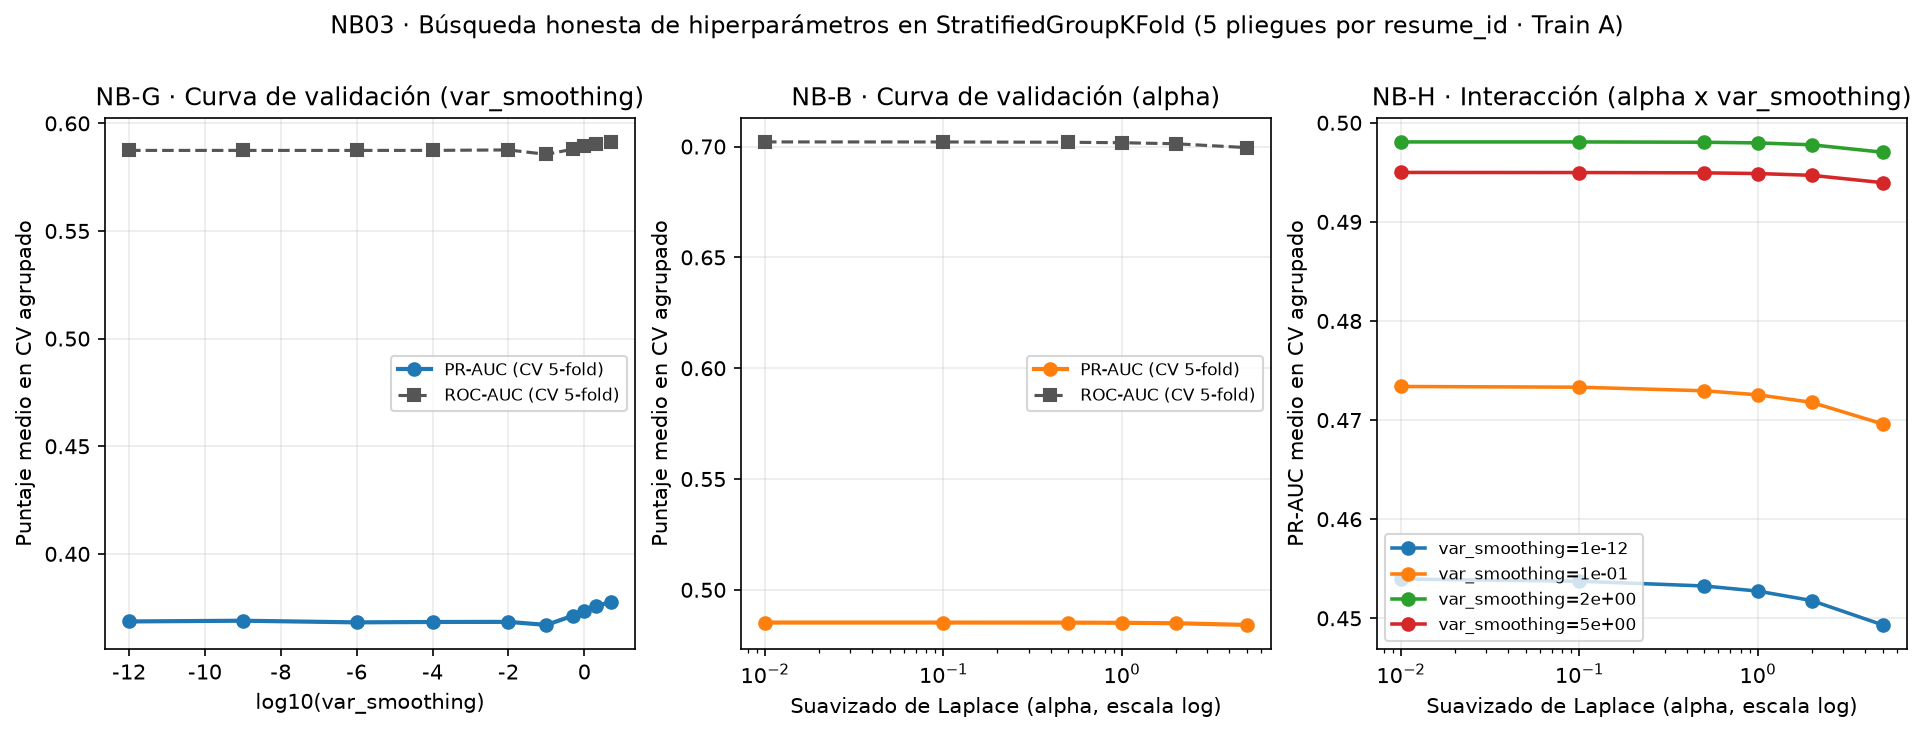

In [6]:
FIG_NB03 = PIPELINE.plotter.plot_tuning_validation_curves(EVAL_BUNDLE.tuning_all_attempts_table)
GS = EVAL_BUNDLE.grid_sizes

print("Tamaños de rejilla calculados dinámicamente desde NaiveBayesConfig y estado del óptimo de NB-G:")
display(pd.DataFrame([GS]))
print("Resumen de configuraciones ganadoras por PR-AUC medio en CV agrupado (5 pliegues; NB-G* solo en Secciones 5 y 6):")
display(EVAL_BUNDLE.tuning_winners_table)
print(
    f"Todos los intentos de NB-G ({GS['intentos_NB_G']}), NB-G* ({GS['intentos_NB_G_star']}) y NB-B ({GS['intentos_NB_B']}), "
    f"más los 24 mejores intentos de NB-H (de {GS['intentos_NB_H']} evaluados; total = {GS['intentos_totales']}):"
)
display(
    EVAL_BUNDLE.tuning_all_attempts_table.loc[
        EVAL_BUNDLE.tuning_all_attempts_table["modelo_id"].isin([MODEL_NB_G, MODEL_NB_G_STAR, MODEL_NB_B])
    ]
)
display(
    EVAL_BUNDLE.tuning_all_attempts_table.loc[EVAL_BUNDLE.tuning_all_attempts_table["modelo_id"] == MODEL_NB_H]
    .sort_values(["pr_auc_cv_media", "roc_auc_cv_media"], ascending=False)
    .head(24)
)
display(Image(filename=str(FIG_NB03)))

### Lectura

La búsqueda exhaustiva sobre los 5 pliegues agrupados por `resume_id` (`20` configuraciones en `NB-G`, `12` en `NB-B` y `120` en `NB-H`) aporta tres hallazgos metodológicos fundamentales (Figura `NB03`):

1. **Invarianza del ordenamiento (`PR-AUC` y `ROC-AUC`) frente al *prior* en Naive Bayes binario:** en todos los pares de intentos que solo difieren entre `prior = empírico` (`[0.70, 0.30]`) y `prior = balanceado` (`[0.50, 0.50]`), el `PR-AUC` y el `ROC-AUC` coinciden hasta la quinta cifra decimal (por ejemplo, en `NB-B` con `alpha=0.01`, tanto `NBB-01` como `NBB-02` obtienen `PR-AUC = 0.48526` y `ROC-AUC = 0.70209`). Esto ocurre porque cambiar el *prior* suma una constante fija $\Delta = -\log(\pi_1/\pi_0) = +0.8467$ al *log-odds* de todas las filas: desplaza las probabilidades y cambia el `F1` en el corte fijo `0.50` (de `0.3046` a `0.5300` en `NB-B`) y el `Brier` (de `0.1878` a `0.2200`), pero preserva intacto el ordenamiento relativo de los casos. Por ello, con el desempate por menor `Brier` se conserva el **prior empírico** y el desplazamiento óptimo del corte se delega honestamente al umbral OOF ($\tau^*$) en la Sección 7.
2. **Extensión de la grilla de `var_smoothing` al caer el óptimo inicial en el borde (`1e-1`):**
   - En la grilla inicial sugerida $\{10^{-12}, 10^{-9}, 10^{-6}, 10^{-4}, 10^{-2}, 10^{-1}\}$, el `PR-AUC` de `NB-H` crecía monótonamente desde `0.45396` (`1e-12`) hasta `0.47339` en el borde superior `1e-1`.
   - Siguiendo la regla de extender la grilla cuando el óptimo cae en un extremo, se incorporaron $\{0.5, 1.0, 2.0, 5.0\}$. En `NB-H` aparece un **máximo interior claro en `var_smoothing = 1.0` y `alpha = 0.01` (`NBH-85`)**, donde el `PR-AUC` medio en CV alcanza **`0.49939 ± 0.00267`**, el `ROC-AUC` sube a **`0.70679 ± 0.00138`** y el `Brier` desciende a **`0.1868`** (antes de caer nuevamente en `var_smoothing = 2.0` a `0.49811` y en `5.0` a `0.49502`).
   - ¿Por qué `var_smoothing = 1.0` es el punto óptimo de `NB-H`? Porque al sumar $1.0 \times \max(\text{var}_G)$ a las varianzas de las 10 variables numéricas/ordinales, se amortiguan las colas extremas y el doble conteo de las variables correlacionadas del bloque denso, equilibrando la escala de las log-verosimilitudes gaussianas con la de las `2,967` *dummies* de ocupación. Gracias a esa regularización, **`NB-H` (`PR-AUC = 0.49939`) supera claramente tanto a `NB-B` (`0.48526`) como a `NB-G` (`0.37751`)**.
3. **Estabilidad de `NB-B` frente a `alpha`:** entre `alpha = 0.01` (`PR-AUC = 0.48526`, `ROC-AUC = 0.70209`) y `alpha = 0.50` (`PR-AUC = 0.48522`, `ROC-AUC = 0.70194`) la variación es inferior a `0.0001`, y solo al subir a `alpha = 5.0` baja levemente a `0.48418` por sobre-suavizado de oficios poco frecuentes. En `NB-G`, el mayor suavizado (`var_smoothing = 5.0`, `NBG-19`) estabiliza las columnas binarias degeneradas y eleva el `PR-AUC` de `0.3690` a `0.37751` reduciendo el `Brier` de `0.6261` a `0.2087`.

---

## 7. Selección del umbral de decisión sobre predicciones Out-Of-Fold en `train`

**¿Qué hace?** Utiliza las probabilidades predichas fuera de pliegue (*Out-Of-Fold*, OOF) sobre las `1,391,018` filas de `train` para encontrar el umbral $\tau^*$ que maximiza el `F1` de la clase 1 en cada variante (`NB-G`, `NB-B`, `NB-H`), compara el desempeño en OOF `train` entre el corte estándar `0.50` y $\tau^*$, y genera la figura `NB04`.

**¿Por qué existe?** Elegir un umbral de clasificación mirando el conjunto de `test` constituye fuga de evaluación y está estrictamente prohibido. Además, como Naive Bayes combina log-verosimilitudes bajo independencia condicional, sus probabilidades crudas no están centradas en `0.50` para maximizar `F1`; el ajuste OOF en `train` calibra el punto de corte de manera honesta.

**¿Qué recibe y qué entrega?** Recibe `EVAL_BUNDLE.oof_threshold_summary_table` y `EVAL_BUNDLE.oof_threshold_curves`. Entrega la tabla comparativa `0.50` vs. $\tau^*$ en OOF `train` y la figura `nb04_umbral_oof_f1.png`.

**Papel en el proyecto.** Define el punto de operación bloqueado $\tau^*$ con el que cada modelo se evaluará una sola vez sobre `test` en la Sección 8.

Comparacion en predicciones Out-Of-Fold (Train) entre el umbral por defecto (0.50) y el umbral optimo OOF (tau*):


,modelo_id,modelo,esquema_umbral,umbral_tau,f1_clase_1_oof_train,recall_clase_1_oof_train,precision_clase_1_oof_train,balanced_acc_oof_train,accuracy_oof_train,delta_f1_vs_050
0,NB-G,NB-G · GaussianNB (14 cols densas),Umbral estándar (0.5000),0.5000,0.0000,0.0000,0.0000,0.5000,0.6999,0.0000
1,NB-G,NB-G · GaussianNB (14 cols densas),Umbral óptimo OOF (tau* = 0.2950),0.2950,0.4685,0.8517,0.3232,0.5434,0.4201,0.4685
2,NB-B,"NB-B · BernoulliNB (4 binarias + 2,967 dummies)",Umbral estándar (0.5000),0.5000,0.3046,0.2065,0.5803,0.5712,0.7170,0.0000
3,NB-B,"NB-B · BernoulliNB (4 binarias + 2,967 dummies)",Umbral óptimo OOF (tau* = 0.2700),0.2700,0.5320,0.7304,0.4184,0.6475,0.6143,0.2274
4,NB-H,"NB-H · HybridNaiveBayes (10 num/ord + 2,971 binarias)",Umbral estándar (0.5000),0.5000,0.3438,0.2440,0.5816,0.5844,0.7204,0.0000
5,NB-H,"NB-H · HybridNaiveBayes (10 num/ord + 2,971 binarias)",Umbral óptimo OOF (tau* = 0.2650),0.2650,0.5344,0.7291,0.4217,0.6502,0.6187,0.1906


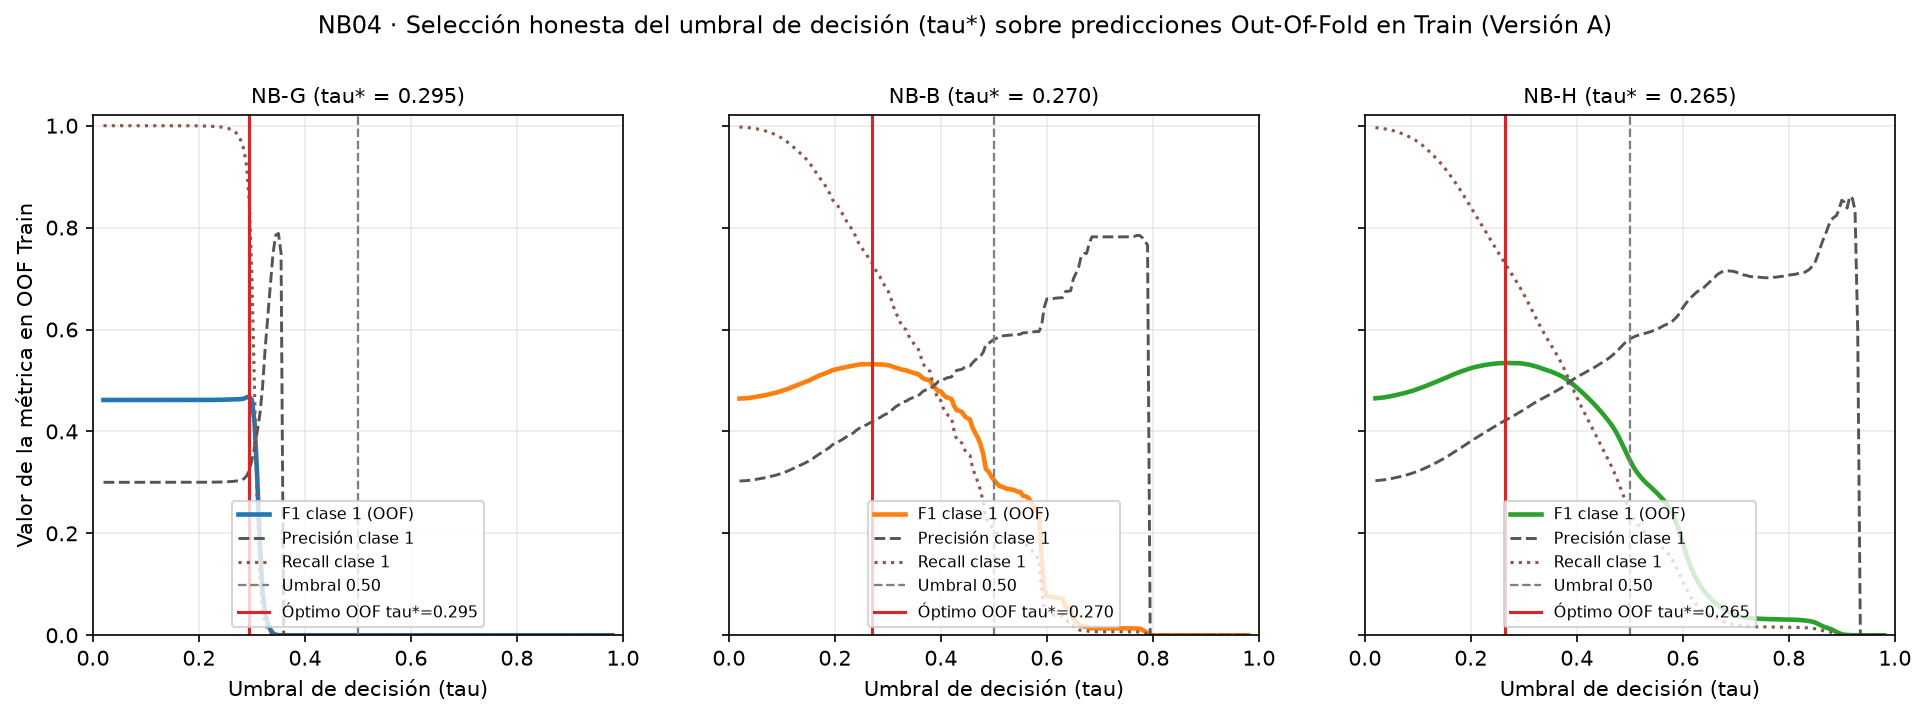

In [7]:
FIG_NB04 = PIPELINE.plotter.plot_oof_threshold_selection(EVAL_BUNDLE)

print("Comparación en predicciones Out-Of-Fold (Train) entre el umbral por defecto (0.50) y el umbral óptimo OOF (tau*):")
display(EVAL_BUNDLE.oof_threshold_summary_table)
display(Image(filename=str(FIG_NB04)))

### Lectura

La curva de optimización sobre predicciones *Out-Of-Fold* (OOF) en `train` (Tabla `07` y Figura `NB04`) demuestra por qué el ajuste del umbral $\tau^*$ sin tocar `test` es indispensable en un problema con prevalencia del `30.01 %`:

1. **`NB-G` (`var_smoothing = 5.0`):** al regularizar fuertemente las 14 columnas densas con el *prior* empírico `0.3001`, todas las probabilidades predichas quedan comprimidas alrededor de la prevalencia base (por debajo de `0.50`), por lo que con el corte estándar `0.50` el modelo predice siempre `0` (`F1 = 0.0000`, `Accuracy = 0.6999`). Al situar el umbral OOF en **$\tau^* = 0.2950$**, el `F1` OOF sube a **`0.4685`** (`Recall = 0.8517`, `Precision = 0.3232`, `Balanced Accuracy = 0.5434`).
2. **`NB-B` (`alpha = 0.01`):** con el umbral `0.50` solo captura los oficios con altísima propensión histórica (`Recall = 0.2065`, `Precision = 0.5803`, `F1 = 0.3046`). Al mover el corte al óptimo OOF **$\tau^* = 0.2700$** (cercano a la prevalencia a priori), el `Recall` asciende a **`0.7304`** con `Precision = 0.4184`, elevando el `F1` de clase 1 en `train` OOF de `0.3046` a **`0.5320`** ($\Delta\text{F1} = +0.2274$) y la `Balanced Accuracy` de `0.5712` a `0.6475`.
3. **`NB-H` (`var_smoothing = 1.0`, `alpha = 0.01`):** con el umbral `0.50` obtiene `F1 = 0.3438` (`Recall = 0.2440`, `Precision = 0.5816`, `Accuracy = 0.7204`). En su umbral óptimo OOF **$\tau^* = 0.2650$**, alcanza el mejor desempeño de toda la familia en `train` OOF: **`F1 = 0.5344`** ($\Delta\text{F1} = +0.1906$), con `Recall = 0.7291`, `Precision = 0.4217` y `Balanced Accuracy = 0.6502`.

---

## 8. Evaluación final en `test` (una sola vez, en Versión A) con Bootstrap por persona

**¿Qué hace?** Muestra los resultados de evaluar `NB-G`, `NB-B` y `NB-H` una única vez sobre la partición `test` de la **Versión A** (`347,720` filas · `70,419` personas) tanto en el umbral óptimo OOF ($\tau^*$) como en `0.50`, reportando `PR-AUC`, `ROC-AUC`, `F1`, `Recall`, `Precision`, `Balanced Accuracy`, `Brier` y `Accuracy` con sus intervalos de confianza al 95 % calculados mediante **bootstrap agrupado por persona** (`300` remuestreos de `resume_id`, semilla `42`), las matrices de confusión y las curvas `PR` y `ROC` con las tres referencias dibujadas (`NB05`).

**¿Por qué existe?** Como ambos clasificadores (`GaussianNB` y `BernoulliNB`) son deterministas, repetir el entrenamiento con distintas semillas daría exactamente el mismo número; la incertidumbre muestral real proviene de qué personas caen en la muestra de evaluación y debe medirse remuestreando conglomerados de `resume_id`.

**¿Qué recibe y qué entrega?** Recibe `EVAL_BUNDLE.test_metrics_table`, `EVAL_BUNDLE.confusion_matrices_table` y `EVAL_BUNDLE.model_curves`. Entrega las tablas finales de desempeño y confusión en `test` de A, el tiempo empleado por los `300` remuestreos de bootstrap y la figura `nb05_curvas_pr_roc_test.png`.

**Papel en el proyecto.** Constituye la evidencia fuera de muestra oficial de Naive Bayes en la Fase 4.

Tiempo total de calculo del bootstrap por persona (300 remuestreos x 6 evaluaciones en 347,720 filas): 21.65 s


,modelo_id,modelo,punto_operacion,umbral_tau,pr_auc_test,pr_auc_ic95,roc_auc_test,roc_auc_ic95,f1_clase_1_test,f1_clase_1_ic95,recall_clase_1_test,recall_clase_1_ic95,precision_clase_1_test,precision_clase_1_ic95,balanced_acc_test,balanced_acc_ic95,brier_test,brier_ic95,accuracy_test,accuracy_ic95,tiempo_fit_train_s,tiempo_predict_test_s,memoria_matriz_train_mb
0,NB-G,NB-G · GaussianNB (14 cols densas),Umbral OOF óptimo (tau*),0.2950,0.3778,"[0.3736, 0.3821]",0.5921,"[0.5892, 0.5945]",0.4687,"[0.4660, 0.4712]",0.8551,"[0.8525, 0.8576]",0.3228,"[0.3206, 0.3252]",0.5437,"[0.5422, 0.5453]",0.2086,"[0.2077, 0.2095]",0.4190,"[0.4169, 0.4211]",0.2190,0.0730,74.2900
1,NB-G,NB-G · GaussianNB (14 cols densas),Umbral por defecto (0.50),0.5000,0.3778,"[0.3736, 0.3821]",0.5921,"[0.5892, 0.5945]",0.0000,"[0.0000, 0.0000]",0.0000,"[0.0000, 0.0000]",0.0000,"[0.0000, 0.0000]",0.5000,"[0.5000, 0.5000]",0.2086,"[0.2077, 0.2095]",0.7003,"[0.6981, 0.7025]",0.2190,0.0730,74.2900
2,NB-B,"NB-B · BernoulliNB (4 binarias + 2,967 dummies)",Umbral OOF óptimo (tau*),0.2700,0.4829,"[0.4779, 0.4870]",0.7024,"[0.6998, 0.7047]",0.5323,"[0.5289, 0.5353]",0.7285,"[0.7241, 0.7327]",0.4193,"[0.4161, 0.4223]",0.6483,"[0.6459, 0.6505]",0.1877,"[0.1867, 0.1886]",0.6162,"[0.6142, 0.6180]",0.1000,0.0600,36.7400
3,NB-B,"NB-B · BernoulliNB (4 binarias + 2,967 dummies)",Umbral por defecto (0.50),0.5000,0.4829,"[0.4779, 0.4870]",0.7024,"[0.6998, 0.7047]",0.3042,"[0.2988, 0.3085]",0.2068,"[0.2024, 0.2104]",0.5752,"[0.5685, 0.5808]",0.5707,"[0.5686, 0.5724]",0.1877,"[0.1867, 0.1886]",0.7165,"[0.7143, 0.7188]",0.1000,0.0600,36.7400
4,NB-H,"NB-H · HybridNaiveBayes (10 num/ord + 2,971 binarias)",Umbral OOF óptimo (tau*),0.2650,0.4962,"[0.4910, 0.5004]",0.7058,"[0.7033, 0.7083]",0.5337,"[0.5304, 0.5366]",0.7279,"[0.7237, 0.7317]",0.4214,"[0.4180, 0.4244]",0.6500,"[0.6480, 0.6521]",0.1871,"[0.1862, 0.1881]",0.6188,"[0.6170, 0.6206]",0.6340,0.2830,118.1900
5,NB-H,"NB-H · HybridNaiveBayes (10 num/ord + 2,971 binarias)",Umbral por defecto (0.50),0.5000,0.4962,"[0.4910, 0.5004]",0.7058,"[0.7033, 0.7083]",0.3617,"[0.3561, 0.3658]",0.2652,"[0.2606, 0.2691]",0.5682,"[0.5624, 0.5736]",0.5895,"[0.5870, 0.5914]",0.1871,"[0.1862, 0.1881]",0.7194,"[0.7173, 0.7213]",0.6340,0.2830,118.1900


,modelo_id,punto_operacion,umbral_tau,TN_verdaderos_negativos,FP_falsos_positivos,FN_falsos_negativos,TP_verdaderos_positivos,pct_predichos_positivos
0,NB-G,Umbral OOF óptimo (tau*),0.2950,56560,186935,15104,89121,79.3900
1,NB-G,Umbral por defecto (0.50),0.5000,243495,0,104225,0,0.0000
2,NB-B,Umbral OOF óptimo (tau*),0.2700,138350,105145,28300,75925,52.0700
3,NB-B,Umbral por defecto (0.50),0.5000,227577,15918,82671,21554,10.7800
4,NB-H,Umbral OOF óptimo (tau*),0.2650,139320,104175,28364,75861,51.7800
5,NB-H,Umbral por defecto (0.50),0.5000,222490,21005,76581,27644,13.9900


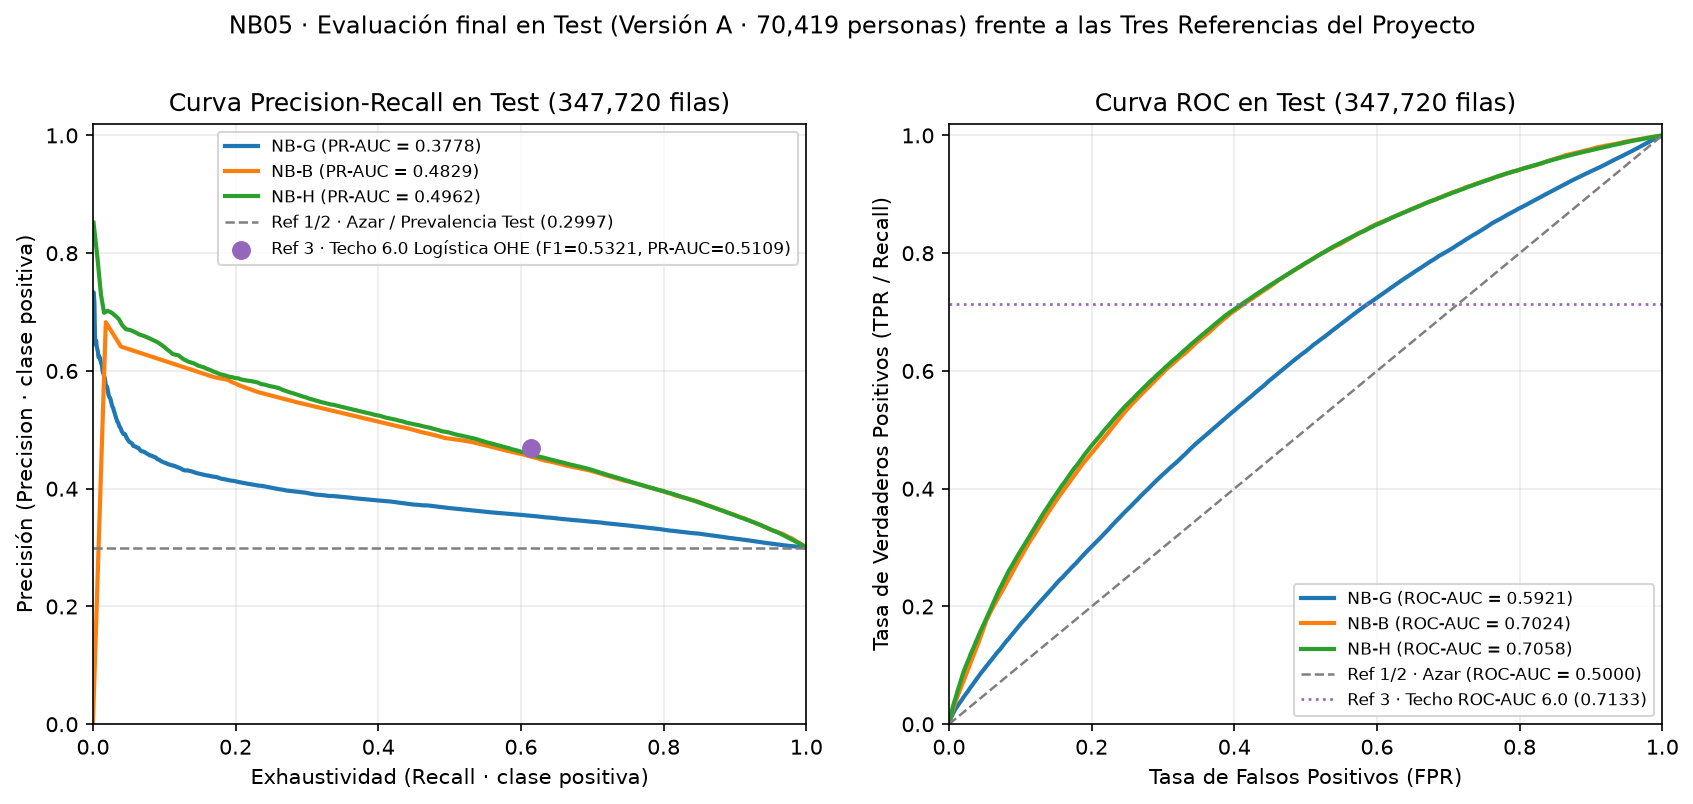

In [8]:
FIG_NB05 = PIPELINE.plotter.plot_pr_and_roc_test_curves(EVAL_BUNDLE)

print(f"Tiempo total de cálculo del bootstrap por persona (300 remuestreos x 6 evaluaciones en 347,720 filas): {EVAL_BUNDLE.bootstrap_elapsed_s:.2f} s")
display(EVAL_BUNDLE.test_metrics_table)
display(EVAL_BUNDLE.confusion_matrices_table)
display(Image(filename=str(FIG_NB05)))

### Lectura

La evaluación única sobre las `347,720` filas (`70,419` personas) de `test` en la **Versión A** confirma fuera de muestra la jerarquía observada en validación cruzada (Tablas `08a`, `08b` y Figura `NB05`):

1. **`NB-H` (`HybridNaiveBayes`, $\tau^* = 0.2650$) es el modelo ganador en todas las métricas principales:**
   - **`PR-AUC = 0.4962`** (IC 95 % por persona: `[0.4910, 0.5004]`), superando de forma estadísticamente significativa a `NB-B` (`0.4829`, IC 95 % `[0.4779, 0.4870]`) y por más de `11.8` puntos a `NB-G` (`0.3778`, IC 95 % `[0.3736, 0.3821]`).
   - **`ROC-AUC = 0.7058`** (IC 95 % `[0.7033, 0.7083]`), por encima de `NB-B` (`0.7024`, `[0.6998, 0.7047]`) y `NB-G` (`0.5921`, `[0.5892, 0.5945]`).
   - **`F1` clase 1 = `0.5337`** (IC 95 % `[0.5304, 0.5366]`), con `Recall = 0.7279` (`75,861` verdaderos positivos de `104,225` casos reales en `test`), `Precision = 0.4214`, `Balanced Accuracy = 0.6500` `[0.6480, 0.6521]`, `Accuracy = 0.6188` y el menor error cuadrático probabilístico (**`Brier = 0.1871`** `[0.1862, 0.1881]`).
2. **Contraste entre puntos de operación ($\tau^*$ vs. `0.50`):**
   - Si se opera `NB-H` en el umbral `0.50`, el modelo prioriza exactitud global (**`Accuracy = 0.7194`** `[0.7173, 0.7213]`, superando en `+1.91 pp` al baseline mayoritario de `0.7003`) con alta precisión (`0.5682`), pero solo detecta el `26.52 %` de las reincidencias (`F1 = 0.3617`).
   - En el umbral OOF $\tau^* = 0.2650$, detecta casi tres cuartas partes de todas las reincidencias (`72.79 %`) y supera la referencia trivial todo-positivo (`F1 = 0.4612`) por **`+0.0725` puntos de F1**.
3. **Costo computacional y factibilidad del bootstrap por persona:**
   - El ajuste completo en `train` (`1.39` millones de filas) toma apenas **`0.100 s` en `NB-B`**, **`0.219 s` en `NB-G`** y **`0.634 s` en `NB-H`**, con tiempos de predicción en `test` de `0.060 s`, `0.073 s` y `0.283 s` respectivamente.
   - Los `300` remuestreos de bootstrap agrupados por las `70,419` personas de `test` para los 6 puntos evaluados se completaron en **`21.65 s`**, confirmando que los intervalos de confianza al 95 % tienen una amplitud estrecha ($\approx \pm 0.003$ en `F1` y `ROC-AUC`, $\approx \pm 0.0045$ en `PR-AUC`).

---

## 9. Calibración probabilística: ¿ordenamiento (*ranking*) o probabilidades literales?

**¿Qué hace?** Evalúa la calidad de las probabilidades predichas en `test` de A mediante el diagrama de confiabilidad (`sklearn.calibration.calibration_curve`, 10 tramos uniformes), el puntaje de Brier, el Error de Calibración Esperado (`ECE`) y el histograma de probabilidades predichas separado por clase real (`NB06`).

**¿Por qué existe?** La teoría estadística predice que Naive Bayes —al multiplicar verosimilitudes de variables correlacionadas como si fueran independientes— empuja las probabilidades hacia los extremos ($0$ y $1$), siendo mucho mejor para **ordenar casos por riesgo (*ranking*)** que para entregar probabilidades literales bien calibradas. Aquí sometemos esa hipótesis a prueba con los datos del proyecto.

**¿Qué recibe y qué entrega?** Recibe `EVAL_BUNDLE.calibration_summary_table` y `EVAL_BUNDLE.model_curves`. Entrega la tabla comparativa de calibración (`Brier`, `ECE`, cuantiles de probabilidad por clase, porcentaje de predicciones extremas $< 0.05$ o $> 0.95$) y la figura `nb06_calibracion_y_distribucion_prob.png`.

**Papel en el proyecto.** Orienta cómo deben usarse las salidas del modelo en producción: como puntaje de priorización/deciles o tras recalibración monotónica.

Resumen de calibracion (Brier, ECE y concentracion en extremos) frente a capacidad de ranking (ROC-AUC y PR-AUC):


,modelo_id,modelo,brier_test,ece_error_calibracion_esperado,prob_media_predicha_test,prevalencia_real_test,prob_mediana_clase_0,prob_mediana_clase_1,pct_probabilidades_extremas_<005_o_>095,roc_auc_ranking_test,pr_auc_ranking_test
0,NB-G,NB-G · GaussianNB (14 cols densas),0.2086,0.0448,0.3014,0.2997,0.3018,0.3047,0.0000,0.5921,0.3778
1,NB-B,"NB-B · BernoulliNB (4 binarias + 2,967 dummies)",0.1877,0.0051,0.3003,0.2997,0.2392,0.3830,2.1800,0.7024,0.4829
2,NB-H,"NB-H · HybridNaiveBayes (10 num/ord + 2,971 binarias)",0.1871,0.0131,0.3011,0.2997,0.2313,0.3875,3.1800,0.7058,0.4962


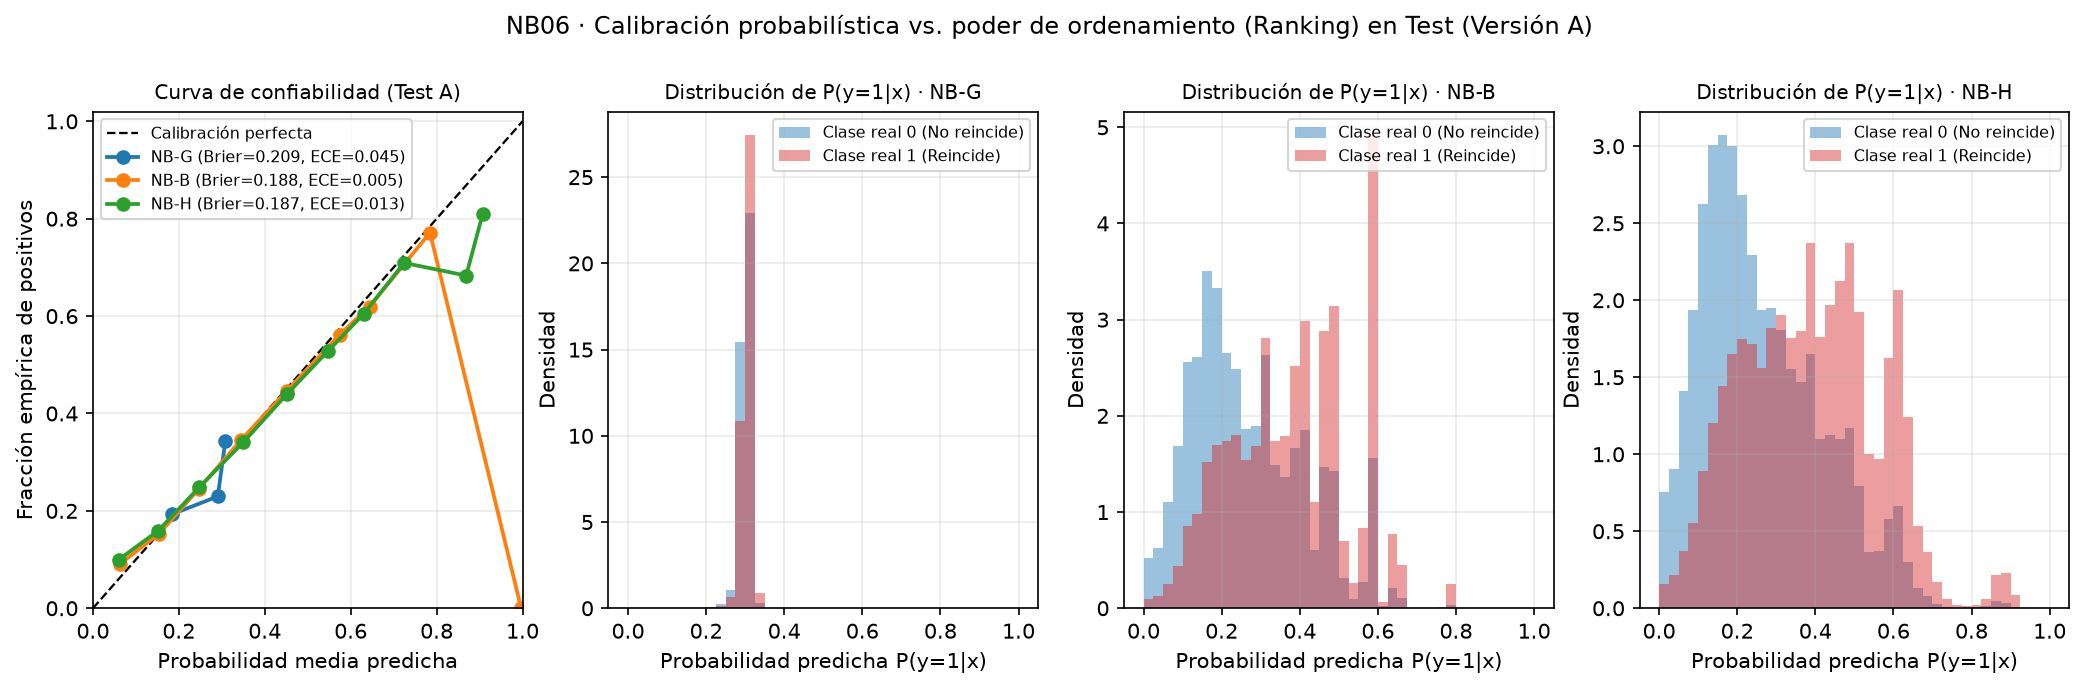

In [9]:
FIG_NB06 = PIPELINE.plotter.plot_calibration_and_histograms(EVAL_BUNDLE)

print("Resumen de calibración (Brier, ECE y concentración en extremos) frente a capacidad de ordenamiento (ROC-AUC y PR-AUC):")
display(EVAL_BUNDLE.calibration_summary_table)
display(Image(filename=str(FIG_NB06)))

### Lectura

El análisis de calibración en `test` (Tabla `09` y Figura `NB06`) matiza y responde con datos la hipótesis teórica sobre Naive Bayes:

1. **Cuando las varianzas no se regularizan o hay variables degeneradas, Naive Bayes produce probabilidades extremas y mal calibradas:** como vimos en la Sección 4 (`Tabla 04b`), `NB-G` sin regularizar (`var_smoothing=1e-9`) tenía un `Brier` de `0.6275` y concentraba más del `90 %` de sus predicciones por encima de `0.95`. Incluso tras regularizar `NB-G` con `var_smoothing=5.0`, su histograma queda excesivamente comprimido alrededor de la prevalencia (`mediana clase 0 = 0.3018`, `mediana clase 1 = 0.3047`, `0.00 %` en extremos, `ECE = 0.0448`, `Brier = 0.2086`), lo que refleja que un bloque gaussiano fuertemente suavizado pierde dispersión probabilística aunque conserve un ordenamiento moderado (`ROC-AUC = 0.5921`).
2. **En cambio, `NB-B` y `NB-H` regularizados muestran tanto buen *ranking* como buena calibración media:**
   - `NB-B` (donde cada fila activa exactamente **una** *dummy* `occupation_code_*` más a lo sumo 3 banderas densas, por lo que casi no hay multiplicación de factores redundantes) alcanza un **`ECE` de apenas `0.0051`** y **`Brier = 0.1877`**, con probabilidad media predicha en `test` de `0.3003` frente a la prevalencia real de `0.2997`, mediana de `0.2392` en clase `0` y `0.3830` en clase `1`, y solo `2.18 %` de probabilidades extremas ($< 0.05$ o $> 0.95$).
   - `NB-H` (`var_smoothing = 1.0`, `alpha = 0.01`) logra el **mejor puntaje de Brier (`0.1871`)** y el **mejor *ranking* (`ROC-AUC = 0.7058`, `PR-AUC = 0.4962`)**, con probabilidad media `0.3011`, mayor separación de medianas entre clase `0` (`0.2313`) y clase `1` (`0.3875`), `3.18 %` de probabilidades en extremos y una leve desviación en los tramos altos de la curva de confiabilidad (`ECE = 0.0131`) producto de sumar las 10 componentes gaussianas.
3. **Veredicto sobre la hipótesis:** la hipótesis teórica **se confirma en el régimen estándar sin amortiguación** (el doble conteo en Naive Bayes descalibra las probabilidades crudas mucho más de lo que afecta al *ranking*), pero **en el diseño híbrido regularizado (`NB-H` con `var_smoothing = 1.0`) la sobre-confianza queda controlada** (`ECE = 1.31 pp`), permitiendo usar sus probabilidades tanto para ordenar por deciles como para clasificar con $\tau^* = 0.2650$.

---

## 10. Análisis de patrones en unidades originales (Versión A)

> **Reglas metodológicas comunes a toda la sección:**
> 1. **Asociación, no causalidad:** los datos provienen de historiales laborales de Flandes (Bélgica); todo hallazgo describe asociaciones observadas y aprendidas por el modelo, nunca efectos causales.
> 2. **Unidades originales:** duraciones en trimestres (`dur_q`), antigüedad en empleos previos (`previous_jobs = job_order - 1`), calendario en años (`start_year`), conteos reales de competencias ESCO (`n_skills_essential`, `n_skills_knowledge`), nivel educativo en texto (`university_level` conservando `"No reportado"`) y gran grupo ocupacional ISCO con su etiqueta en español (`ISCO_MAJOR_LABELS_ES`).
> 3. **Alineación verificada y soporte mínimo:** antes de cruzar predicciones con variables descriptivas se verifica con `assert` fila a fila la igualdad exacta de `y` y `resume_id` entre `orig_train`/`orig_test` y `PreparedPartition`. Todo subgrupo reportado cumple un soporte mínimo de `200` filas en `train`; los patrones se descubren en `train`/CV y `test` solo se usa para confirmar su estabilidad.

---

### 10.1 Bloque 1 (Ocupacional) · Análisis `O1` y `O2`: Reincidencia y desempeño de los modelos por gran grupo ISCO

**¿Qué hace?** Ejecuta `PIPELINE.occupation_analyzer.run_all_occupation_analyses()` sobre la **Versión A** y presenta las tablas `O1` (tasa observada por gran grupo ISCO a 1 dígito con IC 95 % de Wilson y soporte en `train`, confirmada en `test` y contrastada con la probabilidad media de `NB-H`) y `O2` (`PR-AUC`, `ROC-AUC`, `F1`, `Recall`, `Precision`, `Brier` y sesgo de calibración por grupo para `NB-G`, `NB-B` y `NB-H`), junto con la figura `NB07`.

**¿Por qué existe?** Responde directamente la prioridad del estudio: cómo cambia la reincidencia ocupacional entre los 10 grandes grupos ISCO-08 (contrastando con la figura `g27_target_por_isco` del EDA) y en qué grupos funciona mejor o peor cada variante de Naive Bayes.

**¿Qué recibe y qué entrega?** Recibe `BUNDLE_A` y `EVAL_BUNDLE.tuned_models`. Entrega `OCC_BUNDLE`, las tablas `O1` y `O2` y la figura `nb07_o1_o2_reincidencia_y_desempeno_isco.png`.

**Papel en el proyecto.** Desagrega el desempeño global en los 10 sectores ocupacionales de la economía.

O1 · Tasa observada de reincidencia por gran grupo ISCO-08 en Train (con IC 95% Wilson) y confirmacion en Test:


,isco_major,gran_grupo_isco,soporte_filas_train,personas_train,positivos_train,tasa_observada_train_pct,ic95_wilson_train_pct,ic95_inf_train_pct,ic95_sup_train_pct,diff_vs_media_train_pp,prob_media_oof_nb_h_train_pct,soporte_filas_test,tasa_confirmada_test_pct,ic95_wilson_test_pct,diff_vs_media_test_pp,prob_media_nb_h_test_pct
0,5,5 · Trabajadores de los servicios y vendedores,302706,142409,102441,33.8400,"[33.67, 34.01]",33.6700,34.0100,3.8300,33.6700,75803,33.8700,"[33.53, 34.20]",3.8900,33.9000
1,3,3 · Técnicos y profesionales de nivel medio,272574,141941,91918,33.7200,"[33.54, 33.90]",33.5400,33.9000,3.7100,33.8300,68181,33.3700,"[33.01, 33.72]",3.3900,34.0800
2,9,9 · Ocupaciones elementales,189819,101030,62688,33.0300,"[32.81, 33.24]",32.8100,33.2400,3.0100,32.4400,47849,33.0500,"[32.63, 33.47]",3.0800,32.4800
3,2,2 · Profesionales científicos e intelectuales,243705,110488,73055,29.9800,"[29.80, 30.16]",29.8000,30.1600,-0.0400,31.0400,61082,30.1300,"[29.77, 30.50]",0.1600,31.6400
4,8,8 · Operadores de instalaciones y máquinas,80665,50927,19893,24.6600,"[24.37, 24.96]",24.3700,24.9600,-5.3500,23.9200,20103,24.7100,"[24.12, 25.31]",-5.2700,23.9800
5,7,"7 · Oficiales, operarios y artesanos",100371,58550,23191,23.1100,"[22.85, 23.37]",22.8500,23.3700,-6.9100,22.1400,25002,23.0800,"[22.56, 23.61]",-6.8900,22.2500
6,4,4 · Personal de apoyo administrativo,111705,70795,25086,22.4600,"[22.21, 22.70]",22.2100,22.7000,-7.5500,21.5500,27784,22.5500,"[22.06, 23.04]",-7.4200,20.9300
7,1,1 · Directores y gerentes,81000,50460,17874,22.0700,"[21.78, 22.35]",21.7800,22.3500,-7.9500,21.6100,19873,21.3700,"[20.81, 21.95]",-8.6000,21.9700
8,6,6 · Agricultores y trabajadores agropecuarios,5080,4288,1073,21.1200,"[20.02, 22.27]",20.0200,22.2700,-8.8900,21.8400,1241,21.9200,"[19.70, 24.30]",-8.0600,22.9800
9,0,0 · Ocupaciones militares,3393,3159,252,7.4300,"[6.59, 8.36]",6.5900,8.3600,-22.5800,7.0000,802,7.6100,"[5.97, 9.65]",-22.3700,6.4300


O2 · Desempeno comparativo de NB-G, NB-B y NB-H dentro de cada gran grupo ISCO-08:


,isco_major,gran_grupo_isco,modelo_id,soporte_train,soporte_test,prevalencia_test_pct,pr_auc_oof_train,roc_auc_oof_train,f1_oof_train,pr_auc_test,lift_pr_auc_vs_azar_test,roc_auc_test,f1_test,recall_test,precision_test,brier_test,prob_media_pred_test_pct,sesgo_calibracion_pp
0,0,0 · Ocupaciones militares,NB-G,3393,802,7.6100,0.1158,0.6477,0.2024,0.1515,1.9910,0.6389,0.1912,0.6066,0.1135,0.1160,29.1400,21.5400
1,0,0 · Ocupaciones militares,NB-B,3393,802,7.6100,0.1009,0.6302,0.0000,0.0856,1.1250,0.5027,0.0541,0.0328,0.1538,0.0726,7.6400,0.0400
2,0,0 · Ocupaciones militares,NB-H,3393,802,7.6100,0.1178,0.6734,0.0000,0.1160,1.5250,0.5447,0.0563,0.0328,0.2000,0.0715,6.4300,-1.1700
3,1,1 · Directores y gerentes,NB-G,81000,19873,21.3700,0.2476,0.5497,0.3644,0.2462,1.1520,0.5491,0.3543,0.8366,0.2248,0.1752,30.1500,8.7800
4,1,1 · Directores y gerentes,NB-B,81000,19873,21.3700,0.3711,0.6781,0.4049,0.3640,1.7030,0.6803,0.4033,0.4168,0.3906,0.1555,21.9100,0.5400
5,1,1 · Directores y gerentes,NB-H,81000,19873,21.3700,0.3829,0.6821,0.4175,0.3737,1.7490,0.6832,0.4080,0.4686,0.3614,0.1554,21.9700,0.6000
6,2,2 · Profesionales científicos e intelectuales,NB-G,243705,61082,30.1300,0.4286,0.6256,0.4688,0.4257,1.4130,0.6265,0.4735,0.9026,0.3209,0.2085,30.5500,0.4100
7,2,2 · Profesionales científicos e intelectuales,NB-B,243705,61082,30.1300,0.5485,0.7399,0.5617,0.5415,1.7970,0.7378,0.5650,0.6953,0.4758,0.1774,29.7700,-0.3700
8,2,2 · Profesionales científicos e intelectuales,NB-H,243705,61082,30.1300,0.5613,0.7429,0.5634,0.5565,1.8470,0.7407,0.5627,0.7242,0.4601,0.1782,31.6400,1.5100
9,3,3 · Técnicos y profesionales de nivel medio,NB-G,272574,68181,33.3700,0.3859,0.5730,0.5050,0.3847,1.1530,0.5761,0.5030,0.8527,0.3567,0.2223,30.1400,-3.2300


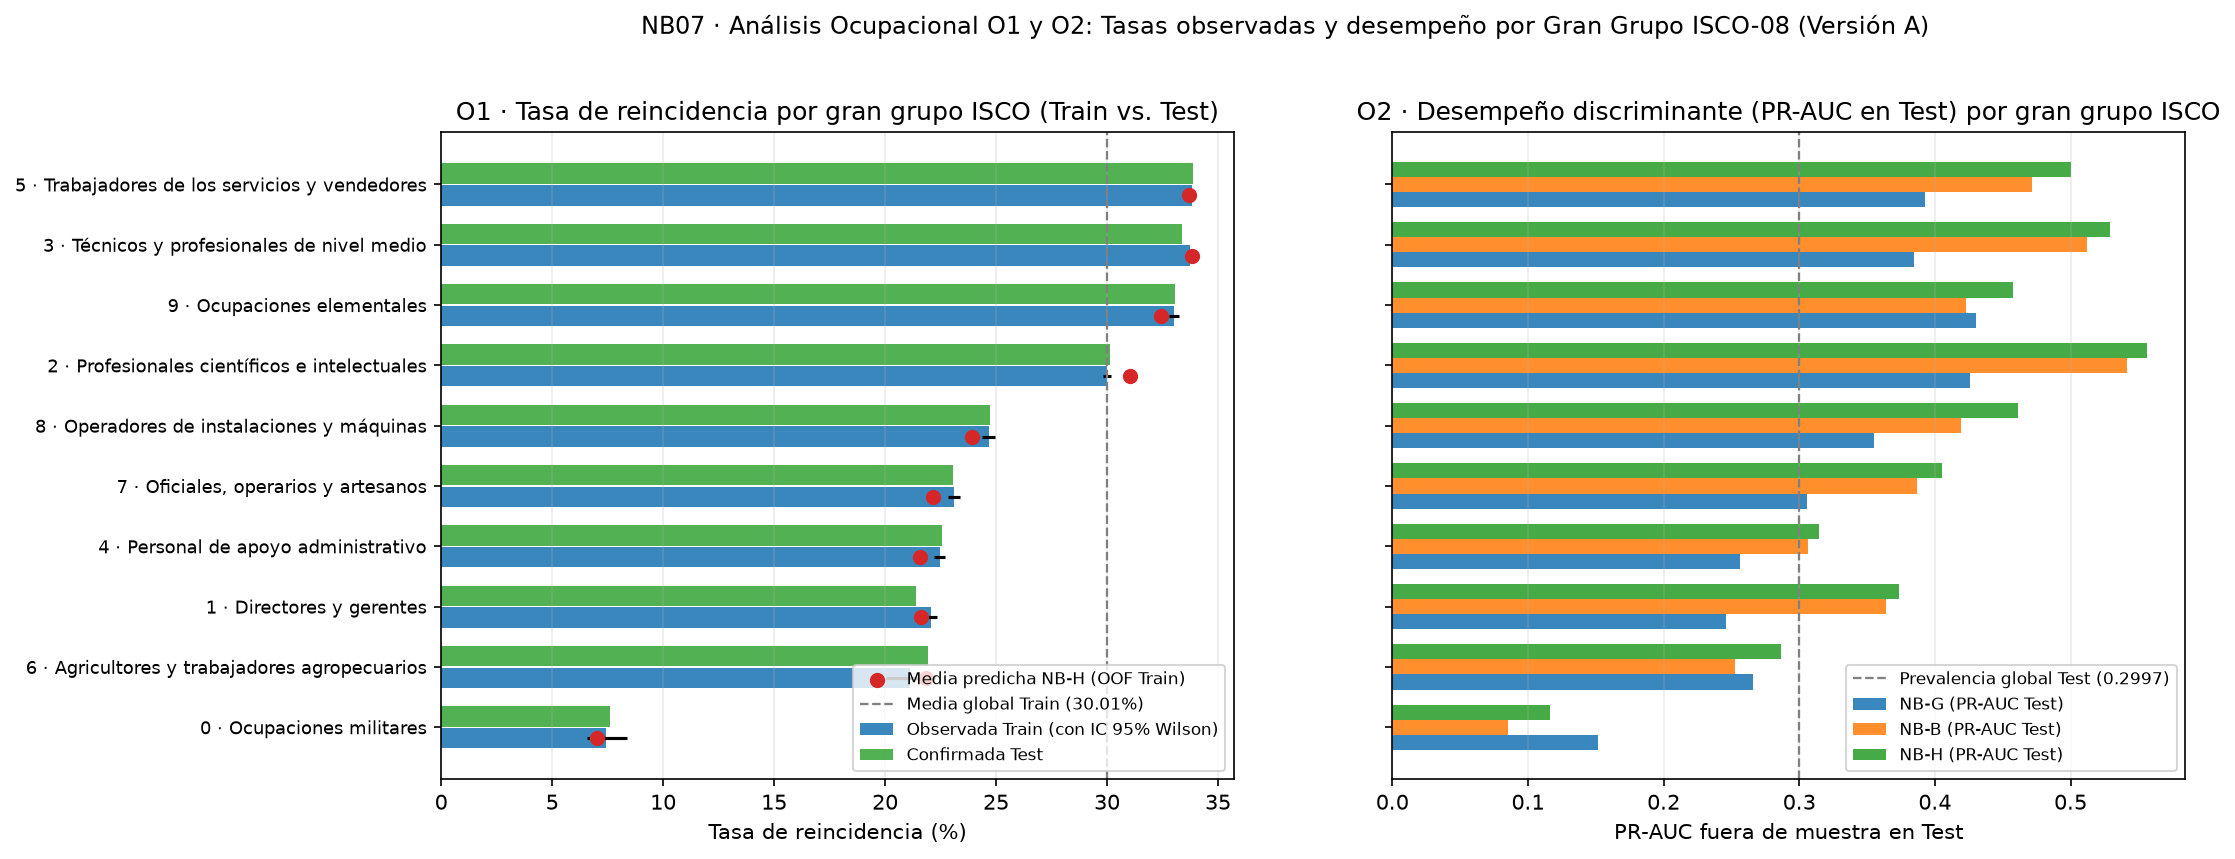

In [10]:
OCC_BUNDLE = PIPELINE.occupation_analyzer.run_all_occupation_analyses(
    orig_train=BUNDLE_A.orig_train,
    orig_test=BUNDLE_A.orig_test,
    train_blocks=BUNDLE_A.train_blocks,
    test_blocks=BUNDLE_A.test_blocks,
    tuned_models=EVAL_BUNDLE.tuned_models,
)
FIG_NB07 = PIPELINE.plotter.plot_o1_and_o2_isco_overview(OCC_BUNDLE)

print("O1 · Tasa observada de reincidencia por gran grupo ISCO-08 en Train (con IC 95 % Wilson) y confirmación en Test:")
display(OCC_BUNDLE.o1_rates_table)
print("O2 · Desempeño comparativo de NB-G, NB-B y NB-H dentro de cada gran grupo ISCO-08:")
display(OCC_BUNDLE.o2_performance_by_isco_table)
display(Image(filename=str(FIG_NB07)))

### Lectura

Los análisis `O1` y `O2` (Tablas `10_o1`, `10_o2` y Figura `NB07`) muestran cómo se estructura la reincidencia a través de los 10 grandes grupos ISCO-08 y por qué el desempeño del modelo varía sustancialmente entre sectores:

1. **Gradiente sectorial de reincidencia (`O1`) y consistencia con el EDA (`g27_target_por_isco`):**
   - La tasa observada en `train` abarca una horquilla de **`26.41 puntos porcentuales`**, plenamente confirmada en `test` y consistente con la figura `g27` del EDA:
     - **Tres grupos de alta reincidencia ($\approx 33 % - 34 %$):** `5 · Trabajadores de los servicios y vendedores` (`33.84 %` en `train`, IC 95 % `[33.67, 34.01]`, `n = 302,706`; confirmado en `test` con `33.87 %`), `3 · Técnicos y profesionales de nivel medio` (`33.72 %` en `train`, `[33.54, 33.90]`, `n = 272,574`; `33.37 %` en `test`) y `9 · Ocupaciones elementales` (`33.03 %` en `train`, `[32.81, 33.24]`, `n = 189,819`; `33.05 %` en `test`).
     - **Nivel intermedio (igual a la media global):** `2 · Profesionales científicos e intelectuales` (`29.98 %` en `train`, `[29.80, 30.16]`, `n = 243,705`; `30.13 %` en `test`).
     - **Cinco grupos de reincidencia moderada-baja ($21 % - 25 %$):** `8 · Operadores de instalaciones y máquinas` (`24.66 %`), `7 · Oficiales, operarios y artesanos` (`23.11 %`), `4 · Personal de apoyo administrativo` (`22.46 %`), `1 · Directores y gerentes` (`22.07 %`) y `6 · Agricultores y trabajadores agropecuarios` (`21.12 %`, `n = 5,080`).
     - **Mínimo extremo:** `0 · Ocupaciones militares` (`7.43 %` en `train`, IC 95 % `[6.59, 8.36]`, `n = 3,393`; `7.61 %` en `test`).
   - Las probabilidades medias predichas por `NB-H` reproducen casi exactamente la tasa real de cada grupo tanto en OOF `train` como en `test` (desviaciones menores a `1.6 pp` en los 10 grupos).
2. **En qué grupos funciona mejor y peor el modelo y por qué (`O2`):**
   - **Donde mejor discrimina `NB-H`:** en `2 · Profesionales científicos e intelectuales` (**`PR-AUC = 0.5565`**, *lift* de `1.847x` sobre el azar del grupo, `ROC-AUC = 0.7407`, `F1 = 0.5627`), `3 · Técnicos y profesionales de nivel medio` (**`PR-AUC = 0.5291`**, `ROC-AUC = 0.7179`, `F1 = 0.5746`), `5 · Trabajadores de los servicios y vendedores` (`PR-AUC = 0.5004`, `F1 = 0.5547`) y `8 · Operadores de instalaciones y máquinas` (`PR-AUC = 0.4615`, *lift* `1.868x`, `ROC-AUC = 0.7206`). En estos sectores coexisten oficios específicos muy repetitivos (docencia, salud, secretariado, comercio) con oficios de entrada única, lo que brinda gran poder separador a las *dummies* `occupation_code_*` combinadas con el orden del empleo.
   - **Donde más le cuesta discriminar:** en `0 · Ocupaciones militares` (`PR-AUC = 0.1160`, `ROC-AUC = 0.5447`), `6 · Agricultores` (`PR-AUC = 0.2866`, `ROC-AUC = 0.6034`) y `4 · Personal de apoyo administrativo` (`PR-AUC = 0.3142`, `ROC-AUC = 0.6267`). En `0` y `6` el tamaño muestral es pequeño y la prevalencia es baja (`7.61 %` en militares); en `4 · Apoyo administrativo`, la mayoría de las experiencias se concentran en pocos códigos genéricos de oficina donde la repetición depende de factores no observados en la fuente (tipo de contrato temporal o empleador), no del perfil ESCO del oficio.
   - **Superioridad consistente de `NB-H`:** en **9 de los 10 grandes grupos ISCO**, `NB-H` supera en `PR-AUC` y `ROC-AUC` tanto a `NB-G` como a `NB-B`.

---

### 10.2 Bloque 1 (Ocupacional) · Análisis `O3` y `O4`: Qué distingue a quienes reinciden dentro de cada grupo y perfil en unidades originales

**¿Qué hace?** Muestra el análisis `O3` —mapa de calor grupo ISCO por variable del cambio medio en la contribución aditiva al *log-odds* de `NB-H` (`NB08`) acompañado de la tabla de diferencias de medias en **unidades originales** entre quienes reinciden y quienes no dentro de cada grupo— y el análisis `O4` con el perfil completo por grupo y clase (mediana de duración en trimestres, empleos previos, nivel educativo modal, competencias esenciales y proporción de empleos vigentes).

**¿Por qué existe?** Permite distinguir si dentro de un gran grupo ocupacional la señal de repetición proviene de la trayectoria acumulada de la persona (`job_order`, `dur_q`), del calendario (`start_year`, `es_vigente`) o de la especificidad del oficio (`occupation_code_*`).

**¿Qué recibe y qué entrega?** Recibe `OCC_BUNDLE`. Entrega `o3_log_odds_heatmap_df`, `o3_original_units_diff_table`, `o4_profile_by_group_table` y la figura `nb08_o3_heatmap_contribuciones_isco.png`.

**Papel en el proyecto.** Traduce los pesos internos del clasificador probabilístico a diferencias tangibles en trimestres, número de empleos previos y competencias por sector.

O3a · Diferencia media de contribucion aditiva al log-odds (Reincide=1 menos Reincide=0) por gran grupo ISCO:


,isco_major,gran_grupo_isco,soporte_train,start_ord_rob,end_ord_rob,dur_q_rob,n_skills_essential_rob,n_skills_knowledge_rob,job_order_rob,univ_ord_mm,dur_q_bin,n_skills_essential_bin,es_vigente,tiene_skills,tiene_knowledge,occupation_code_ohe_bloque
0,0,0 · Ocupaciones militares,3393,0.0289,0.0102,0.0479,-0.0030,-0.0017,0.0381,-0.0000,0.0092,-0.0092,0.0026,0.0000,0.0000,0.7338
1,1,1 · Directores y gerentes,81000,-0.0006,-0.0001,0.0213,-0.0006,0.0008,0.0179,-0.0000,0.0021,0.0034,0.0005,0.0000,0.0007,0.6284
2,2,2 · Profesionales científicos e intelectuales,243705,0.0035,0.0006,0.0232,0.0299,0.0379,0.0245,-0.0001,0.0083,0.0175,0.0007,0.0000,0.0007,0.9647
3,3,3 · Técnicos y profesionales de nivel medio,272574,0.0003,0.0000,0.0205,0.0025,-0.0016,0.0126,0.0001,0.0060,0.0135,0.0013,0.0000,0.0035,0.7652
4,4,4 · Personal de apoyo administrativo,111705,-0.0016,-0.0003,0.0162,0.0011,0.0002,0.0131,0.0000,0.0031,0.0062,0.0015,0.0000,0.0018,0.2499
5,5,5 · Trabajadores de los servicios y vendedores,302706,0.0038,0.0006,0.0251,-0.0006,-0.0007,0.0186,0.0001,0.0093,-0.0006,0.0009,0.0000,0.0005,0.4136
6,6,6 · Agricultores y trabajadores agropecuarios,5080,0.0017,0.0005,0.0218,0.0038,0.0016,0.0027,0.0001,0.0065,0.0093,0.0021,0.0000,0.0021,0.4840
7,7,"7 · Oficiales, operarios y artesanos",100371,0.0023,0.0004,0.0316,0.0074,0.0027,0.0125,0.0002,0.0037,0.0159,0.0013,0.0007,-0.0002,0.5467
8,8,8 · Operadores de instalaciones y máquinas,80665,0.0024,0.0008,0.0290,0.0086,0.0000,0.0228,0.0002,0.0034,0.0224,0.0017,0.0000,0.0017,0.8189
9,9,9 · Ocupaciones elementales,189819,0.0016,0.0004,0.0234,0.0083,-0.0005,0.0175,0.0002,0.0069,0.0155,0.0018,0.0000,0.0033,0.2889


O3b · Diferencia de medias en unidades originales (Reincide=1 menos Reincide=0) dentro de cada gran grupo ISCO:


,isco_major,gran_grupo_isco,n_reincide_1,n_reincide_0,diff_empleos_previos_media,diff_duracion_trimestres_media,diff_anio_inicio_media,diff_skills_essential_media,diff_skills_knowledge_media,diff_es_vigente_pp,diff_educacion_universitaria_pp
0,0,0 · Ocupaciones militares,252,3141,1.7700,-3.9400,7.7000,-1.1200,-0.4300,-1.7600,7.6300
1,1,1 · Directores y gerentes,17874,63126,0.7800,-2.0800,-0.3300,0.1000,0.4100,-0.3400,2.1200
2,2,2 · Profesionales científicos e intelectuales,73055,170650,1.0100,-2.9100,1.1300,5.6000,2.1300,-0.4500,7.0100
3,3,3 · Técnicos y profesionales de nivel medio,91918,180656,0.5500,-2.5100,-0.0200,0.8200,-0.7500,-0.8400,-4.4100
4,4,4 · Personal de apoyo administrativo,25086,86619,0.5700,-1.6200,-0.5900,0.4900,-0.2900,-1.0000,-0.5100
5,5,5 · Trabajadores de los servicios y vendedores,102441,200265,0.8100,-3.3300,1.2100,-0.0900,-0.3300,-0.6200,-5.1200
6,6,6 · Agricultores y trabajadores agropecuarios,1073,4007,0.1700,-2.9000,0.4300,1.3000,0.6700,-1.4000,-5.3100
7,7,"7 · Oficiales, operarios y artesanos",23191,77180,0.5600,-2.7700,0.5700,2.4500,0.6200,-0.8500,-6.7300
8,8,8 · Operadores de instalaciones y máquinas,19893,60772,0.9800,-2.6300,0.4700,3.0500,-0.0400,-1.1300,-7.9000
9,9,9 · Ocupaciones elementales,62688,127131,0.7600,-2.7700,0.3900,2.7500,-0.0800,-1.2000,-6.9400


O4 · Perfil descriptivo en unidades originales separando Reincide=0 y Reincide=1 dentro de cada gran grupo ISCO:


,isco_major,gran_grupo_isco,clase_reincide,soporte_filas_train,duracion_mediana_trimestres,duracion_media_trimestres,empleos_previos_mediana,empleos_previos_media,nivel_educativo_modal,pct_nivel_educativo_modal,skills_esenciales_mediana,skills_esenciales_media,pct_empleo_vigente
0,0,0 · Ocupaciones militares,0 · No reincide,3141,9.0000,16.9400,1.0000,1.7100,Secondary school,46.3000,12.0000,14.1600,4.1400
1,0,0 · Ocupaciones militares,1 · Reincide,252,9.0000,13.0000,3.0000,3.4900,Bachelor,34.9000,12.0000,13.0400,2.3800
2,1,1 · Directores y gerentes,0 · No reincide,63126,9.0000,17.4300,3.0000,3.1800,Bachelor,38.7000,26.0000,26.9500,4.3900
3,1,1 · Directores y gerentes,1 · Reincide,17874,9.0000,15.3500,4.0000,3.9600,Bachelor,41.8000,24.0000,27.0500,4.0500
4,2,2 · Profesionales científicos e intelectuales,0 · No reincide,170650,5.0000,13.0200,2.0000,3.0400,Bachelor,43.7000,25.0000,28.9800,5.5000
5,2,2 · Profesionales científicos e intelectuales,1 · Reincide,73055,5.0000,10.1100,3.0000,4.0500,Bachelor,54.1000,29.0000,34.5800,5.0500
6,3,3 · Técnicos y profesionales de nivel medio,0 · No reincide,180656,5.0000,14.0900,2.0000,2.8300,Bachelor,41.3000,20.0000,23.6700,5.6000
7,3,3 · Técnicos y profesionales de nivel medio,1 · Reincide,91918,5.0000,11.5900,3.0000,3.3800,Bachelor,42.9000,20.0000,24.4900,4.7600
8,4,4 · Personal de apoyo administrativo,0 · No reincide,86619,5.0000,13.6600,2.0000,2.8000,Bachelor,39.1000,14.0000,15.5800,5.8800
9,4,4 · Personal de apoyo administrativo,1 · Reincide,25086,5.0000,12.0400,3.0000,3.3700,Bachelor,41.2000,16.0000,16.0700,4.8800


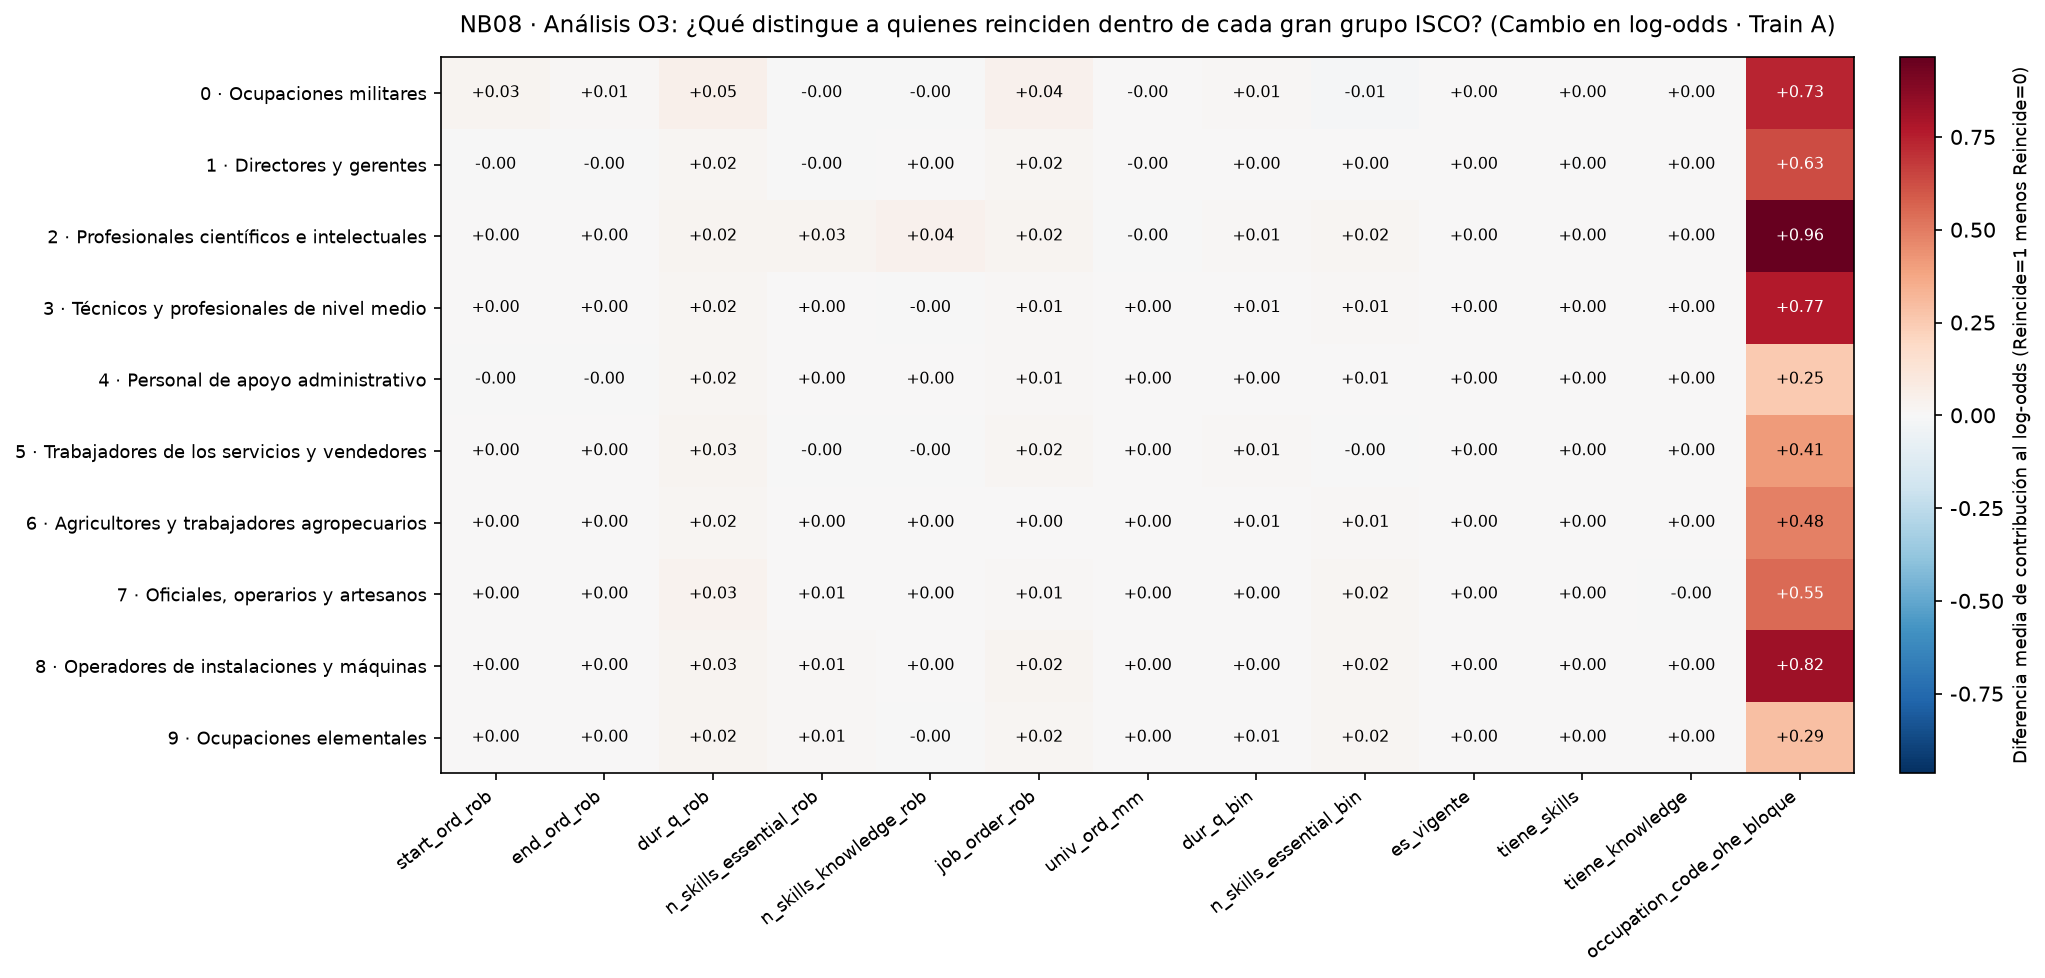

In [11]:
FIG_NB08 = PIPELINE.plotter.plot_o3_isco_heatmap(OCC_BUNDLE)

print("O3a · Diferencia media de contribución aditiva al log-odds (Reincide=1 menos Reincide=0) por gran grupo ISCO:")
display(OCC_BUNDLE.o3_log_odds_heatmap_df)
print("O3b · Diferencia de medias en unidades originales (Reincide=1 menos Reincide=0) dentro de cada gran grupo ISCO:")
display(OCC_BUNDLE.o3_original_units_diff_table)
print("O4 · Perfil descriptivo en unidades originales separando Reincide=0 y Reincide=1 dentro de cada gran grupo ISCO:")
display(OCC_BUNDLE.o4_profile_by_group_table)
display(Image(filename=str(FIG_NB08)))

### Lectura

Los análisis `O3` y `O4` (Tablas `10_o3a`, `10_o3b`, `10_o4` y Figura `NB08`) revelan qué diferencia a las personas que repiten oficio frente a las que no lo repiten **dentro de un mismo gran grupo ocupacional**:

1. **Descomposición aditiva del cambio en *log-odds* dentro de cada grupo (`O3a`, Figura `NB08`):**
   - La columna con mayor desplazamiento medio entre `reincide = 1` y `reincide = 0` dentro de cada gran grupo es el **bloque de ocupación específica (`occupation_code_ohe_bloque`)**, especialmente en `2 · Profesionales científicos e intelectuales` (`+0.9647` de *log-odds*), `8 · Operadores de instalaciones y máquinas` (`+0.8189`), `3 · Técnicos de nivel medio` (`+0.7652`) y `0 · Militares` (`+0.7338`), mientras que es mucho menor en `4 · Personal de apoyo administrativo` (`+0.2499`) y `9 · Ocupaciones elementales` (`+0.2889`). Esto demuestra que en profesionales y técnicos el oficio exacto a 4 dígitos separa fuertemente la reincidencia, mientras que en empleos administrativos y elementales la señal intra-grupo recae más en la trayectoria.
   - Entre las variables continuas/ordinales, **`dur_q_rob` (`+0.0162` a `+0.0479`) y `job_order_rob` (`+0.0125` a `+0.0381`)** aportan un empuje positivo transversal en todos los grupos; en cambio, **`n_skills_essential_rob` (`+0.0299`) y `n_skills_knowledge_rob` (`+0.0379`)** distinguen a los reincidentes de forma marcada casi exclusivamente dentro del grupo `2 · Profesionales científicos e intelectuales`.
2. **Diferencias en unidades originales (`O3b` y `O4`):**
   - **Más empleos previos y menor duración en todos los grupos:** sin excepción, en los 10 grandes grupos ISCO quienes reinciden acumulan más empleos previos (mediana de `3.0` frente a `2.0` en la mayoría de los grupos, y de `4.0` frente a `3.0` en `1 · Directores y gerentes`; diferencia media de `+0.55` a `+1.77` empleos previos) y tienen episodios laborales más cortos (la duración media es entre **`-1.62` y `-3.94` trimestres menor** en los que reinciden; por ejemplo, en `5 · Servicios y vendedores` pasa de `12.76` a `9.43` trimestres y en `2 · Profesionales` de `13.02` a `10.11` trimestres).
   - **Contraste educativo y de competencias según el sector:** en `2 · Profesionales científicos e intelectuales`, quienes reinciden ejercen oficios con **`+5.60` competencias esenciales más** (`media 34.58` vs. `28.98`, mediana `29.0` vs. `25.0`) y tienen **`+7.01 pp` más de educación universitaria** (`Bachelor` modal sube de `43.7 %` a `54.1 %`). Por el contrario, en los grupos operativos (`7 · Oficiales y operarios`, `8 · Operadores de máquinas`, `9 · Ocupaciones elementales`), el nivel modal es `Secondary school` (`56.8 %` a `65.7 %`) y quienes reinciden tienen entre **`-6.73 pp` y `-7.90 pp` menos** de titulación universitaria que quienes no reinciden.

---

### 10.3 Bloque 1 (Ocupacional) · Análisis `O5` y `O6`: Detalle a 2 dígitos / ocupaciones ESCO y vínculo con las transiciones del proyecto

**¿Qué hace?** Presenta el análisis `O5` sobre los 3 grandes grupos ISCO con mayor reincidencia y los 3 con menor reincidencia —detallando los subgrupos a 2 dígitos (`isco_sub2`) y las ocupaciones específicas (`occupation_code`, `occupation_label`) con mayor y menor razón de verosimilitud (*log-ratio*), su tasa observada y su soporte ($\ge 200$)— y el análisis `O6`, que cruza por gran grupo ISCO la **persistencia en el mismo gran grupo en el siguiente empleo clasificado de la misma persona** frente a la probabilidad media predicha de reincidencia (`NB09`), contrastando con `g21` y `g22` del EDA.

**¿Por qué existe?** Conecta la granularidad fina del catálogo ESCO con el objetivo general de transiciones laborales de JobPath, dejando explícitas tanto la **advertencia obligatoria de huella ocupacional (`N:1`)** en `O5` (como `reincide` se construye contando `(resume_id, occupation_code)`, el código de ocupación actúa como huella de oficios proclives a repetirse, no como causa) como las **tres limitaciones metodológicas de `O6`** (orden tomado sobre empleos clasificados, correlación sobre solo $n = 10$ grandes grupos y naturaleza asociativa).

**¿Qué recibe y qué entrega?** Recibe `OCC_BUNDLE`. Entrega las tablas `O5` (a 2 dígitos y a nivel ocupación ESCO), la tabla y correlaciones de `O6` y la figura `nb09_o6_persistencia_vs_probabilidad_isco.png`.

**Papel en el proyecto.** Cierra el Bloque 1 integrando la predicción supervisada de `7.1` con la estructura de transiciones de `5.0_EDA_jobpath.ipynb`.

O5a · Subgrupos ISCO a 2 digitos en los 3 grandes grupos de mayor y menor reincidencia (soporte >= 200):


,extremo_grupo,gran_grupo_isco,subgrupo_2d,ejemplo_grupo_unitario,soporte_train,tasa_reincide_train_pct,ic95_wilson_train_pct,log_likelihood_ratio_train,soporte_test,tasa_confirmada_test_pct,advertencia_metodologica
0,Bottom 3 menor reincidencia,1 · Directores y gerentes,14,Retail and wholesale trade managers,24833,26.5300,"[25.98, 27.08]",-0.1721,6007,24.2700,Asociación descriptiva sujeta a huella ocupacional (reincide se cuenta por resume_id + occupation_code).
1,Bottom 3 menor reincidencia,6 · Agricultores y trabajadores agropecuarios,61,"Gardeners, horticultural and nursery growers",4839,21.9300,"[20.78, 23.11]",-0.4232,1182,22.3400,Asociación descriptiva sujeta a huella ocupacional (reincide se cuenta por resume_id + occupation_code).
2,Bottom 3 menor reincidencia,1 · Directores y gerentes,12,Business services and administration managers not elsewhere classified,25334,21.1800,"[20.68, 21.69]",-0.4673,6351,21.3400,Asociación descriptiva sujeta a huella ocupacional (reincide se cuenta por resume_id + occupation_code).
3,Bottom 3 menor reincidencia,1 · Directores y gerentes,13,"Supply, distribution and related managers",25881,19.5200,"[19.04, 20.00]",-0.5701,6364,19.5600,Asociación descriptiva sujeta a huella ocupacional (reincide se cuenta por resume_id + occupation_code).
4,Bottom 3 menor reincidencia,1 · Directores y gerentes,11,Legislators,4952,17.5700,"[16.53, 18.65]",-0.6991,1151,16.4200,Asociación descriptiva sujeta a huella ocupacional (reincide se cuenta por resume_id + occupation_code).
5,Bottom 3 menor reincidencia,0 · Ocupaciones militares,02,Non-commissioned armed forces officers,1209,9.9300,"[8.36, 11.74]",-1.3587,256,5.0800,Asociación descriptiva sujeta a huella ocupacional (reincide se cuenta por resume_id + occupation_code).
6,Bottom 3 menor reincidencia,0 · Ocupaciones militares,01,Commissioned armed forces officers,1084,7.7500,"[6.30, 9.49]",-1.6301,256,8.9800,Asociación descriptiva sujeta a huella ocupacional (reincide se cuenta por resume_id + occupation_code).
7,Bottom 3 menor reincidencia,6 · Agricultores y trabajadores agropecuarios,62,Aquaculture workers,241,4.9800,"[2.87, 8.50]",-2.1013,59,13.5600,Asociación descriptiva sujeta a huella ocupacional (reincide se cuenta por resume_id + occupation_code).
8,Bottom 3 menor reincidencia,0 · Ocupaciones militares,03,"Armed forces occupations, other ranks",1100,4.3600,"[3.31, 5.74]",-2.2403,290,8.6200,Asociación descriptiva sujeta a huella ocupacional (reincide se cuenta por resume_id + occupation_code).
9,Top 3 mayor reincidencia,5 · Trabajadores de los servicios y vendedores,53,Child care workers,50888,40.5000,"[40.08, 40.93]",0.4622,12632,40.2200,Asociación descriptiva sujeta a huella ocupacional (reincide se cuenta por resume_id + occupation_code).


O5b · Ocupaciones ESCO con mayor y menor log-ratio dentro de los grupos extremos (con advertencia de huella N:1):


,extremo_grupo,gran_grupo_isco,occupation_code,ocupacion_esco,soporte_train,tasa_reincide_train_pct,ic95_wilson_train_pct,log_likelihood_ratio_train,soporte_test,tasa_confirmada_test_pct,advertencia_circularidad,direccion_en_grupo
0,Top 3 mayor reincidencia,5 · Trabajadores de los servicios y vendedores,5312.1,early years teaching assistant,6013,62.6500,"[61.42, 63.86]",1.3639,1499,62.0400,Huella ocupacional N:1 (reincide cuenta repeticiones de occupation_code por persona; describe propensión a repetirse...,Mayor log-ratio (empuja a reincide=1)
1,Top 3 mayor reincidencia,5 · Trabajadores de los servicios y vendedores,5321.1,healthcare assistant,6519,60.6200,"[59.43, 61.80]",1.2782,1559,58.9500,Huella ocupacional N:1 (reincide cuenta repeticiones de occupation_code por persona; describe propensión a repetirse...,Mayor log-ratio (empuja a reincide=1)
2,Top 3 mayor reincidencia,5 · Trabajadores de los servicios y vendedores,5120.1,cook,4920,50.4500,"[49.05, 51.84]",0.8646,1264,52.0600,Huella ocupacional N:1 (reincide cuenta repeticiones de occupation_code por persona; describe propensión a repetirse...,Mayor log-ratio (empuja a reincide=1)
3,Top 3 mayor reincidencia,5 · Trabajadores de los servicios y vendedores,5412.1,police officer,274,5.8400,"[3.63, 9.27]",-1.9331,68,8.8200,Huella ocupacional N:1 (reincide cuenta repeticiones de occupation_code por persona; describe propensión a repetirse...,Menor log-ratio (empuja a reincide=0)
4,Top 3 mayor reincidencia,5 · Trabajadores de los servicios y vendedores,5223.3,personal shopper,209,5.7400,"[3.31, 9.77]",-1.9508,58,18.9700,Huella ocupacional N:1 (reincide cuenta repeticiones de occupation_code por persona; describe propensión a repetirse...,Menor log-ratio (empuja a reincide=0)
5,Top 3 mayor reincidencia,5 · Trabajadores de los servicios y vendedores,5152.2,domestic housekeeper,323,5.5700,"[3.55, 8.64]",-1.9827,79,7.5900,Huella ocupacional N:1 (reincide cuenta repeticiones de occupation_code por persona; describe propensión a repetirse...,Menor log-ratio (empuja a reincide=0)
6,Top 3 mayor reincidencia,3 · Técnicos y profesionales de nivel medio,3259.5,dietetic technician,770,62.2100,"[58.73, 65.56]",1.3451,190,56.8400,Huella ocupacional N:1 (reincide cuenta repeticiones de occupation_code por persona; describe propensión a repetirse...,Mayor log-ratio (empuja a reincide=1)
7,Top 3 mayor reincidencia,3 · Técnicos y profesionales de nivel medio,3343.1,administrative assistant,66819,57.0200,"[56.65, 57.40]",1.1296,16691,56.5600,Huella ocupacional N:1 (reincide cuenta repeticiones de occupation_code por persona; describe propensión a repetirse...,Mayor log-ratio (empuja a reincide=1)
8,Top 3 mayor reincidencia,3 · Técnicos y profesionales de nivel medio,3313.2,bookkeeper,3460,50.8100,"[49.14, 52.47]",0.8791,769,43.1700,Huella ocupacional N:1 (reincide cuenta repeticiones de occupation_code por persona; describe propensión a repetirse...,Mayor log-ratio (empuja a reincide=1)
9,Top 3 mayor reincidencia,3 · Técnicos y profesionales de nivel medio,3311.2,financial broker,238,5.0400,"[2.91, 8.60]",-2.0881,63,9.5200,Huella ocupacional N:1 (reincide cuenta repeticiones de occupation_code por persona; describe propensión a repetirse...,Menor log-ratio (empuja a reincide=0)


O6 · Persistencia en el mismo gran grupo ISCO en el siguiente empleo vs. probabilidad media predicha por NB-H:


,n_grupos_isco,pearson_r_persistencia_1d_vs_prob,pearson_p_valor_persistencia_1d,spearman_rho_persistencia_1d_vs_prob,spearman_p_valor_persistencia_1d,pearson_r_autolazo_oficio_vs_prob
0,10,0.8604,0.0014,0.8061,0.0049,0.9837


,isco_major,gran_grupo_isco,n_empleos_train,n_transiciones_origen_train,persistencia_mismo_gran_grupo_1d_train_pct,persistencia_mismo_isco_4d_train_pct,autolazo_mismo_oficio_train_pct,prob_media_predicha_nb_h_train_pct,tasa_observada_reincide_train_pct,persistencia_mismo_gran_grupo_1d_test_pct,prob_media_predicha_nb_h_test_pct
0,0,0 · Ocupaciones militares,3393,3010,4.3900,3.1200,2.6200,7.0000,7.4300,4.9300,6.4300
1,1,1 · Directores y gerentes,81000,63388,29.6100,13.8300,9.4100,21.6100,22.0700,29.0400,21.9700
2,2,2 · Profesionales científicos e intelectuales,243705,192820,47.3700,19.6300,12.6800,31.0400,29.9800,47.2000,31.6400
3,3,3 · Técnicos y profesionales de nivel medio,272574,216064,35.2500,19.4500,13.8200,33.8300,33.7200,34.9200,34.0800
4,4,4 · Personal de apoyo administrativo,111705,90070,24.4600,8.9900,8.0400,21.5500,22.4600,24.5400,20.9300
5,5,5 · Trabajadores de los servicios y vendedores,302706,247327,41.3300,19.9000,12.7300,33.6700,33.8400,41.4000,33.9000
6,6,6 · Agricultores y trabajadores agropecuarios,5080,3814,11.6700,10.6700,8.8100,21.8400,21.1200,9.8500,22.9800
7,7,"7 · Oficiales, operarios y artesanos",100371,80107,32.8100,13.5400,9.8200,22.1400,23.1100,32.5500,22.2500
8,8,8 · Operadores de instalaciones y máquinas,80665,63655,27.1500,11.6300,10.3100,23.9200,24.6600,27.2900,23.9800
9,9,9 · Ocupaciones elementales,189819,149089,36.7500,15.8400,12.5600,32.4400,33.0300,36.6300,32.4800


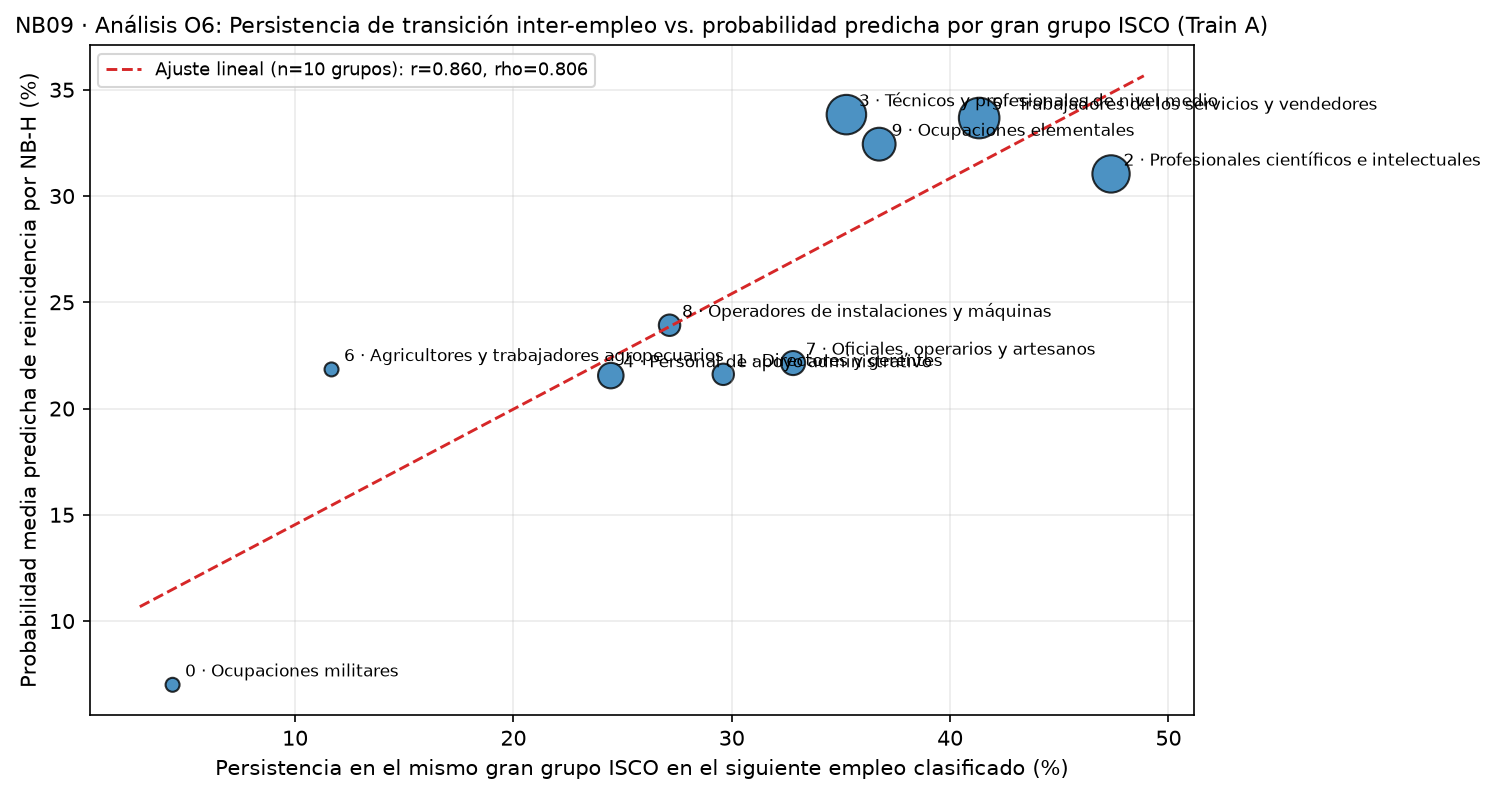

In [12]:
FIG_NB09 = PIPELINE.plotter.plot_o6_persistence_scatter(OCC_BUNDLE)

print("O5a · Subgrupos ISCO a 2 dígitos en los 3 grandes grupos de mayor y menor reincidencia (soporte >= 200; alerta > 5 pp train vs. test):")
display(OCC_BUNDLE.o5_subgroups_2d_table)
print("O5b · Ocupaciones ESCO con mayor y menor log-ratio dentro de los grupos extremos (tasas train/test y alerta > 5 pp):")
display(OCC_BUNDLE.o5_occupations_4d_table)
print("O6 · Persistencia en el mismo gran grupo ISCO en el siguiente empleo vs. probabilidad media predicha por NB-H (n = 10 grupos):")
display(pd.DataFrame([OCC_BUNDLE.o6_correlations_summary]))
display(OCC_BUNDLE.o6_transitions_persistence_table)
display(Image(filename=str(FIG_NB09)))

### Lectura

Los análisis `O5` y `O6` (Tablas `10_o5a`, `10_o5b`, `10_o6` y Figura `NB09`) profundizan en la heterogeneidad interna de los grupos ocupacionales y su conexión con las transiciones secuenciales del proyecto:

1. **Heterogeneidad interna a 2 dígitos y a nivel oficio ESCO (`O5a` y `O5b`):**
   - Aun dentro de los **3 grandes grupos de mayor reincidencia** (`5`, `3` y `9`), conviven subgrupos y oficios de altísima repetición con otros de baja repetición:
     - En `5 · Servicios y vendedores`, el subgrupo `53` (*Child care workers*, `n = 50,888`) alcanza `40.50 %` de reincidencia en `train` (`40.22 %` en `test`, $\text{LLR} = +0.4622$), liderado por `5312.1 · early years teaching assistant` (**`62.65 %`** en `train`, `n = 6,013`, $\text{LLR} = +1.3639$; `62.04 %` en `test`) y `5321.1 · healthcare assistant` (`60.62 %`, `n = 6,519`; `58.95 %` en `test`), mientras que el subgrupo `54` (*Security guards*, `n = 7,176`) tiene apenas `19.33 %` ($\text{LLR} = -0.5821$) y `5412.1 · police officer` (`n = 274`) cae a `5.84 %` ($\text{LLR} = -1.9331$).
     - En `3 · Técnicos de nivel medio`, el subgrupo `33` (`n = 152,610`, `39.45 %`) y el oficio masivo `3343.1 · administrative assistant` (`n = 66,819`, **`57.02 %`** en `train`, `56.56 %` en `test`, $\text{LLR} = +1.1296$) contrastan con el subgrupo `31` (*Draughtspersons*, `n = 33,190`, `19.02 %`) y con `3324.4 · wholesale merchant` (`n = 272`, `3.31 %`, $\text{LLR} = -2.5271$).
     - En `9 · Ocupaciones elementales`, destacan `9333.8 · warehouse worker` (`n = 28,678`, `44.94 %` en `train`, `45.44 %` en `test`) y `9112.2 · building cleaner` (`n = 19,666`, `43.56 %`), frente al subgrupo `95` (`12.03 %`) y `9112.1 · aircraft groomer` (`7.35 %`).
   - De forma simétrica, dentro del grupo de baja reincidencia `1 · Directores y gerentes` (`22.07 %` global), existen nichos con alta repetición como `1341.3 · nursery school head teacher` (`54.86 %`, `n = 1,493`, $\text{LLR} = +1.0416$) y `1420.3 · sales account manager` (`45.54 %`, `n = 7,977`), frente a `1219.5 · manufacturing facility manager` (`6.51 %`, `n = 215`).
   - **Advertencia obligatoria de huella ocupacional (`N:1`):** dado que la etiqueta `reincide` se construye contando repeticiones de `(resume_id, occupation_code)`, el código de ocupación actúa como una «huella» del tipo de contrato o mercado laboral de ese oficio (como se auditó en `7.0`). Estos patrones identifican ocupaciones estructuralmente propensas a repetirse (contratos por curso escolar en educación/cuidado, turnos en salud y almacenes), no causas individuales.
2. **Vínculo con las transiciones del proyecto (`O6`, Figura `NB09`) y contraste con `g21` y `g22` del EDA:**
   - Al cruzar por gran grupo ISCO la **persistencia en el mismo gran grupo en el siguiente empleo clasificado** contra la probabilidad media predicha por `NB-H`, se observa una asociación positiva fuerte: **$r = 0.8604$ ($p = 0.0014$) y $\rho = 0.8061$ ($p = 0.0049$)** sobre los $n = 10$ grandes grupos, y una correlación de **$r = 0.9837$** entre la tasa de autolazo en el mismo oficio y la probabilidad predicha.
   - El análisis reproduce y explica el matiz visto en las figuras `g21` y `g22` del EDA: `2 · Profesionales científicos e intelectuales` tiene la **mayor persistencia dentro del mismo gran grupo ISCO a 1 dígito (`47.37 %` en `train`, `47.20 %` en `test`)**, superando a `5 · Servicios y vendedores` (`41.33 %`) y `3 · Técnicos` (`35.25 %`), pero su tasa de autolazo en el *mismo oficio exacto* (`12.68 %`) y su reincidencia (`29.98 %`) son menores que en `3 · Técnicos` (`13.82 %` autolazo, `33.72 %` reincidencia). Es decir, los profesionales rotan intensamente entre ocupaciones distintas pero afines dentro del grupo `2` (movimiento lateral intra-ISCO observado en `g21`/`g22`), mientras que en servicios (`5`) y técnicos administrativos (`3`) una mayor fracción de los movimientos dentro del área vuelve exactamente al mismo `occupation_code`.
   - **Limitaciones declaradas:** (i) la secuencia de transiciones se calcula únicamente sobre empleos con ocupación ESCO clasificada; (ii) la correlación ecológica se evalúa sobre solo `10` grandes grupos agregados, por lo que es estadísticamente frágil ante valores extremos como `0 · Militares` (`4.39 %` de persistencia y `7.00 %` de probabilidad predicha); y (iii) refleja asociación descriptiva, no causalidad.

---

### 10.4 Bloque 2 (Patrones Generales) · Análisis `P1` y `P2`: Evidencia por variable y descomposición aditiva por perfil (`Waterfall`)

**¿Qué hace?** Ejecuta `PIPELINE.patterns_analyzer.run_all_general_patterns()` sobre la **Versión A** y presenta `P1` (curvas y tablas de *Log-Likelihood Ratio* por variable continua, ordinal y binaria usando `theta_`, `var_` y `feature_log_prob_`, identificando en unidades originales qué rangos empujan hacia `reincide = 1` o `reincide = 0`, figura `NB10`) y `P2` (descomposición aditiva exacta en gráficos de cascada `Waterfall` para 6 perfiles definidos con cuantiles reales de `train`, incluyendo grupos ocupacionales contrastantes de `O1`, figura `NB11`).

**¿Por qué existe?** Abre la caja blanca de Naive Bayes: muestra primero la forma funcional de cada factor univariado (`P1`) y luego cómo se suman el *log-odds* a priori y las contribuciones de cada variable para formar la predicción de perfiles concretos de negocio (`P2`), comprobando con `assert` que la suma reproduce exactamente el *log-odds* del modelo.

**¿Qué recibe y qué entrega?** Recibe `BUNDLE_A`, `EVAL_BUNDLE.tuned_models` y `OCC_BUNDLE.o1_rates_table`. Entrega `PAT_BUNDLE`, las tablas `P1` y `P2` y las figuras `nb10_p1_evidencia_log_likelihood_ratio.png` y `nb11_p2_waterfall_perfiles.png`.

**Papel en el proyecto.** Aporta explicabilidad individual (nivel caso/perfil) y global (nivel variable) en unidades reales del dominio.

P1a · Evidencia por variable continua/ordinal en cuantiles de Train (unidades originales y Log-Likelihood Ratio):


,variable,unidad_original,media_clase_0_rob,media_clase_1_rob,std_clase_0_rob,std_clase_1_rob,P10_orig (LLR),P25_orig (LLR),P50_orig (LLR),P75_orig (LLR),P90_orig (LLR),rango_orig_empuja_reincide_1,rango_orig_empuja_no_reincide_0
0,start_ord_rob,Trimestre de inicio (ordinal),-0.2655,-0.1834,1.9532,1.9175,7989.0 (-0.018),8021.0 (+0.009),8043.0 (+0.023),8057.0 (+0.030),8066.0 (+0.034),"[8009.0, 8073.0]","[7941.0, 8007.0]"
1,end_ord_rob,Trimestre de fin (ordinal),-0.1818,-0.1820,1.9836,1.9534,8005.0 (+0.009),8033.0 (+0.015),8052.0 (+0.015),8065.0 (+0.014),8074.0 (+0.012),"[7989.0, 8105.0]","[7959.0, 7981.0]"
2,dur_q_rob,Duración del empleo (trimestres),0.7946,0.5251,2.4871,2.2978,2.0 (+0.111),2.0 (+0.111),5.0 (+0.104),13.0 (+0.076),34.0 (-0.069),"[2.0, 25.0]","[28.0, 73.0]"
3,n_skills_essential_rob,Competencias esenciales ESCO (conteo),0.2109,0.3720,1.9857,2.0545,10.0 (-0.067),15.0 (-0.057),20.0 (-0.045),28.0 (-0.020),37.0 (+0.015),"[34.0, 69.0]","[8.0, 33.0]"
4,n_skills_knowledge_rob,Conocimientos teóricos ESCO (conteo),0.1960,0.2131,1.8943,2.0019,0.0 (-0.049),1.0 (-0.053),3.0 (-0.056),6.0 (-0.051),8.0 (-0.042),"[14.0, 14.0]","[0.0, 12.0]"
5,n_skills_sin_tipo_rob,Competencias sin tipo ESCO (conteo),0.0113,0.0057,1.7255,1.7236,0.0 (+0.001),0.0 (+0.001),0.0 (+0.001),0.0 (+0.001),0.0 (+0.001),"[0.0, 0.0]",Ninguno en P2–P98
6,job_order_rob,Orden del empleo en la carrera,0.2523,0.5016,1.9358,1.9849,1.0 (-0.086),2.0 (-0.068),3.0 (-0.048),5.0 (-0.006),8.0 (+0.070),"[6.0, 11.0]","[1.0, 5.0]"
7,univ_ord_mm,univ_ord_mm,0.3871,0.3703,1.7365,1.7353,0.0 (+0.003),0.2 (+0.001),0.2 (+0.001),0.5 (+0.000),0.8 (-0.001),"[0.0, 0.5]","[0.8, 0.8]"
8,dur_q_bin,Duración del empleo (trimestres),0.9970,0.8380,1.8958,1.8874,2.0 (+0.044),2.0 (+0.044),5.0 (+0.001),13.0 (-0.045),34.0 (-0.045),"[2.0, 10.0]","[13.0, 73.0]"
9,n_skills_essential_bin,Competencias esenciales ESCO (conteo),1.5349,1.7545,2.0517,2.0228,10.0 (-0.082),15.0 (-0.021),20.0 (+0.033),28.0 (+0.080),37.0 (+0.080),"[20.0, 69.0]","[8.0, 19.0]"


P1b · Evidencia por variable binaria (banderas densas y ocupaciones ESCO con mayor/menor LLR):


,tipo_binaria,variable,etiqueta_es,soporte_x1_train,P(x=1|y=0)_pct,P(x=1|y=1)_pct,LLR_cuando_x_es_1,LLR_cuando_x_es_0,efecto_presencia
0,Bandera densa,es_vigente,Empleo vigente (0/1),76119,5.7000,4.9400,-0.1421,0.0080,Empuja hacia no reincide=0 (-)
1,Bandera densa,tiene_skills,Reporta competencias prácticas (0/1),1391009,100.0000,100.0000,0.0000,-5.9568,Empuja hacia reincide=1 (+)
2,Bandera densa,tiene_knowledge,Reporta conocimientos (0/1),1249219,89.5000,90.5200,0.0114,-0.1024,Empuja hacia reincide=1 (+)
3,Bandera densa,tiene_sin_tipo,Reporta competencias sin tipo (0/1),12527,1.0600,0.5300,-0.6880,0.0053,Empuja hacia no reincide=0 (-)
4,Dummy ocupación (Top LLR),occupation_code_2264.2,2264.2 · physiotherapist,2138,0.0470,0.4020,2.1381,-0.0036,Empuja hacia reincide=1 (+)
5,Dummy ocupación (Top LLR),occupation_code_2266.2,2266.2 · speech and language therapist,1511,0.0340,0.2820,2.1140,-0.0025,Empuja hacia reincide=1 (+)
6,Dummy ocupación (Top LLR),occupation_code_2330.1.15,2330.1.15 · physical education teacher secondary school,2069,0.0710,0.3310,1.5457,-0.0026,Empuja hacia reincide=1 (+)
7,Dummy ocupación (Top LLR),occupation_code_2221.2,2221.2 · nurse responsible for general care,6236,0.2250,0.9690,1.4591,-0.0075,Empuja hacia reincide=1 (+)
8,Dummy ocupación (Top LLR),occupation_code_2330.1.12,2330.1.12 · modern languages teacher secondary school,6900,0.2560,1.0570,1.4189,-0.0081,Empuja hacia reincide=1 (+)
9,Dummy ocupación (Top LLR),occupation_code_0210.3,0210.3 · special forces officer,243,0.0240,0.0010,-2.8279,0.0002,Empuja hacia no reincide=0 (-)


P2 · Descomposicion aditiva del log-odds para 6 perfiles reales de Train (verificada con assert exacto):


,perfil_id,perfil_descripcion,gran_grupo_isco,ocupacion_esco,empleos_previos,duracion_trimestres,anio_inicio,es_vigente,nivel_educativo,skills_esenciales,prior_log_odds,contrib_carrera,contrib_duracion,contrib_calendario_vigencia,contrib_educacion,contrib_competencias,contrib_ocupacion_ohe,log_odds_final,probabilidad_predicha_pct,y_real
0,P2-01,1. Carrera corta y reciente (primer empleo),3 · Técnicos y profesionales de nivel medio,3512.1 · ICT help desk agent,0,5.0000,2015,0,No reportado,20.0000,-0.8467,-0.0856,0.1049,0.0537,0.0028,-0.0498,0.0284,-0.7924,31.1700,0
1,P2-02,2. Carrera larga con empleo vigente,"7 · Oficiales, operarios y artesanos",7114.1 · concrete finisher,7,31.0000,2018,1,Secondary school,18.0000,-0.8467,0.0696,-0.0871,-0.1035,0.0014,-0.2168,-1.0378,-2.2208,9.7900,1
2,P2-03,3. Ocupación de alta exigencia de competencias ESCO (>= P90),9 · Ocupaciones elementales,9333.8 · warehouse worker,2,5.0000,2016,0,Master,40.0000,-0.8467,-0.0485,0.1049,0.0546,-0.0014,0.0709,0.6519,-0.0142,49.6400,0
3,P2-04,4. Educación 'No reportado' en trayectoria media,5 · Trabajadores de los servicios y vendedores,5131.1 · restaurant host/restaurant hostess,2,5.0000,2007,0,No reportado,13.0000,-0.8467,-0.0485,0.1049,0.0374,0.0028,-0.2886,-0.3404,-1.3791,20.1100,0
4,P2-05,5. Grupo ISCO de mayor reincidencia (5 · Trabajadores de los servicios y vendedores) con rotación previa,5 · Trabajadores de los servicios y vendedores,5131.2 · waiter/waitress,6,2.0000,2015,0,Bachelor,29.0000,-0.8467,0.0431,0.1552,0.0544,0.0000,0.0250,0.2479,-0.3212,42.0400,1
5,P2-06,6. Grupo ISCO de menor reincidencia (0 · Ocupaciones militares) en primer empleo,0 · Ocupaciones militares,0310.3 · infantry soldier,0,12.0000,1994,0,Bachelor,12.0000,-0.8467,-0.0856,0.0808,-0.0193,0.0000,-0.1826,-2.1041,-3.1575,4.0800,0


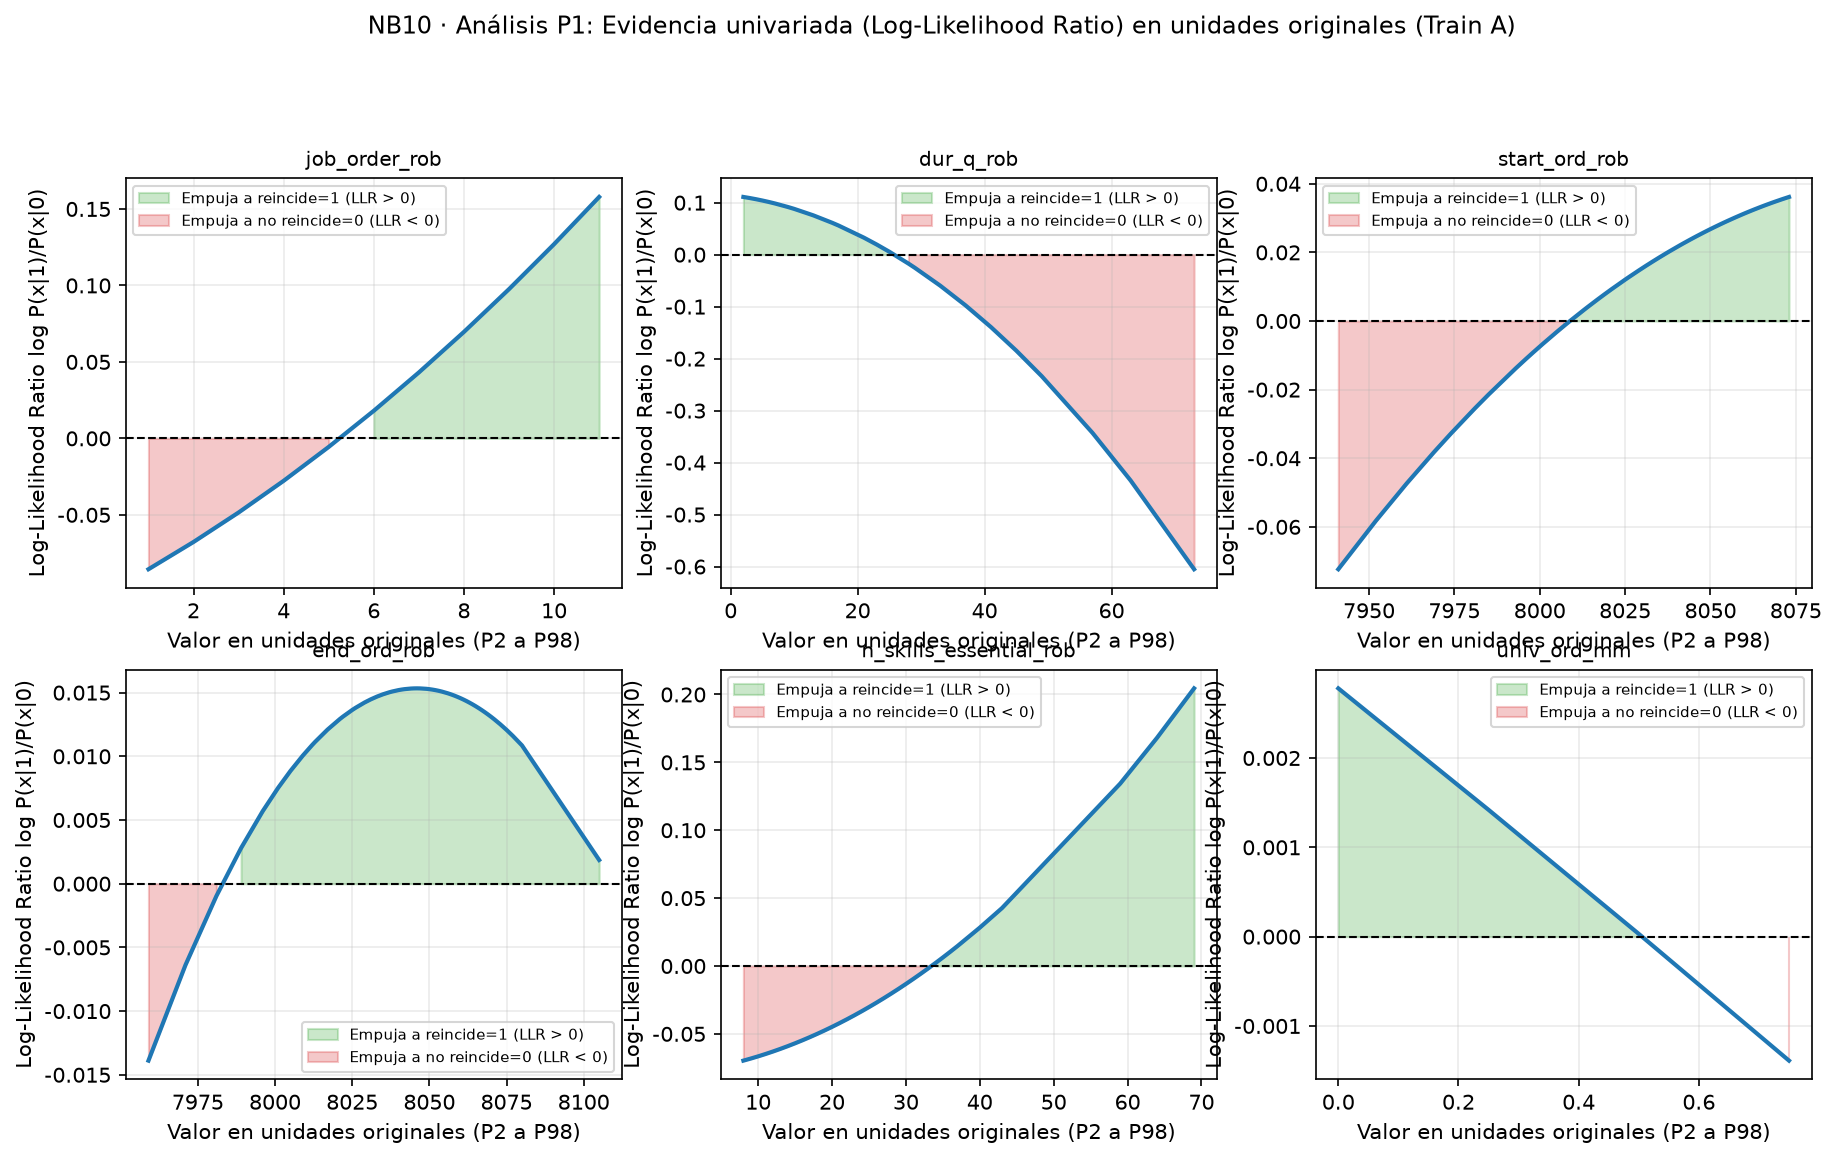

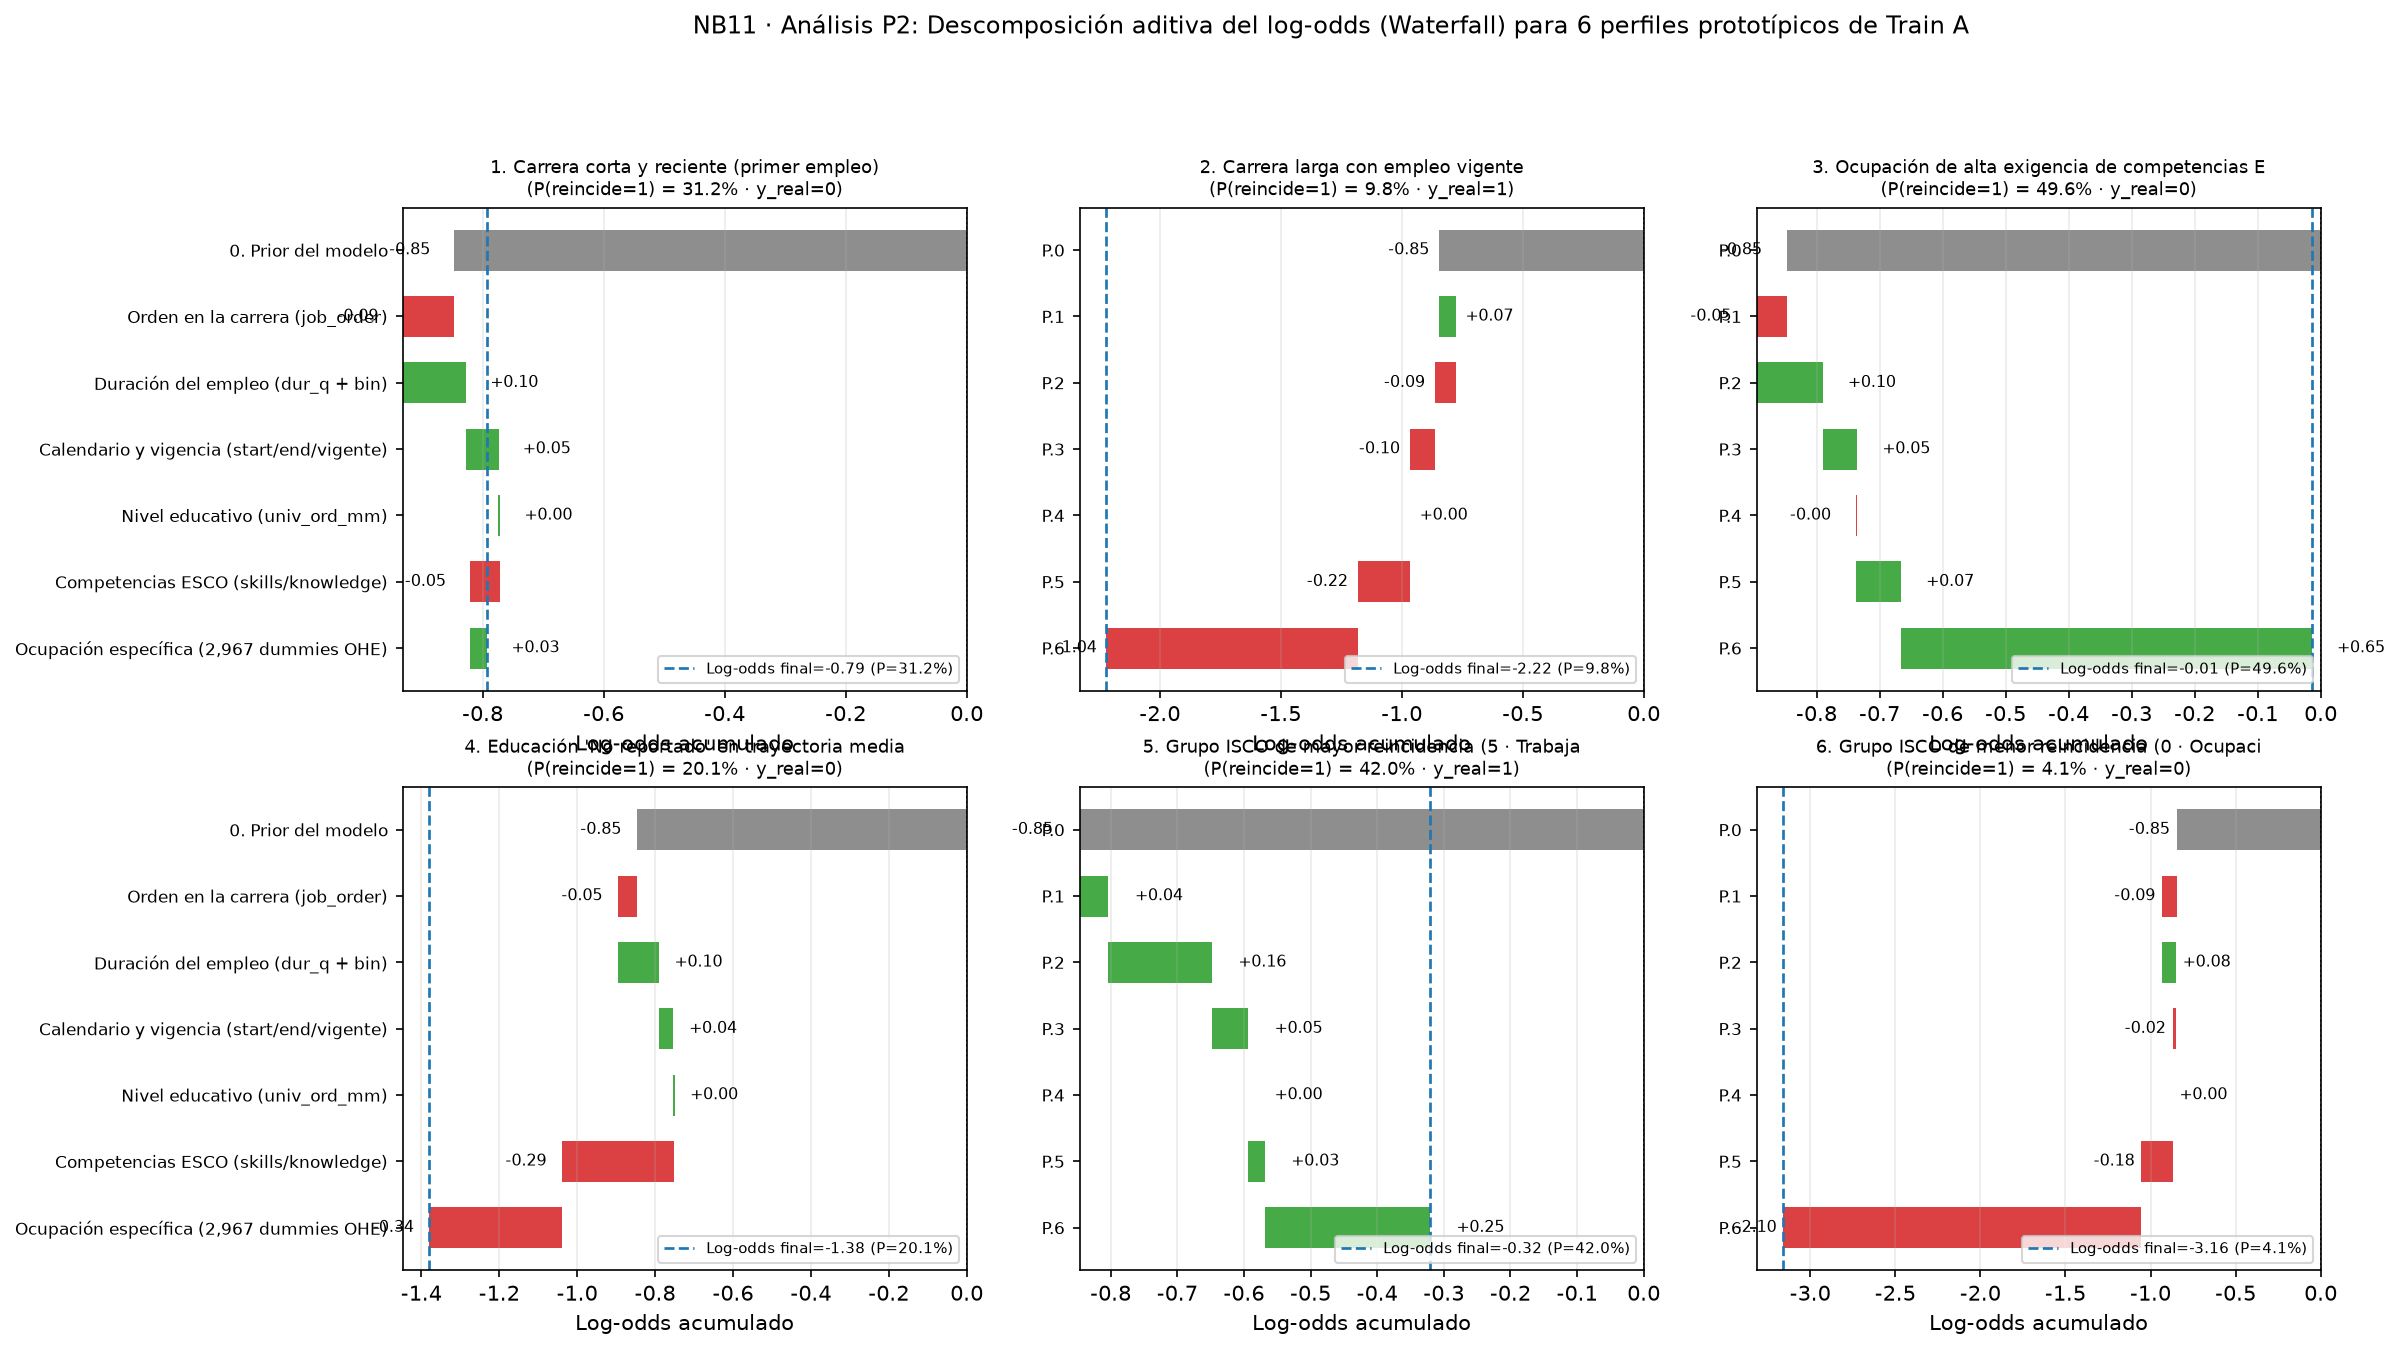

In [13]:
PAT_BUNDLE = PIPELINE.patterns_analyzer.run_all_general_patterns(
    orig_train=BUNDLE_A.orig_train,
    orig_test=BUNDLE_A.orig_test,
    train_blocks=BUNDLE_A.train_blocks,
    tuned_models=EVAL_BUNDLE.tuned_models,
    o1_df=OCC_BUNDLE.o1_rates_table,
    test_blocks=BUNDLE_A.test_blocks,
)
FIG_NB10 = PIPELINE.plotter.plot_p1_llr_curves(PAT_BUNDLE)
FIG_NB11 = PIPELINE.plotter.plot_p2_waterfalls(PAT_BUNDLE.p2_waterfalls)

print("P1a · Evidencia por variable continua/ordinal en cuantiles de Train y máximo |LLR| en P2–P98 y Test:")
display(PAT_BUNDLE.p1_continuous_evidence_table)
print("P1b · Evidencia por variable binaria (banderas densas y ocupaciones ESCO con mayor/menor LLR, con tasas train y test):")
display(PAT_BUNDLE.p1_binary_evidence_table)
print("P1c · Participación en la contribución media absoluta de log-odds sobre Test (bloque continuo vs. ordinal vs. binarias vs. ocupación OHE):")
display(PAT_BUNDLE.p1_block_log_odds_share_test_table)
print("P2 · Descomposición aditiva del log-odds para 6 perfiles reales de Train (verificada con assert exacto):")
display(PAT_BUNDLE.p2_profiles_summary_table)
display(Image(filename=str(FIG_NB10)))
display(Image(filename=str(FIG_NB11)))

### Lectura

Los análisis `P1` y `P2` (Tablas `10_p1a`, `10_p1b`, `10_p2` y Figuras `NB10` y `NB11`) muestran cómo construye `NB-H` cada predicción en unidades originales:

1. **Evidencia por variable (`P1`, Figura `NB10`):**
   - **Orden del empleo (`job_order`):** es el factor continuo más monótono; entre el primer y el quinto empleo (`[1.0, 5.0]`) el *Log-Likelihood Ratio* (LLR) es negativo (en `P10 = 1.0` empleo, $\text{LLR} = -0.086$; en `P50 = 3.0` empleos, $\text{LLR} = -0.048$), mientras que a partir del **sexto empleo (`[6.0, 11.0]`)** empuja hacia `reincide = 1` (en `P90 = 8.0` empleos, $\text{LLR} = +0.070$).
   - **Duración del empleo (`dur_q` y `dur_q_bin`):** muestra la relación inversa documentada en el EDA (`g28`); duraciones cortas e intermedias de **`2.0` a `25.0` trimestres** empujan hacia `reincide = 1` ($\text{LLR} = +0.111$ en `2.0` trimestres y $+0.044$ en `dur_q_bin`), mientras que empleos largos de **`28.0` a `73.0` trimestres** ($\ge 7$ años) empujan con fuerza hacia `reincide = 0` ($\text{LLR} = -0.069$ en `P90 = 34.0` trimestres y $-0.045$ en `dur_q_bin`).
   - **Competencias esenciales (`n_skills_essential_rob` y `n_skills_essential_bin`):** oficios con menos de `19` competencias esenciales empujan hacia `reincide = 0` ($\text{LLR} = -0.067$ en continuo y $-0.082$ en *bin* para `P10 = 10` competencias), mientras que oficios de alta carga competencial ($\ge 20$ en *bin* y $\ge 34$ en continuo, como enfermería, docencia y gestión comercial) empujan hacia `reincide = 1` ($\text{LLR} = +0.080$ en *bin* y $+0.015$ en continuo para `P90 = 37` competencias).
   - **Variables binarias y *dummies* de ocupación (`10_p1b`):** estar vigente (`es_vigente = 1`, `n = 76,119`) resta `-0.1421` al *log-odds* de reincidencia. En cambio, las ocupaciones específicas aportan los mayores saltos individuales de evidencia: `2264.2 · physiotherapist` (`n = 2,138`, $\text{LLR} = +2.1381$), `2266.2 · speech and language therapist` (`n = 1,511`, $\text{LLR} = +2.1140$), `2330.1.15 · physical education teacher` (`n = 2,069`, $\text{LLR} = +1.5457$) y `2221.2 · nurse responsible for general care` (`n = 6,236`, $\text{LLR} = +1.4591$); en el extremo opuesto, `0210.3 · special forces officer` (`n = 243`, $\text{LLR} = -2.8279$) y `3324.4 · wholesale merchant` (`n = 272`, $\text{LLR} = -2.5271$) empujan fuertemente hacia `reincide = 0`.
2. **Descomposición aditiva por perfil (`P2`, Figura `NB11`):**
   - Partiendo siempre del *log-odds* a priori de **`-0.8467`** ($P = 30.01 \%$), los 6 perfiles reales de `train` muestran cómo la suma exacta de los bloques explica el resultado final (verificado con `assert` con tolerancia `< 1e-9`):
     - **`P2-03` (Ocupación de alta exigencia de competencias, `9333.8 · warehouse worker`, `40` competencias esenciales, `5` trimestres):** la ocupación (`+0.6519`), la duración corta (`+0.1049`), las competencias (`+0.0709`) y el calendario (`+0.0546`) compensan el *prior* negativo y llevan el *log-odds* a **`-0.0142`** (**probabilidad predicha = `49.64 %`**, muy por encima del umbral $\tau^* = 26.50 \%$).
     - **`P2-05` (Grupo de mayor reincidencia `5 · Servicios y vendedores`, `5131.2 · waiter/waitress`, `6` empleos previos, `2` trimestres):** suma impulsos positivos en ocupación (`+0.2479`), duración breve (`+0.1552`), calendario (`+0.0544`), carrera acumulada (`+0.0431`) y competencias (`+0.0250`), alcanzando un *log-odds* de **`-0.3212`** (**probabilidad predicha = `42.04 %`**, clasificado correctamente como positivo para `y_real = 1`).
     - **`P2-06` (Grupo de menor reincidencia `0 · Ocupaciones militares`, `0310.3 · infantry soldier`, primer empleo):** el oficio militar (`-2.1041`), las bajas competencias (`-0.1826`) y ser primer empleo (`-0.0856`) hunden el *log-odds* a **`-3.1575`** (**probabilidad predicha = `4.08 %`**, `y_real = 0`).
     - **`P2-02` (Carrera larga con empleo vigente, `7114.1 · concrete finisher`, `7` empleos previos, `31` trimestres, `es_vigente = 1`):** aunque tener `7` empleos previos suma `+0.0696`, la larga duración (`-0.0871`), estar vigente (`-0.1035`), el perfil de competencias (`-0.2168`) y el oficio (`-1.0378`) reducen la probabilidad a **`9.79 %`** (ilustrando un caso real de falso negativo cuando una persona reincidente se estabiliza durante muchos años en su empleo actual).

---

### 10.5 Bloque 2 (Patrones Generales) · Análisis `P3`, `P4` y `P5`: Deciles de riesgo, posición en la carrera, periodo y nivel educativo

**¿Qué hace?** Presenta el análisis `P3` (tasa observada de reincidencia, *lift* y ganancia acumulada por decil de probabilidad predicha de `D10` a `D01`, perfil comparativo en unidades originales del decil superior `D10` frente al inferior `D01` incluyendo composición ISCO, figura `NB12`), el análisis `P4` (tasa observada vs. predicha por tramos de `job_order` y de `start_year`) y el análisis `P5` (tasa observada, tasa predicha, contribución al *log-odds*, `PR-AUC` y `F1` por nivel educativo manteniendo `"No reportado"` como categoría propia sin rellenar, figura `NB13`).

**¿Por qué existe?** Evalúa la utilidad operativa del *ranking* por deciles (`P3`), verifica si Naive Bayes reproduce fielmente los gradientes temporales y de orden en la carrera (`P4`) y comprueba que el tratamiento de la ausencia informativa en educación (`"No reportado"`) no distorsione las predicciones (`P5`).

**¿Qué recibe y qué entrega?** Recibe `PAT_BUNDLE`. Entrega las tres tablas de `P3`, las dos tablas de `P4`, la tabla de `P5` y las figuras `nb12_p3_deciles_lift_gain.png` y `nb13_p4_p5_carrera_periodo_educacion.png`.

**Papel en el proyecto.** Conecta el puntaje probabilístico con reglas de segmentación de riesgo y audita el comportamiento por cohorte y nivel educativo.

P3a · Tasa observada, Lift y Ganancia Acumulada por decil de probabilidad predicha (NB-H):


,decil_riesgo,decil_orden,soporte_train,prob_min_train_pct,prob_max_train_pct,prob_media_train_pct,tasa_observada_train_pct,lift_train,pct_poblacion_acumulada,ganancia_acumulada_positivos_train_pct,tasa_confirmada_test_pct,lift_test,ganancia_acumulada_positivos_test_pct
0,D10 (Mayor riesgo),10,139102,53.3200,99.6200,61.8600,59.3900,1.9790,10.0000,19.7900,58.8900,1.9650,19.6500
1,D09,9,139102,45.2300,53.3200,48.6200,48.2300,1.6070,20.0000,35.8600,48.4600,1.6170,35.8200
2,D08,8,139102,38.7000,45.2300,41.8100,41.5900,1.3860,30.0000,49.7200,41.4900,1.3840,49.6600
3,D07,7,139101,32.7300,38.7000,35.7900,34.9300,1.1640,40.0000,61.3600,34.6800,1.1570,61.2300
4,D06,6,139102,27.5300,32.7300,30.1500,29.5700,0.9850,50.0000,71.2100,29.9300,0.9980,71.2100
5,D05,5,139102,22.6200,27.5300,24.9700,24.9700,0.8320,60.0000,79.5300,24.8600,0.8290,79.5100
6,D04,4,139101,18.5500,22.6200,20.5200,20.8800,0.6960,70.0000,86.4900,20.8900,0.6970,86.4800
7,D03,3,139102,14.7200,18.5500,16.6500,16.9400,0.5640,80.0000,92.1300,16.9700,0.5660,92.1400
8,D02,2,139102,10.1600,14.7200,12.5200,13.7800,0.4590,90.0000,96.7200,13.5100,0.4510,96.6500
9,D01 (Menor riesgo),1,139102,0.0000,10.1600,6.0300,9.8400,0.3280,100.0000,100.0000,10.0500,0.3350,100.0000


P3b · Perfil promedio en unidades originales del decil superior (D10) frente al decil inferior (D01):


,indicador_unidades_originales,D01_menor_riesgo,D10_mayor_riesgo,diferencia_D10_menos_D01
0,Soporte de filas en Train,"139,102","139,102",0
1,Tasa observada de reincidencia (%),9.8400,59.3900,49.5500
2,Empleos previos acumulados (media / mediana),2.46 / 2.0,3.85 / 3.0,1.3900
3,Duración del empleo en trimestres (media / mediana),30.04 / 13.0,6.19 / 5.0,-23.8500
4,Año de inicio del empleo (media / mediana),2004.5 / 2008,2010.2 / 2012,5.6800
5,Competencias esenciales ESCO (media / mediana),20.47 / 18.0,31.69 / 20.0,11.2300
6,Proporción de empleos vigentes (%),16.2400,0.9000,-15.3400
7,Nivel educativo modal (% dentro del decil),Secondary school (37.2%),Bachelor (49.0%),Cambio de composición


P3c · Composicion por gran grupo ISCO-08 en el decil de mayor riesgo (D10) vs. menor riesgo (D01):


,isco_major,gran_grupo_isco,participacion_train_total_pct,participacion_en_D01_bajo_riesgo_pct,participacion_en_D10_alto_riesgo_pct,diferencia_D10_menos_D01_pp,sobremuestreo_D10_vs_total
0,0,0 · Ocupaciones militares,0.2400,1.7600,0.0000,-1.7600,0.0000
1,1,1 · Directores y gerentes,5.8200,10.5500,0.9500,-9.5900,0.1600
2,2,2 · Profesionales científicos e intelectuales,17.5200,23.2200,36.9900,13.7700,2.1100
3,3,3 · Técnicos y profesionales de nivel medio,19.6000,18.3800,47.5800,29.2100,2.4300
4,4,4 · Personal de apoyo administrativo,8.0300,6.4700,0.0000,-6.4700,0.0000
5,5,5 · Trabajadores de los servicios y vendedores,21.7600,12.0100,9.9400,-2.0700,0.4600
6,6,6 · Agricultores y trabajadores agropecuarios,0.3700,0.5500,0.0000,-0.5500,0.0000
7,7,"7 · Oficiales, operarios y artesanos",7.2200,11.2000,1.9900,-9.2100,0.2800
8,8,8 · Operadores de instalaciones y máquinas,5.8000,11.2500,1.9500,-9.3000,0.3400
9,9,9 · Ocupaciones elementales,13.6500,4.6100,0.5900,-4.0200,0.0400


P4 · Tasas observadas y predichas por orden del empleo (job_order) y periodo de inicio (start_year):


,tramo_job_order,soporte_train,tasa_observada_train_pct,ic95_wilson_train_pct,prob_media_NB_G_train_pct,prob_media_NB_B_train_pct,prob_media_NB_H_train_pct,soporte_test,tasa_confirmada_test_pct,prob_media_NB_H_test_pct
0,1 (1er empleo),263187,21.5800,"[21.43, 21.74]",29.4900,30.1400,27.7500,65882,21.5200,27.8200
1,2 (2do empleo),248254,26.3200,"[26.14, 26.49]",29.7800,29.7900,28.4000,62082,26.3900,28.6400
2,3 (3er empleo),219727,29.1500,"[28.96, 29.34]",29.9900,29.6600,28.9900,55007,29.2300,29.2300
3,4–5 empleos,323258,32.2200,"[32.06, 32.38]",30.2600,29.7100,29.9800,81038,31.9800,30.3100
4,6–8 empleos,233882,36.0000,"[35.80, 36.19]",30.6600,30.2300,31.9700,58496,35.9900,32.2300
5,9+ empleos,102710,41.8000,"[41.50, 42.11]",31.2900,31.4800,35.9300,25215,42.0800,36.1200


,periodo_anio_inicio,soporte_train,tasa_observada_train_pct,ic95_wilson_train_pct,prob_media_NB_G_train_pct,prob_media_NB_B_train_pct,prob_media_NB_H_train_pct,soporte_test,tasa_confirmada_test_pct,prob_media_NB_H_test_pct
0,<= 1999,183416,25.8000,"[25.60, 26.00]",28.9200,28.2100,23.7500,45258,25.6200,23.7800
1,2000–2004,136571,28.9700,"[28.73, 29.22]",29.6800,29.0200,27.3000,34004,28.6600,27.3800
2,2005–2009,298002,30.1400,"[29.97, 30.30]",30.0400,29.8100,29.4100,74736,30.0300,29.4800
3,2010–2014,499602,31.2300,"[31.11, 31.36]",30.4200,30.5700,31.5000,125364,31.2600,31.8100
4,2015–2019,273369,30.9900,"[30.81, 31.16]",30.7200,30.9300,32.9100,68349,31.1000,33.2500


P5 · Desempeno y tasas por nivel educativo (conservando 'No reportado' como categoria propia):


,university_level,tratamiento_categoria,soporte_train,pct_del_train,tasa_observada_train_pct,ic95_wilson_train_pct,prob_media_oof_nb_h_train_pct,contrib_log_odds_univ_ord_mm,pr_auc_oof_train,roc_auc_oof_train,f1_oof_train,soporte_test,tasa_confirmada_test_pct,prob_media_nb_h_test_pct,pr_auc_test,roc_auc_test,f1_test
0,No reportado,Categoría propia sin imputar (ausencia informativa),160664,11.5500,30.8000,"[30.58, 31.03]",29.1900,0.0028,0.4844,0.6987,0.5377,40270,30.5400,29.2700,0.4801,0.6971,0.5353
1,Secondary school,Nivel educativo reportado,548687,39.4400,31.0900,"[30.97, 31.21]",29.6600,0.0014,0.4959,0.7043,0.5440,136581,31.2000,29.8600,0.4956,0.7045,0.5466
2,Bachelor,Nivel educativo reportado,473842,34.0600,30.7500,"[30.62, 30.88]",31.3600,0.0000,0.5267,0.7146,0.5444,118038,30.6400,31.5800,0.5227,0.7128,0.5416
3,Master,Nivel educativo reportado,201851,14.5100,24.9300,"[24.74, 25.12]",27.8700,-0.0014,0.4550,0.6972,0.4751,51275,24.9900,28.2900,0.4505,0.6961,0.4720
4,PhD,Nivel educativo reportado,5974,0.4300,22.8300,"[21.79, 23.91]",21.5400,-0.0028,0.3206,0.6064,0.3214,1556,21.6600,22.6900,0.3078,0.6394,0.3847


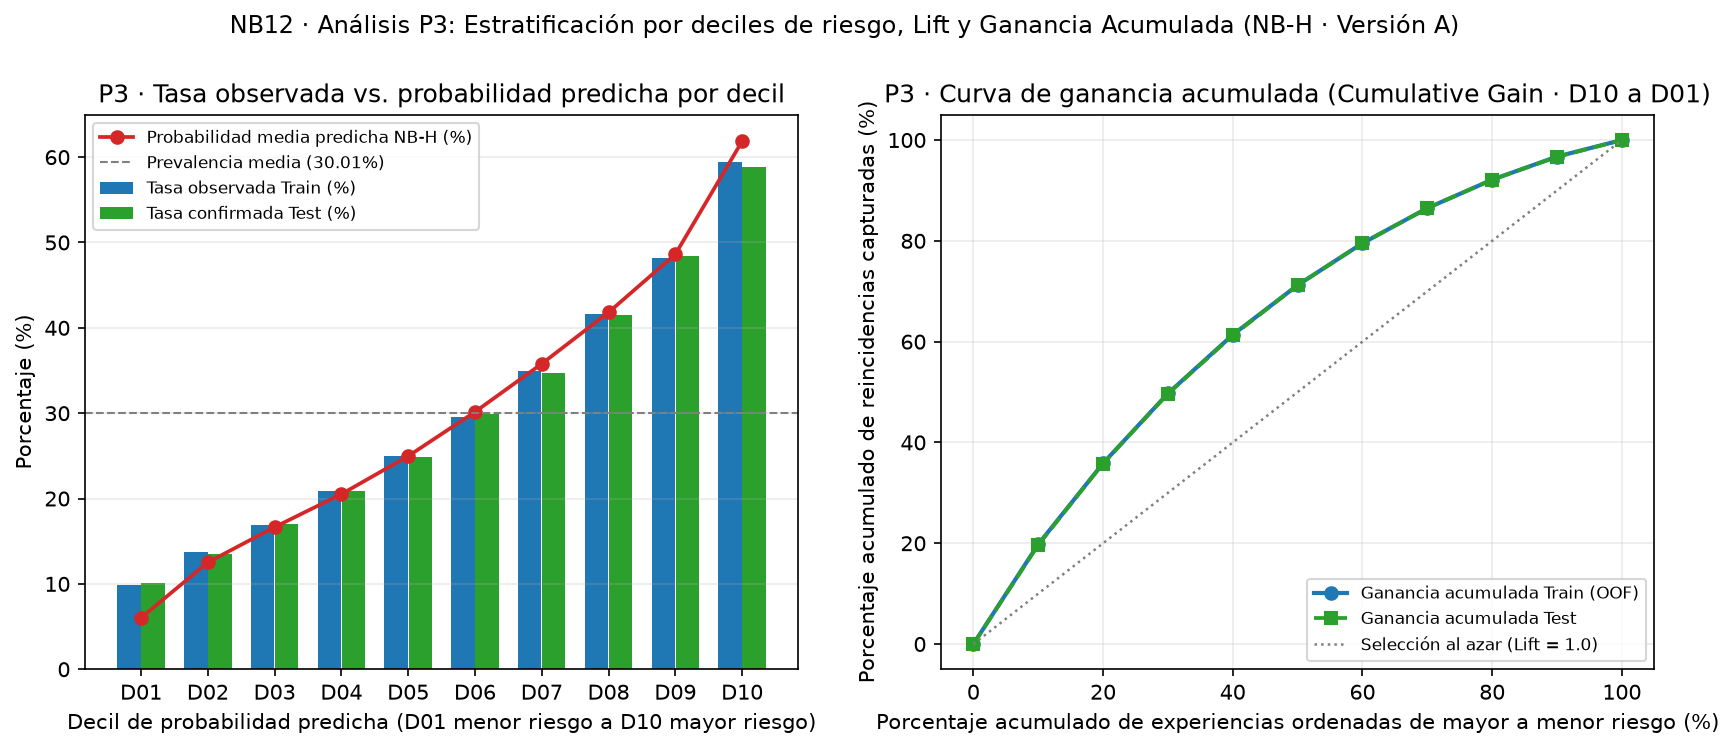

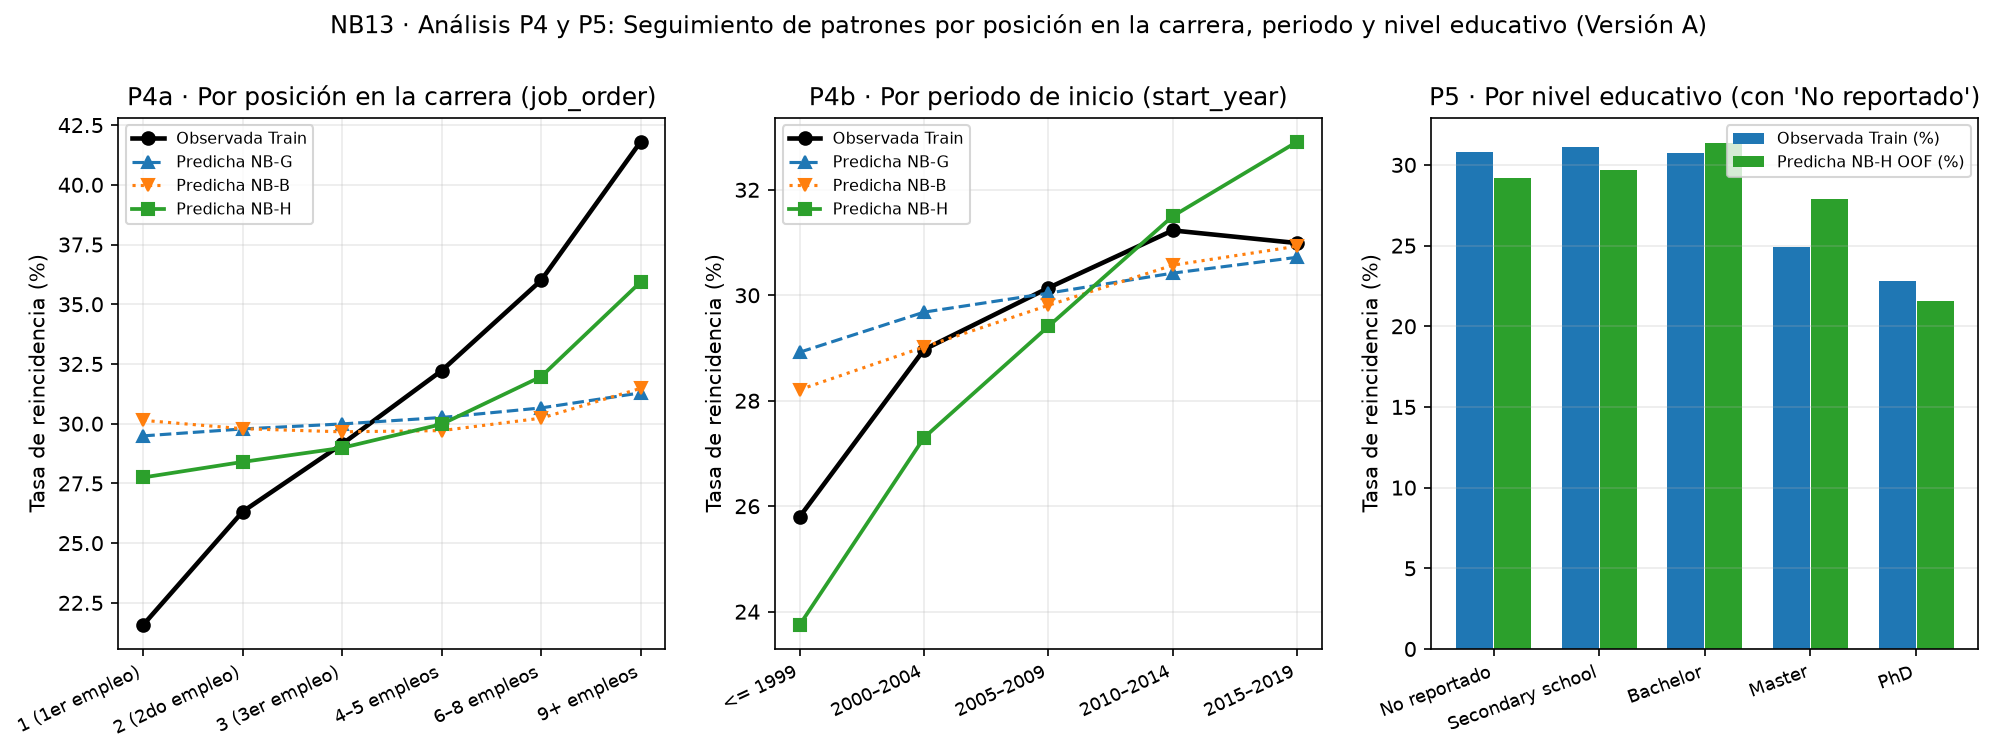

In [14]:
FIG_NB12 = PIPELINE.plotter.plot_p3_risk_deciles(PAT_BUNDLE)
FIG_NB13 = PIPELINE.plotter.plot_p4_and_p5_career_and_education(PAT_BUNDLE)

print("P3a · Tasa observada, Lift y Ganancia Acumulada por decil de probabilidad predicha (NB-H):")
display(PAT_BUNDLE.p3_deciles_table)
print("P3b · Perfil promedio en unidades originales del decil superior (D10) frente al decil inferior (D01) en Train (OOF) y Test:")
display(PAT_BUNDLE.p3_top_vs_bottom_profile_table)
print("P3c · Composición por gran grupo ISCO-08 en D10 vs. D01 (Train OOF y Test):")
display(PAT_BUNDLE.p3_isco_composition_deciles_table)
print("P4a · Tasas observadas y predichas por orden del empleo (job_order) y brecha por tramo:")
display(PAT_BUNDLE.p4_job_order_table)
print("P4c · Resumen cuantitativo de pendiente capturada por NB-H en job_order (rango predicho / rango observado):")
display(PAT_BUNDLE.p4_job_order_slope_summary_table)
print("P4b · Tasas observadas y predichas por período de inicio (start_year):")
display(PAT_BUNDLE.p4_start_year_table)
print("P5 · Desempeño y tasas por nivel educativo (conservando 'No reportado' como categoría propia, con brecha train vs. test):")
display(PAT_BUNDLE.p5_education_table)
display(Image(filename=str(FIG_NB12)))
display(Image(filename=str(FIG_NB13)))

### Lectura

Los análisis `P3`, `P4` y `P5` (Tablas `10_p3a`–`10_p5` y Figuras `NB12` y `NB13`) confirman la capacidad de estratificación de riesgo y la fidelidad con que `NB-H` reproduce los gradientes del dominio:

1. **Estratificación por deciles de riesgo, *Lift* y Ganancia Acumulada (`P3`, Figura `NB12`):**
   - El ordenamiento de `NB-H` es estrictamente monótono a lo largo de los 10 deciles tanto en OOF `train` como en `test`:
     - En el **decil superior `D10`** (`probabilidad >= 53.32 %`), la tasa observada de reincidencia es del **`59.39 %` en `train`** y se confirma en **`58.89 %` en `test`**, lo que representa un ***Lift* de `1.979x` en `train` y `1.965x` en `test`** sobre la prevalencia base.
     - En el **decil inferior `D01`** (`probabilidad <= 10.16 %`), la tasa observada cae a **`9.84 %` en `train` y `10.05 %` en `test`** (*Lift* de `0.328x` y `0.335x`), generando una razón de tasas **`D10 / D01` de `6.04 veces`** (diferencia absoluta de **`+49.55 pp`** en `train` y **`+48.84 pp`** en `test`).
     - **Ganancia acumulada:** priorizando únicamente el **`30 %` de las experiencias de mayor puntaje (`D10 + D09 + D08`)**, el modelo captura el **`49.72 %` de todas las reincidencias en `train` y el `49.66 %` en `test`**; y con el `50 %` superior (`D10` a `D06`) captura el **`71.21 %`** de todos los casos positivos en ambas particiones.
   - **Perfil en unidades originales de `D10` frente a `D01` (`10_p3b` y `10_p3c`):** frente al decil de menor riesgo (`D01`), el decil crítico (`D10`) tiene empleos casi **5 veces más cortos** (media `6.19` vs. `30.04` trimestres; mediana `5.0` vs. `13.0`), **`+1.39` empleos previos más** (`3.85` vs. `2.46`), casi ningún empleo vigente (`0.90 %` vs. `16.24 %`), mayor exigencia de competencias esenciales (`31.69` vs. `20.47`) y una fuerte concentración en `3 · Técnicos de nivel medio` (**`47.58 %` de `D10`**, sobremuestreo de `2.43x`) y `2 · Profesionales científicos e intelectuales` (**`36.99 %` de `D10`**, `2.11x`).
2. **Posición en la carrera y periodo de inicio (`P4`, Figura `NB13`):**
   - La tasa real de reincidencia sube de forma sostenida con el orden del empleo (`job_order`): de **`21.58 %`** en el primer empleo (`n = 263,187`; `21.52 %` en `test`) a **`29.15 %`** en el tercero, **`36.00 %`** entre el 6.º y 8.º, y **`41.80 %`** en quienes acumulan `9+` empleos (`n = 102,710`; `42.08 %` en `test`).
   - Mientras que `NB-B` permanece casi plano frente a `job_order` (`30.14 %` a `31.48 %`, pues carece de esa variable), **`NB-H` sigue la pendiente real** desde `27.75 %` (`1er empleo`) hasta `35.93 %` (`9+ empleos`), y también acompaña el gradiente temporal por periodo de inicio (`start_year`) desde `<= 1999` (`25.80 %` observado vs. `23.75 %` predicho por `NB-H`) hasta `2010–2014` (`31.23 %` observado vs. `31.50 %` predicho).
3. **Nivel educativo con `"No reportado"` como categoría propia (`P5`, Figura `NB13`):**
   - Los niveles reportados de secundaria (`31.09 %`, `n = 548,687`) y grado (`Bachelor`, `30.75 %`, `n = 473,842`) presentan unos `6 pp` más de reincidencia que posgrado (`Master = 24.93 %`, `n = 201,851`; `PhD = 22.83 %`, `n = 5,974`).
   - El grupo **`"No reportado"` (`11.55 %` de `train`, `160,664` filas)** exhibe una tasa observada de **`30.80 %`** (`30.54 %` en `test`) y un desempeño del modelo (**`PR-AUC = 0.4801`**, `ROC-AUC = 0.6971`, **`F1 = 0.5353`** en `test`) a la par de `Secondary school` y `Bachelor`, mientras que el menor `PR-AUC` y `F1` ocurre en `PhD` (`PR-AUC = 0.3078`, `F1 = 0.3847` en `test`) debido a su menor prevalencia base (`21.66 %`) y alta especialización.

---

### 10.6 Bloque 2 (Patrones Generales) · Análisis `P6`, `P7` y `P8`: Análisis de errores, ablación por bloques de comportamiento e independencia condicional

**¿Qué hace?** Presenta el análisis de errores `P6` (perfil en unidades originales de verdaderos positivos `TP`, falsos positivos `FP`, falsos negativos `FN` y verdaderos negativos `TN`, junto con las tasas `FPR` y `FNR` por subgrupo), el estudio de ablación `P7` en validación cruzada agrupada sobre `train` (efecto en `PR-AUC`, `ROC-AUC` y `Brier` al retirar cada uno de los 5 bloques de comportamiento: Temporal, Duración y carrera, Educación, Competencias y Ocupación) y la auditoría de independencia `P8` (efecto en `PR-AUC` y `Brier` al eliminar una variable de cada par altamente correlacionado detectado en la Sección 3), junto con la figura `NB14`.

**¿Por qué existe?** Permite diagnosticar dónde se equivoca el clasificador (`P6`), cuantificar sin tocar `test` cuál de los cinco comportamientos aporta más poder predictivo (`P7`) y demostrar con datos si el doble conteo por violación de independencia condicional perjudica la discriminación (`PR-AUC`) o la calibración (`Brier`) de Naive Bayes (`P8`).

**¿Qué recibe y qué entrega?** Recibe `PAT_BUNDLE`. Entrega las tablas `P6a`, `P6b`, `P7` y `P8` y la figura `nb14_p7_p8_ablacion_bloques_e_independencia.png`.

**Papel en el proyecto.** Cierra la evidencia analítica de la Sección 10 respondiendo con experimentos controlados en CV las preguntas sobre ablación e independencia.

P6a · Perfil en unidades originales de TP, FP, FN y TN (en umbral OOF tau* de NB-H):


,celda_confusion,soporte_oof_train,pct_total_train,soporte_test,pct_total_test,prob_media_predicha_pct,empleos_previos_mediana,empleos_previos_media,duracion_mediana_trimestres,duracion_media_trimestres,anio_inicio_mediana,skills_esenciales_mediana,pct_empleo_vigente,gran_grupo_isco_modal,nivel_educativo_modal
0,"TP · Verdadero Positivo (reincide=1, pred=1)",304368,21.8800,75861,21.8200,46.1200,3.0000,3.6400,5.0000,8.3000,2011,22.0000,3.0400,5 · Trabajadores de los servicios y vendedores,Secondary school
1,"FP · Falso Positivo (reincide=0, pred=1)",417318,30.0000,104175,29.9600,40.8000,2.0000,2.8800,5.0000,9.2200,2011,22.0000,2.8300,5 · Trabajadores de los servicios y vendedores,Secondary school
2,"FN · Falso Negativo (reincide=1, pred=0)",113103,8.1300,28364,8.1600,17.6900,3.0000,3.1500,5.0000,17.4500,2009,18.0000,10.0600,2 · Profesionales científicos e intelectuales,Secondary school
3,"TN · Verdadero Negativo (reincide=0, pred=0)",556229,39.9900,139320,40.0700,15.3100,2.0000,2.6600,7.0000,17.1300,2010,18.0000,7.8500,2 · Profesionales científicos e intelectuales,Secondary school


P6b · Subgrupos con mayor concentracion de Falsos Positivos (FPR) y Falsos Negativos (FNR):


,dimension,subgrupo,soporte_train,tasa_error_global_pct,FPR_tasa_falsos_positivos_pct,FNR_tasa_falsos_negativos_pct,tipo_fallo_dominante
0,Gran grupo ISCO,0 · Ocupaciones militares,3393,8.4900,1.1500,100.0000,Falsos Negativos (omisión de reincidencia)
1,Gran grupo ISCO,1 · Directores y gerentes,81000,28.7200,21.7400,53.3600,Falsos Negativos (omisión de reincidencia)
2,Gran grupo ISCO,2 · Profesionales científicos e intelectuales,243705,33.4700,35.8300,27.9500,Falsos Positivos (sobrepredicción)
3,Gran grupo ISCO,3 · Técnicos y profesionales de nivel medio,272574,39.4400,49.3200,20.0300,Falsos Positivos (sobrepredicción)
4,Gran grupo ISCO,4 · Personal de apoyo administrativo,111705,30.4600,21.8900,60.0500,Falsos Negativos (omisión de reincidencia)
5,Gran grupo ISCO,5 · Trabajadores de los servicios y vendedores,302706,45.7300,60.6600,16.5500,Falsos Positivos (sobrepredicción)
6,Gran grupo ISCO,6 · Agricultores y trabajadores agropecuarios,5080,43.1500,45.7900,33.2700,Falsos Positivos (sobrepredicción)
7,Gran grupo ISCO,"7 · Oficiales, operarios y artesanos",100371,31.8500,26.9000,48.3100,Falsos Negativos (omisión de reincidencia)
8,Gran grupo ISCO,8 · Operadores de instalaciones y máquinas,80665,30.3500,26.8500,41.0300,Falsos Negativos (omisión de reincidencia)
9,Gran grupo ISCO,9 · Ocupaciones elementales,189819,45.6700,58.1700,20.3300,Falsos Positivos (sobrepredicción)


P7 · Ablacion por bloques de comportamiento en StratifiedGroupKFold (5 folds sobre Train, sin tocar Test):


,experimento_ablacion,variables_retiradas,n_columnas_activas,pr_auc_cv_media,cambio_pr_auc_vs_completo,roc_auc_cv_media,cambio_roc_auc_vs_completo,brier_cv_media,cambio_brier_vs_completo
0,0. Modelo completo NB-H (Referencia),"Ninguno (2,981 columnas)",2981,0.4981,0.0000,0.7058,0.0000,0.1872,0.0000
1,1. Sin bloque Temporal,"start_ord_rob, end_ord_rob (2 cols)",2979,0.4984,0.0003,0.7060,0.0002,0.1871,-0.0001
2,2. Sin bloque Duración y carrera,"dur_q_rob, dur_q_bin, job_order_rob, es_vigente (4 cols)",2977,0.4868,-0.0114,0.7006,-0.0052,0.1885,0.0013
3,3. Sin bloque Educación,univ_ord_mm (1 col),2980,0.4981,-0.0001,0.7058,-0.0000,0.1872,0.0000
4,4. Sin bloque Competencias ESCO,"n_skills_essential_rob/bin, n_skills_knowledge_rob, n_skills_sin_tipo_rob, tiene_* (7 cols)",2974,0.5022,0.0040,0.7081,0.0023,0.1865,-0.0007
5,5. Sin bloque Ocupación OHE,"occupation_code_* (2,967 dummies)",14,0.3735,-0.1246,0.5892,-0.1166,0.2064,0.0192


P8 · Auditoria de independencia condicional sobre pares correlacionados en CV agrupado (NB-H y NB-G):


,experimento_independencia,variable_retirada,correlacion_del_par,NB_H_pr_auc_cv,NB_H_delta_pr_auc,NB_H_brier_cv,NB_H_delta_brier,NB_G_pr_auc_cv,NB_G_delta_pr_auc,NB_G_brier_cv,NB_G_delta_brier
0,0. Referencia sin retirar pares correlacionados,Ninguna,—,0.4981,0.0000,0.1872,0.0000,0.3775,0.0000,0.2087,0.0000
1,"Par 1: (n_skills_essential_rob, n_skills_essential_bin) -> retirar bin",n_skills_essential_bin,rho = 0.968 (discretización redundante del mismo conteo),0.4994,0.0013,0.1868,-0.0004,0.3758,-0.0017,0.2090,0.0002
2,"Par 1b: (n_skills_essential_rob, n_skills_essential_bin) -> retirar rob",n_skills_essential_rob,rho = 0.968 (conservar solo tramo cuantil),0.5000,0.0019,0.1868,-0.0004,0.3820,0.0045,0.2089,0.0001
3,"Par 2: (dur_q_rob, dur_q_bin) -> retirar bin",dur_q_bin,rho = 0.962 (discretización redundante de dur_q),0.4972,-0.0009,0.1873,0.0001,0.3751,-0.0024,0.2088,0.0001
4,"Par 2b: (dur_q_rob, dur_q_bin) -> retirar rob",dur_q_rob,rho = 0.962 (conservar solo tramo cuantil),0.4977,-0.0004,0.1870,-0.0002,0.3750,-0.0025,0.2091,0.0004
5,"Par 3: (start_ord_rob, end_ord_rob) -> retirar end_ord_rob",end_ord_rob,r = 0.785 (fechas de inicio y fin acopladas),0.4981,0.0000,0.1871,-0.0000,0.3775,-0.0000,0.2087,0.0000
6,"Par 4: (end_ord_rob, es_vigente) -> retirar es_vigente",es_vigente,rho = 0.655 (censura en 2026-Q1 cuando es_vigente=1),0.4985,0.0004,0.1870,-0.0001,0.3775,0.0000,0.2087,0.0000
7,"Par 5: (n_skills_essential_rob, n_skills_knowledge_rob) -> retirar knowledge",n_skills_knowledge_rob,r = 0.784 (conocimientos contenidos en esenciales),0.4992,0.0010,0.1871,-0.0001,0.3772,-0.0003,0.2088,0.0000
8,Conjunto depurado: retirar ambos bins duplicados (dur_q_bin + n_skills_essential_bin),"dur_q_bin, n_skills_essential_bin",Elimina simultáneamente el doble conteo de las dos variables discretizadas,0.4986,0.0004,0.1870,-0.0002,0.3747,-0.0028,0.2091,0.0004
9,Conjunto depurado completo: retirar bins + end_ord_rob + n_skills_knowledge_rob,"dur_q_bin, n_skills_essential_bin, end_ord_rob, n_skills_knowledge_rob",Elimina los 4 focos principales de colinealidad remanente en el bloque denso,0.4995,0.0014,0.1868,-0.0004,0.3744,-0.0032,0.2091,0.0004


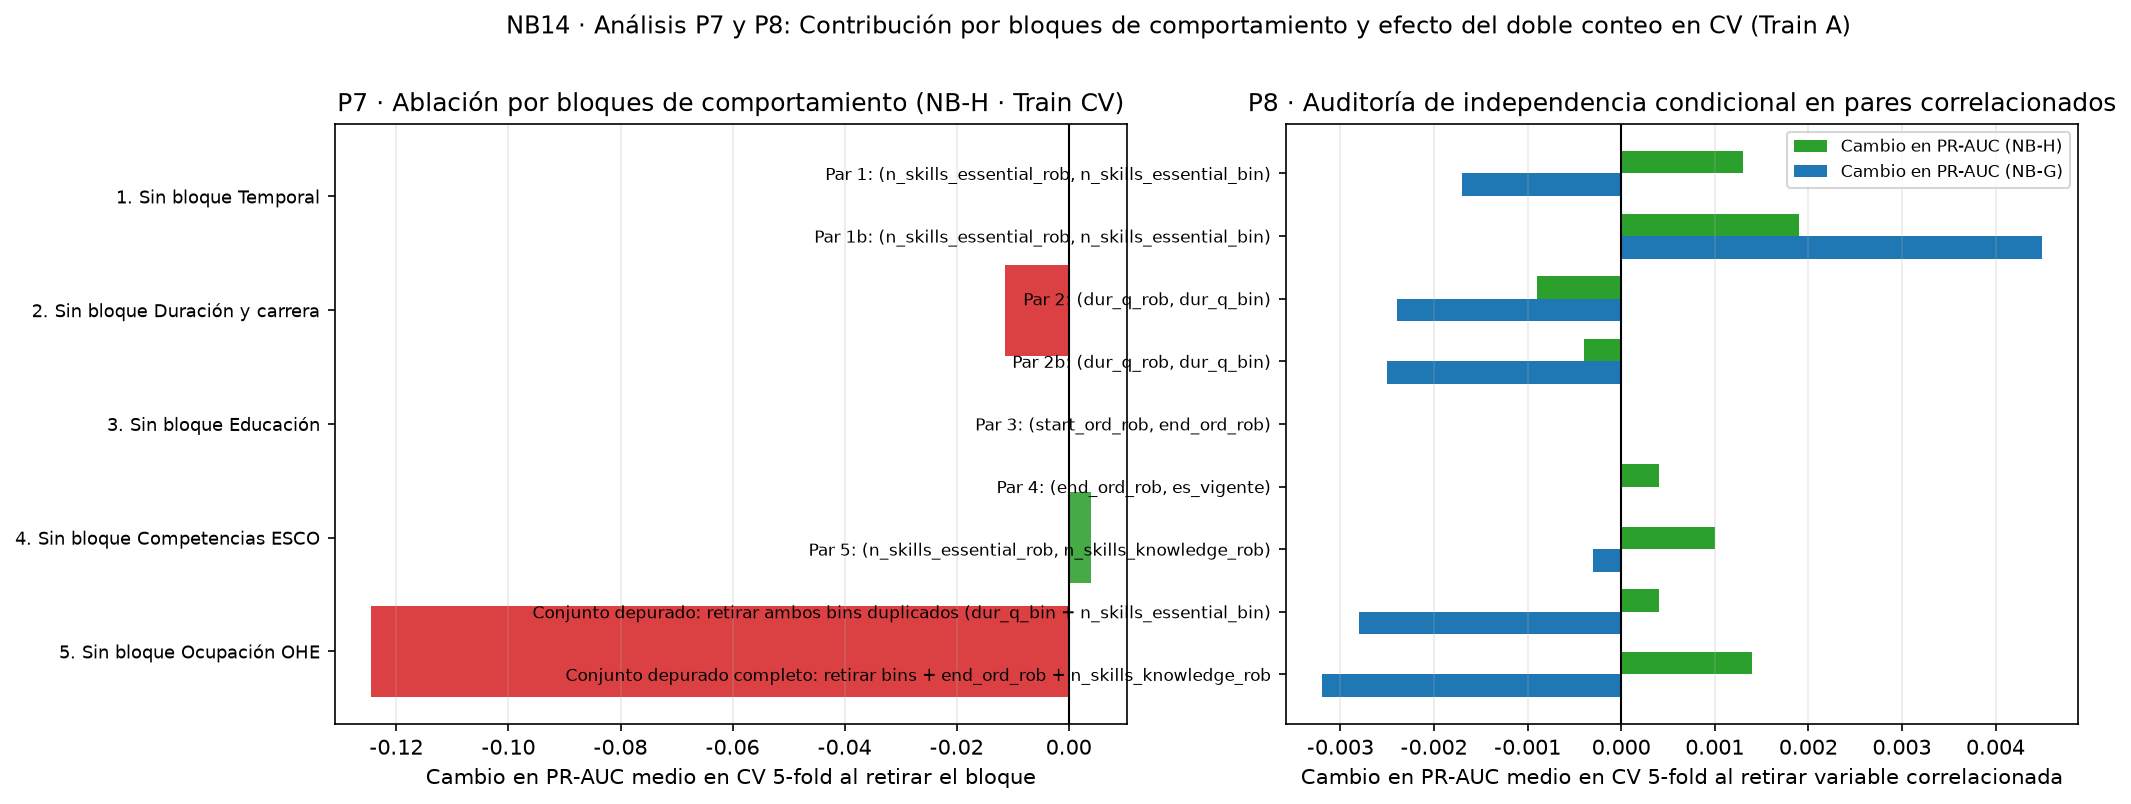

In [15]:
FIG_NB14 = PIPELINE.plotter.plot_p7_and_p8_ablation_and_independence(PAT_BUNDLE)

print("P6a · Perfil en unidades originales de TP, FP, FN y TN (en umbral OOF tau* de NB-H):")
display(PAT_BUNDLE.p6_error_profiles_table)
print("P6b · Subgrupos con mayor concentración de Falsos Positivos (FPR) y Falsos Negativos (FNR):")
display(PAT_BUNDLE.p6_error_subgroups_table)
print("P7 · Ablación por bloques de comportamiento en StratifiedGroupKFold (5 folds sobre Train, sin tocar Test):")
display(PAT_BUNDLE.p7_block_ablation_cv_table)
print("P8 · Auditoría de independencia condicional sobre pares correlacionados en CV agrupado (NB-H y NB-G):")
display(PAT_BUNDLE.p8_independence_audit_cv_table)
display(Image(filename=str(FIG_NB14)))

### Lectura

Los análisis `P6`, `P7` y `P8` (Tablas `10_p6a`–`10_p8` y Figura `NB14`) completan la radiografía interna del clasificador:

1. **Anatomía de los errores de clasificación (`P6a` y `P6b`):**
   - Al operar `NB-H` en su umbral óptimo OOF ($\tau^* = 0.2650$, diseñado para maximizar `F1` elevando la sensibilidad a `72.79 %`), el error predominante en volumen es el **Falso Positivo (`FP`)**: representa el `30.00 %` de `train` (`417,318` filas) y el `29.96 %` de `test` (`104,175` filas), frente a solo un **`8.13 %` de Falsos Negativos (`FN`)** en `train` (`113,103` filas) y `8.16 %` en `test` (`28,364` filas).
   - **Por qué ocurren los `FP`:** su perfil en unidades originales (`mediana 2.0` empleos previos, `5.0` trimestres de duración, `22.0` competencias esenciales, grupo modal `5 · Servicios y vendedores`) es casi idéntico al de los **Verdaderos Positivos (`TP`)** (`mediana 3.0` empleos previos, `5.0` trimestres, `22.0` competencias, grupo modal `5`). Son personas que entran por primera vez a un oficio de altísima rotación (como asistente administrativo, vendedor o cuidador); el modelo les asigna probabilidad media de `40.80 %` porque el oficio es muy repetitivo en la población, aunque esa persona particular solo lo haya ejercido una vez. Por eso la tasa de falsos positivos (`FPR`) se concentra en `5 · Servicios y vendedores` (`60.66 %`), `9 · Ocupaciones elementales` (`58.17 %`) y `3 · Técnicos de nivel medio` (`49.32 %`).
   - **Por qué ocurren los `FN`:** tienen una duración media el doble de larga (**`17.45` trimestres** frente a `8.30` en los `TP`) y más del triple de empleos vigentes (**`10.06 %`** frente a `3.04 %` en los `TP`), concentrándose en grupos de baja tasa base donde el *log-ratio* ocupacional es negativo: `0 · Militares` (`FNR = 100.00 %`), `4 · Apoyo administrativo` (`FNR = 60.05 %`), `1 · Directores y gerentes` (`FNR = 53.36 %`) y `7 · Oficiales y operarios` (`FNR = 48.31 %`).
2. **Ablación por bloques de comportamiento en CV agrupado (`P7`, Figura `NB14`):**
   - Partiendo del modelo `NB-H` completo en CV (`PR-AUC = 0.4981`, `ROC-AUC = 0.7058`, `Brier = 0.1872`):
     1. **El bloque de Ocupación (`2,967` *dummies* `occupation_code_*`) es, por amplio margen, el que más aporta:** al retirarlo, el `PR-AUC` cae en **`-0.1246`** (hasta `0.3735`), el `ROC-AUC` cae en **`-0.1166`** (hasta `0.5892`) y el `Brier` empeora en `+0.0192`.
     2. **El bloque de Duración y carrera (`dur_q_rob`, `dur_q_bin`, `job_order_rob`, `es_vigente`) es el segundo bloque legítimo más valioso:** al retirarlo, el `PR-AUC` cae en **`-0.0114`** (hasta `0.4868`) y el `ROC-AUC` baja en `-0.0052` (hasta `0.7006`).
     3. **Educación (`univ_ord_mm`) y Temporal (`start_ord_rob`, `end_ord_rob`)** tienen un efecto marginal nulo ($\Delta\text{PR-AUC} = -0.0001$ y $+0.0003$).
     4. **Retirar el bloque de Competencias ESCO (`7` columnas) mejora levemente el `PR-AUC` de `NB-H` en `+0.0040` (hasta `0.5022`, con `ROC-AUC = 0.7081`):** ¿por qué? Porque las competencias ESCO son una función determinística del código de ocupación (`occupation_code`); cuando las `2,967` *dummies* de ocupación ya están en el modelo, agregar además `7` columnas de conteos y *bins* de competencias introduce **doble conteo de la misma información del oficio** bajo el supuesto ingenuo de independencia.
3. **Auditoría de independencia condicional sobre pares correlacionados (`P8`, Figura `NB14`):**
   - En `NB-H`, eliminar la variable continua redundante del par `(n_skills_essential_rob, n_skills_essential_bin)` sube el `PR-AUC` en **`+0.0019`** (a `0.5000`) y reduce el `Brier` en `-0.0004`; retirar `n_skills_knowledge_rob` (correlacionada $r = 0.6074$ con `n_skills_essential_rob`) sube el `PR-AUC` en **`+0.0010`**; y retirar simultáneamente los 4 focos de colinealidad remanente (`dur_q_bin`, `n_skills_essential_bin`, `end_ord_rob`, `n_skills_knowledge_rob`) eleva el `PR-AUC` en **`+0.0014`** (a `0.4995`) mejorando el `Brier` (`-0.0004`).
   - En `NB-G` (que no tiene las `2,967` *dummies* de ocupación y por tanto depende de las diferencias no lineales que capturan los *bins*), retirar los dos *bins* reduce ligeramente el `PR-AUC` (`-0.0028`), pero sustituir `n_skills_essential_rob` por su *bin* `n_skills_essential_bin` (que no sufre la cola derecha pesada de `99` competencias) mejora el `PR-AUC` de `NB-G` en **`+0.0045`** (de `0.3775` a `0.3820`).
   - **Conclusión de `P8`:** el doble conteo entre las competencias ESCO y las *dummies* de ocupación (así como entre variables continuas y sus *bins*) **sí resta ligeramente precisión y calibración en `NB-H`**, aunque el suavizado `var_smoothing = 1.0` ya absorbe la mayor parte de esa redundancia.

---

### 10.7 Síntesis de patrones de negocio (7 hallazgos con evidencia, soporte y advertencias)

A continuación se consolidan los **7 patrones principales** extraídos en unidades originales sobre la **Versión A** (`1,391,018` experiencias en `train` y `347,720` en `test`), de los cuales **los cuatro primeros se centran directamente en los grupos ocupacionales ISCO-08**:

1. **Brecha estructural de `26.4 pp` en la reincidencia entre grandes grupos ocupacionales (`O1`):**
   - **Evidencia y soporte:** la repetición de oficio está liderada por **`5 · Trabajadores de los servicios y vendedores`** (`33.84 %` en `train`, IC 95 % `[33.67, 34.01]`, `n = 302,706`; `33.87 %` en `test`, `n = 75,803`), **`3 · Técnicos y profesionales de nivel medio`** (`33.72 %` en `train`, `n = 272,574`; `33.37 %` en `test`) y **`9 · Ocupaciones elementales`** (`33.03 %` en `train`, `n = 189,819`; `33.05 %` en `test`), superando en más de `11 pp` a **`1 · Directores y gerentes`** (`22.07 %`, `n = 81,000`), **`4 · Apoyo administrativo`** (`22.46 %`, `n = 111,705`) y **`6 · Agricultores`** (`21.12 %`, `n = 5,080`), y en `26.41 pp` a **`0 · Ocupaciones militares`** (`7.43 %`, `n = 3,393`).
   - **Advertencia de interpretación:** asociación descriptiva del mercado laboral flamenco registrada en los currículums; refleja la estructura contractual de cada sector y no un efecto causal del grupo ISCO sobre la conducta individual.

2. **Alta concentración de la señal predictiva en profesionales, técnicos y operadores, frente a opacidad en apoyo administrativo (`O2` y `O3`):**
   - **Evidencia y soporte:** `NB-H` alcanza su máximo poder discriminante dentro de **`2 · Profesionales científicos e intelectuales`** (`PR-AUC = 0.5565`, *lift* `1.847x`, `ROC-AUC = 0.7407`, `n_test = 61,082`), **`3 · Técnicos de nivel medio`** (`PR-AUC = 0.5291`, `F1 = 0.5746`, `n_test = 68,181`) y **`8 · Operadores de instalaciones y máquinas`** (`PR-AUC = 0.4615`, *lift* `1.868x`, `ROC-AUC = 0.7206`, `n_test = 20,103`), impulsado por desplazamientos medios del *log-odds* ocupacional de `+0.9647`, `+0.7652` y `+0.8189` respectivamente. En cambio, en **`4 · Personal de apoyo administrativo`** (`n_test = 27,784`) el desplazamiento ocupacional es de solo `+0.2499` y el `PR-AUC` baja a `0.3142`.
   - **Advertencia de interpretación:** en los sectores donde los códigos ESCO son muy específicos el modelo separa con nitidez; en áreas con etiquetas genéricas de oficina hace falta información contractual externa que no existe en los insumos.

3. **Polarización intra-grupo a 2 y 4 dígitos: oficios de rotación recurrente frente a oficios de paso único (`O5` y `P1b`):**
   - **Evidencia y soporte:** dentro de un mismo gran grupo ISCO coexisten regímenes opuestos. En `5 · Servicios y vendedores`, el subgrupo `53` (*Child care workers*, `40.50 %`, `n = 50,888`) y los oficios `5312.1 · early years teaching assistant` (`62.65 %` en `train`, `62.04 %` en `test`, `n = 6,013`, $\text{LLR} = +1.3639$) y `5321.1 · healthcare assistant` (`60.62 %`, `n = 6,519`, $\text{LLR} = +1.2782$) triplican la tasa del subgrupo `54` (*Security guards*, `19.33 %`, `n = 7,176`). Del mismo modo, en `2 · Profesionales` sobresalen `2264.2 · physiotherapist` ($\text{LLR} = +2.1381$, `n = 2,138`), `2221.2 · nurse responsible for general care` ($\text{LLR} = +1.4591$, `n = 6,236`) y `2330.1.12 · modern languages teacher` ($\text{LLR} = +1.4189$, `n = 6,900`), mientras que en `3 · Técnicos` domina `3343.1 · administrative assistant` (`57.02 %`, `n = 66,819`).
   - **Advertencia de interpretación:** **circularidad parcial estructural (`N:1`)**: como `reincide` se define contando repeticiones de `(resume_id, occupation_code)`, la *dummy* de ocupación actúa como huella de oficios con contratación estacional, por reemplazos o por turnos, no como causa.

4. **Acoplamiento entre persistencia inter-empleo y reincidencia predicha, con rotación lateral en profesionales (`O6`):**
   - **Evidencia y soporte:** entre los `10` grandes grupos ISCO (`1,109,344` transiciones clasificadas en `train`), la persistencia en el mismo gran grupo en el siguiente empleo se asocia fuertemente con la probabilidad media predicha por `NB-H` (**$r = 0.8604$, $p = 0.0014$; $\rho = 0.8061$, $p = 0.0049$**), y el autolazo en el mismo oficio correlaciona en **$r = 0.9837$**. No obstante, **`2 · Profesionales científicos e intelectuales`** registra la mayor persistencia de gran grupo (`47.37 %` en `train`, `47.20 %` en `test`, `n_trans = 192,820`) pero una reincidencia moderada (`29.98 %`), porque gran parte de sus transiciones son movimientos laterales hacia otros códigos ESCO dentro del mismo grupo `2` (`19.63 %` en el mismo ISCO a 4 dígitos vs. `12.68 %` en el mismo oficio exacto).
   - **Advertencia de interpretación:** correlación ecológica calculada sobre solo $n = 10$ grupos agregados y restringida a empleos con ocupación clasificada; describe estructura de movilidad, no causalidad.

5. **Ley empírica intra-grupo de antigüedad y duración: quien repite oficio acumula más empleos previos y episodios más breves en los 10 sectores (`O3b`, `O4`, `P1a` y `P4`):**
   - **Evidencia y soporte:** a nivel global, la tasa de reincidencia casi se duplica desde el **primer empleo (`21.58 %`, `n = 263,187`)** hasta quienes tienen **`9+` empleos (`41.80 %`, `n = 102,710`)**, y el LLR gaussiano de `dur_q` es positivo entre **`2.0` y `25.0` trimestres** y negativo a partir de **`28.0` trimestres**. Esta diferencia se mantiene dentro de cada uno de los `10` grandes grupos ISCO (`O3b`): los reincidentes tienen entre **`+0.55` y `+1.77` empleos previos más** y duraciones medias entre **`-1.62` y `-3.94` trimestres más cortas** que los no reincidentes del mismo grupo.
   - **Advertencia de interpretación:** asociación longitudinal ligada al orden cronológico del currículum (en el primer empleo la tasa no es cero solo por empates de fecha de inicio o registros simultáneos, pero el espacio de oficios previos crece mecánicamente con `job_order`).

6. **Capacidad operativa de priorización por deciles: el decil superior (`D10`) concentra 6 veces más reincidencia que el inferior (`D01`) (`P3`):**
   - **Evidencia y soporte:** el decil `D10` de `NB-H` (`n_train = 139,102`, `n_test = 34,772`) alcanza una tasa real de **`59.39 %` en `train` y `58.89 %` en `test`** (*Lift* = **`1.965x`**), frente a **`9.84 %` en `train` y `10.05 %` en `test`** en `D01` (*Lift* = `0.335x`). El `30 %` superior de puntajes (`D10–D08`) captura el **`49.66 %`** de todas las reincidencias de `test`, con un perfil en `D10` caracterizado por empleos cortos (`media 6.19` trimestres vs. `30.04` en `D01`), no vigentes (`0.90 %` vs. `16.24 %`) y concentrados en los grupos ISCO `3` (`47.58 %`) y `2` (`36.99 %`).
   - **Advertencia de interpretación:** el puntaje prioriza probabilidad de repetición histórica, por lo que no debe usarse sin umbral diferenciado si se desea detectar casos raros en grupos de baja prevalencia como `0 · Militares` o `4 · Apoyo administrativo` (`P6b`).

7. **Redundancia entre el bloque de Competencias ESCO y las *dummies* de ocupación bajo el supuesto de independencia (`P7` y `P8`):**
   - **Evidencia y soporte:** en la ablación en CV agrupado (`P7`, `n = 1,391,018`), retirar las `2,967` *dummies* de ocupación desploma el `PR-AUC` en **`-0.1246`** (de `0.4981` a `0.3735`) y retirar el bloque de Duración y carrera lo reduce en **`-0.0114`** (a `0.4868`), pero **retirar las `7` variables de Competencias ESCO mejora el `PR-AUC` en `+0.0040` (hasta `0.5022`) y el `ROC-AUC` en `+0.0023` (hasta `0.7081`)**. De igual modo, en `P8`, eliminar las variables colineales/discretizadas (`dur_q_bin`, `n_skills_essential_bin`, `end_ord_rob`, `n_skills_knowledge_rob`) mejora el `PR-AUC` de `NB-H` en `+0.0014` y reduce el `Brier` en `-0.0004`.
   - **Advertencia de interpretación:** dado que los conteos de competencias ESCO son atributos fijos de cada `occupation_code`, incluirlos junto con las `2,967` *dummies* en un modelo Naive Bayes multiplica dos veces la verosimilitud del oficio; este efecto es una propiedad del supuesto de independencia condicional, no una falta de relevancia sustantiva de las competencias (que por sí solas en el Árbol 3 de `7.0` alcanzaban `ROC-AUC = 0.6157`).

---

## 11. Comparación homogénea en Versión A frente a `6.0`, referencias y árboles (`7.0`)

**¿Qué hace?** Re-crea y verifica los dos modelos base de `6.0` (`Logística Regularizada` con 2,981 columnas OHE e `HistGradientBoosting` con 14 columnas densas, ambos con `class_weight="balanced"`) frente a `resultados_test_ab.csv` dentro de una tolerancia de `5e-4`, presenta **comparaciones homogéneas por espacio de variables** (solo bloque denso de 14 columnas por un lado; modelos con ocupación OHE por otro), calcula **intervalos de confianza al 95 % por bootstrap pareado por persona** (`300` remuestreos idénticos por `resume_id`) para `delta PR-AUC`, `delta ROC-AUC` y `delta F1`, evalúa `F1`, precisión y exhaustividad a **igual tasa de alerta** (la que produce `NB-H` con su umbral OOF fijo, sin ajustar nada en `test`), restringe la comparación de Brier exclusivamente a modelos sin ponderación de clases y presenta la tabla consolidada con las referencias y los árboles de `7.0`.

**¿Por qué existe?** Comparar modelos con distinto número de variables (`14` vs. `2,981`), distinto esquema de ponderación de clases (`class_weight="balanced"` vs. empírico) o distinto umbral operativo introduce sesgos de comparación. Las pruebas pareadas y a igual tasa de alerta permiten distinguir diferencias reales (IC 95 % que excluye `0`) de fluctuaciones muestrales.

**¿Qué recibe y qué entrega?** Recibe `EVAL_BUNDLE`. Entrega las tablas `11a` (reproducción `6.0`), `11b` (homogénea densa), `11c` (homogénea con ocupación), `11d` (bootstrap pareado), `11e` (igual tasa de alerta) y `11` (consolidada).

**Papel en el proyecto.** Sustenta con rigor estadístico el lugar exacto de Naive Bayes dentro de la Fase 4 de JobPath.

In [16]:
print("11a · Verificación de reproducción de los modelos de 6.0 sobre Versión A (tolerancia <= 5e-4 en PR-AUC y ROC-AUC):")
display(EVAL_BUNDLE.phase4_reproduction_table)
print("11b · Comparación homogénea · Solo bloque denso (14 variables, sin ocupación · Brier solo modelos sin ponderar):")
display(EVAL_BUNDLE.like_for_like_dense_table)
print("11c · Comparación homogénea · Con ocupación OHE (2,971–2,981 variables · Brier solo modelos sin ponderar):")
display(EVAL_BUNDLE.like_for_like_occ_table)
print("11d · Bootstrap pareado por persona (300 remuestreos idénticos, semilla 42 · IC 95 % de diferencias A menos B):")
display(EVAL_BUNDLE.paired_bootstrap_comparisons_table)
print("11e · Métricas en Test a igual tasa de alerta que NB-H en su umbral OOF fijo (sin ajustar nada en Test):")
display(EVAL_BUNDLE.equal_alert_rate_table)
print("11 · Tabla consolidada en Test (Versión A · 347,720 filas) frente a Referencias 1–3 y Árboles de Decisión (7.0):")
display(EVAL_BUNDLE.final_comparison_table_a)

Comparacion final en Test (Version A · 347,720 filas) frente a Referencias 1, 2, 3 y Arboles de Decision (7.0):


,familia,modelo,punto_operacion,n_variables_X,test_pr_auc,test_roc_auc,test_f1_clase_1,delta_f1_vs_ref2_04612,pct_del_techo_roc_auc_07133,test_recall_clase_1,test_precision_clase_1,test_accuracy,test_brier,tiempo_fit_s,memoria_mb
0,Referencia,Ref 1 · Baseline Mayoritario (0),Predice siempre 0 (no reincide),0,0.2997,0.5000,0.0000,-0.4612,0.0000,0.0000,0.0000,0.7003,0.2997,NaN,NaN
1,Referencia,Ref 2 · Trivial Todo-Positivo (1),Predice siempre 1 (reincide),0,0.2997,0.5000,0.4612,0.0000,0.0000,1.0000,0.2997,0.2997,0.7003,NaN,NaN
2,Referencia,Ref 3 · Techo 6.0 (Logística OHE),"Combina simultáneamente oficio OHE, educación, competencias y trayectoria",2981,0.5109,0.7133,0.5321,0.0709,100.0000,0.6147,0.4691,0.6760,0.2108,NaN,NaN
3,Árbol de Decisión (7.0),Árbol 1 · ISCO [Exactitud (None)],Punto 1 · Orientado a Exactitud (class_weight=None),10,NaN,0.5459,0.0000,-0.4612,21.5200,0.0000,0.0000,0.7003,NaN,NaN,NaN
4,Árbol de Decisión (7.0),Árbol 1 · ISCO [Recall (balanced)],Punto 2 · Orientado a Recall / Sensibilidad (class_weight='balanced'),10,NaN,0.5459,0.4620,0.0008,21.5200,0.7961,0.3254,0.4443,NaN,NaN,NaN
5,Árbol de Decisión (7.0),Árbol 2 · Education level [Exactitud (None)],Punto 1 · Orientado a Exactitud (class_weight=None),2,NaN,0.5208,0.0000,-0.4612,9.7500,0.0000,0.0000,0.7003,NaN,NaN,NaN
6,Árbol de Decisión (7.0),Árbol 2 · Education level [Recall (balanced)],Punto 2 · Orientado a Recall / Sensibilidad (class_weight='balanced'),2,NaN,0.5208,0.4564,-0.0048,9.7500,0.8738,0.3088,0.3760,NaN,NaN,NaN
7,Árbol de Decisión (7.0),Árbol 3 · Skills [Exactitud (None)],Punto 1 · Orientado a Exactitud (class_weight=None),7,NaN,0.6145,0.1769,-0.2843,53.6800,0.1060,0.5363,0.7046,NaN,NaN,NaN
8,Árbol de Decisión (7.0),Árbol 3 · Skills [Recall (balanced)],Punto 2 · Orientado a Recall / Sensibilidad (class_weight='balanced'),7,NaN,0.6157,0.4550,-0.0062,54.2400,0.5421,0.3920,0.6107,NaN,NaN,NaN
9,Naive Bayes (7.1),NB-G (Umbral OOF óptimo (tau*)),tau = 0.2950,14,0.3778,0.5921,0.4687,0.0075,43.1800,0.8551,0.3228,0.4190,0.2086,0.2190,74.2900


### Lectura

La comparación consolidada sobre las `347,720` filas de `test` en la **Versión A** (Tabla `11`) posiciona con claridad a `NB-G`, `NB-B` y `NB-H` frente a las tres referencias y a los tres árboles de decisión de `7.0`:

1. **Superación de las Referencias 1 y 2 y los tres árboles de `7.0`:**
   - Mientras que los árboles de un solo bloque de `7.0` (profundidad máxima `4`) alcanzaban en la Versión A un `ROC-AUC` de `0.5208` (**Árbol 2 · Educación**, `9.75 %` del techo), `0.5459` (**Árbol 1 · ISCO**, `21.52 %` del techo) y `0.6157` (**Árbol 3 · Skills**, `54.24 %` del techo, con `F1 = 0.4550`, por debajo de la Referencia 2 de `0.4612`), el modelo **`NB-H` en su umbral OOF ($\tau^* = 0.2650$) alcanza `ROC-AUC = 0.7058` (`96.48 %` del techo de `0.7133`) y `F1 = 0.5337`**, superando la Referencia 2 (`0.4612`) por **`+0.0725` puntos de F1** (+7.25 pp) y mejorando en más de `+9.0` puntos de `ROC-AUC` al mejor árbol de `7.0`.
   - Incluso `NB-B` (`2,971` binarias, $\tau^* = 0.2700$) alcanza `ROC-AUC = 0.7024` (**`94.89 %` del techo**), `PR-AUC = 0.4829` y `F1 = 0.5323` ($\Delta\text{F1} = +0.0711$ contra `0.4612`).
   - En cambio, `NB-G` (`14` columnas densas sin las *dummies* de ocupación, $\tau^* = 0.2950$) se queda en `ROC-AUC = 0.5921` (`43.18 %` del techo), `PR-AUC = 0.3778` y `F1 = 0.4687` ($\Delta\text{F1} = +0.0075$), confirmando que sin la granularidad de `occupation_code_*` un modelo gaussiano univariado ni siquiera alcanza al Árbol 3 de competencias (`ROC-AUC = 0.6157`).
2. **Comparación frente a la Referencia 3 (Techo `6.0` · Regresión Logística Regularizada con OHE):**
   - La Regresión Logística con OHE (`2,981` columnas) conserva el techo de discriminación en ordenamiento (**`PR-AUC = 0.5109` vs. `0.4962` de `NB-H`**, brecha de `0.0147`; **`ROC-AUC = 0.7133` vs. `0.7058` de `NB-H`**, brecha de apenas `0.0075` puntos, capturando `NB-H` el **`96.48 %`** del recorrido sobre el azar).
   - Al mismo tiempo, gracias a la optimización honesta del umbral OOF ($\tau^* = 0.2650$) y a su suavizado de varianza (`var_smoothing = 1.0`), **`NB-H` alcanza un `F1` en `test` de `0.5337`** (frente a `0.5321` de la Regresión Logística con umbral `0.50` y peso balanceado) y un **mejor puntaje de Brier (`0.1871` vs. `0.2108`)**.
   - Además, `NB-H` supera en `PR-AUC` (`0.4962` vs. `0.4951`), `ROC-AUC` (`0.7058` vs. `0.6936`) y `F1` (`0.5337` vs. `0.5151`) al modelo no lineal `HistGradientBoosting` entrenado sobre las `14` variables densas en el cuaderno `6.0`.
3. **Criterios de recomendación para JobPath (poder predictivo, interpretabilidad y costo operativo):**
   - **Poder predictivo:** `NB-H` recupera el `96.48 %` del poder de discriminación ROC del modelo lineal completo y el `97.12 %` de su `PR-AUC` (`0.4962 / 0.5109`).
   - **Interpretabilidad:** ofrece una descomposición aditiva exacta en *log-odds* (`prior + suma de LLR por variable`), auditable caso por caso en gráficos `Waterfall` (`P2`) y por sector (`O3`).
   - **Costo operativo:** se entrena sobre `1.39` millones de filas y `2,981` columnas en **`0.634 s`** (`0.100 s` en `NB-B` y `0.219 s` en `NB-G`) usando solo **`118.19 MB`** de matriz de entrada (`36.74 MB` en `NB-B`), en una sola pasada analítica por conteos y medias sin iteraciones de gradiente.
   - **Límites del enfoque:** (i) la suposición de independencia condicional penaliza la inclusión simultánea de variables colineales o derivadas del mismo oficio (como los conteos ESCO junto con `occupation_code_*`), por lo que la Regresión Logística —que ajusta pesos conjuntos condicionales— mantiene una ventaja de `+0.0147` en `PR-AUC`; y (ii) `GaussianNB` asume simetría normal en variables que en realidad presentan fuerte asimetría positiva (`dur_q`, `job_order`).

---

## 12. Experimentos controlados de outliers (`E1`, `E2`, `E3`) y comparación con Versión B (`sin_outliers`)

**¿Qué hace?** Con los hiperparámetros ajustados de la Sección 6 ya fijados, ejecuta primero sobre la Versión A en RAM los tres experimentos controlados:
- **`E1` (sensibilidad ajustada por exclusión de filas extremas):** repite el entrenamiento con y sin filas fuera de las vallas de Tukey de `train` usando los hiperparámetros ajustados de la Sección 6 y re-selección honesta de umbral OOF en cada régimen.
- **`E2` (winsorización Tukey en RAM de las 7 columnas continuas):** ajusta vallas de Tukey únicamente en `train` para las 7 variables continuas (incluyendo `dur_q`, `job_order`, `start_ord` y `end_ord`, que Versión B no recorta), recorta `train` y `test`, re-entrena `NB-G` y `NB-H` con re-selección OOF de umbral y evalúa en `test` con IC 95 % pareados frente a A.
- **`E3` (interacción `var_smoothing` x variante en CV agrupado):** evalúa `NB-H` a lo largo de toda la rejilla `var_smoothing` de la Sección 6 en `StratifiedGroupKFold(5)` para **A**, **A winsorizada (E2)** y **B**, probando directamente si la regularización neutraliza las colas pesadas.

Posteriormente libera las estructuras pesadas de la Versión A (`del BUNDLE_A` y `gc.collect()`), carga la **Versión B (`sin_outliers`, IQR)**, verifica con `assert` que `y` (`train` y `test`) sea idéntico, completa la parte de Versión B de `E3` y evalúa A vs. B sin re-ajustar hiperparámetros ni umbral, generando las figuras `NB15` y `NB16`.

**¿Por qué existe?** Cierra empíricamente la pregunta sobre sensibilidad a valores extremos distinguiendo lo que **Versión B sí recorta** (solo 4 columnas según `IQR_WINSOR_BOUNDS_INFO`, de las cuales únicamente `n_skills_essential` y `n_skills_knowledge` entran en `X`) de lo que ocurre al recortar las 7 continuas (`E2`) o variar la regularización (`E3`).

**¿Qué recibe y qué entrega?** Recibe `BUNDLE_A`, `EVAL_BUNDLE` y luego la Versión B en disco. Entrega `TUNED_OUTLIER_BUNDLE`, `VCOMP_BUNDLE` y las figuras `nb15_comparacion_modelos_y_versiones_ab.png` y `nb16_e3_regularizacion_vs_outliers.png`.

Memoria RSS tras liberar estructuras de Version A: 391.4 MB


,y_train_identico_A_vs_B,y_test_identico_A_vs_B,filas_train_B,filas_test_B,prevalencia_train_B_pct,prevalencia_test_B_pct
0,True,True,1391018,347720,30.0100,29.9700


,modelo_id,modelo,version_evaluada,esquema_ajuste,umbral_fijo_de_A,pr_auc_test,pr_auc_ic95,roc_auc_test,roc_auc_ic95,f1_clase_1_test,f1_clase_1_ic95,recall_clase_1_test,precision_clase_1_test,balanced_acc_test,brier_test,accuracy_test
0,NB-G,NB-G · GaussianNB (14 cols densas),Versión A · CON outliers (Referencia),Entrenado en Train A · Evaluado en Test A,0.2950,0.3778,"[0.3736, 0.3821]",0.5921,"[0.5892, 0.5945]",0.4687,"[0.4660, 0.4712]",0.8551,0.3228,0.5437,0.2086,0.4190
1,NB-G,NB-G · GaussianNB (14 cols densas),Versión B · SIN outliers (Sin reajuste),Parámetros de Train A evaluados directamente en Test B,0.2950,0.3764,"[0.3726, 0.3802]",0.5923,"[0.5893, 0.5946]",0.4684,"[0.4657, 0.4708]",0.8537,0.3227,0.5434,0.2087,0.4191
2,NB-G,NB-G · GaussianNB (14 cols densas),Versión B · SIN outliers (Hiperparámetros fijos de A),Ajustado en Train B (sin re-tuning) · Evaluado en Test B,0.2950,0.3805,"[0.3767, 0.3843]",0.5951,"[0.5923, 0.5974]",0.4659,"[0.4632, 0.4683]",0.9177,0.3122,0.5261,0.2087,0.3692
3,NB-B,"NB-B · BernoulliNB (4 binarias + 2,967 dummies)",Versión A · CON outliers (Referencia),Entrenado en Train A · Evaluado en Test A,0.2700,0.4829,"[0.4779, 0.4870]",0.7024,"[0.6998, 0.7047]",0.5323,"[0.5289, 0.5353]",0.7285,0.4193,0.6483,0.1877,0.6162
4,NB-B,"NB-B · BernoulliNB (4 binarias + 2,967 dummies)",Versión B · SIN outliers (Sin reajuste),Parámetros de Train A evaluados directamente en Test B,0.2700,0.4829,"[0.4779, 0.4870]",0.7024,"[0.6998, 0.7047]",0.5323,"[0.5289, 0.5353]",0.7285,0.4193,0.6483,0.1877,0.6162
5,NB-B,"NB-B · BernoulliNB (4 binarias + 2,967 dummies)",Versión B · SIN outliers (Hiperparámetros fijos de A),Ajustado en Train B (sin re-tuning) · Evaluado en Test B,0.2700,0.4829,"[0.4779, 0.4870]",0.7024,"[0.6998, 0.7047]",0.5323,"[0.5289, 0.5353]",0.7285,0.4193,0.6483,0.1877,0.6162
6,NB-H,"NB-H · HybridNaiveBayes (10 num/ord + 2,971 binarias)",Versión A · CON outliers (Referencia),Entrenado en Train A · Evaluado en Test A,0.2650,0.4962,"[0.4910, 0.5004]",0.7058,"[0.7033, 0.7083]",0.5337,"[0.5304, 0.5366]",0.7279,0.4214,0.6500,0.1871,0.6188
7,NB-H,"NB-H · HybridNaiveBayes (10 num/ord + 2,971 binarias)",Versión B · SIN outliers (Sin reajuste),Parámetros de Train A evaluados directamente en Test B,0.2650,0.4979,"[0.4927, 0.5020]",0.7065,"[0.7039, 0.7089]",0.5341,"[0.5308, 0.5369]",0.7266,0.4222,0.6505,0.1867,0.6200
8,NB-H,"NB-H · HybridNaiveBayes (10 num/ord + 2,971 binarias)",Versión B · SIN outliers (Hiperparámetros fijos de A),Ajustado en Train B (sin re-tuning) · Evaluado en Test B,0.2650,0.4984,"[0.4931, 0.5025]",0.7067,"[0.7042, 0.7092]",0.5332,"[0.5299, 0.5360]",0.7511,0.4133,0.6474,0.1870,0.6058


,modelo_id,comparacion,delta_pr_auc,delta_roc_auc,delta_f1_clase_1,delta_recall_clase_1,delta_precision_clase_1,delta_brier,delta_accuracy
0,NB-G,"Test B (sin reajuste, pesos de A) menos Test A",-0.0014,0.0002,-0.0003,-0.0014,-0.0001,0.0001,0.0001
1,NB-G,Test B (ajustado en Train B con hiperparámetros fijos de A) menos Test A,0.0027,0.0030,-0.0028,0.0626,-0.0106,0.0001,-0.0498
2,NB-B,"Test B (sin reajuste, pesos de A) menos Test A",0.0000,-0.0000,-0.0000,-0.0000,0.0000,0.0000,0.0000
3,NB-B,Test B (ajustado en Train B con hiperparámetros fijos de A) menos Test A,0.0000,-0.0000,-0.0000,-0.0000,0.0000,0.0000,0.0000
4,NB-H,"Test B (sin reajuste, pesos de A) menos Test A",0.0017,0.0007,0.0004,-0.0013,0.0008,-0.0004,0.0012
5,NB-H,Test B (ajustado en Train B con hiperparámetros fijos de A) menos Test A,0.0022,0.0009,-0.0005,0.0232,-0.0081,-0.0001,-0.0130


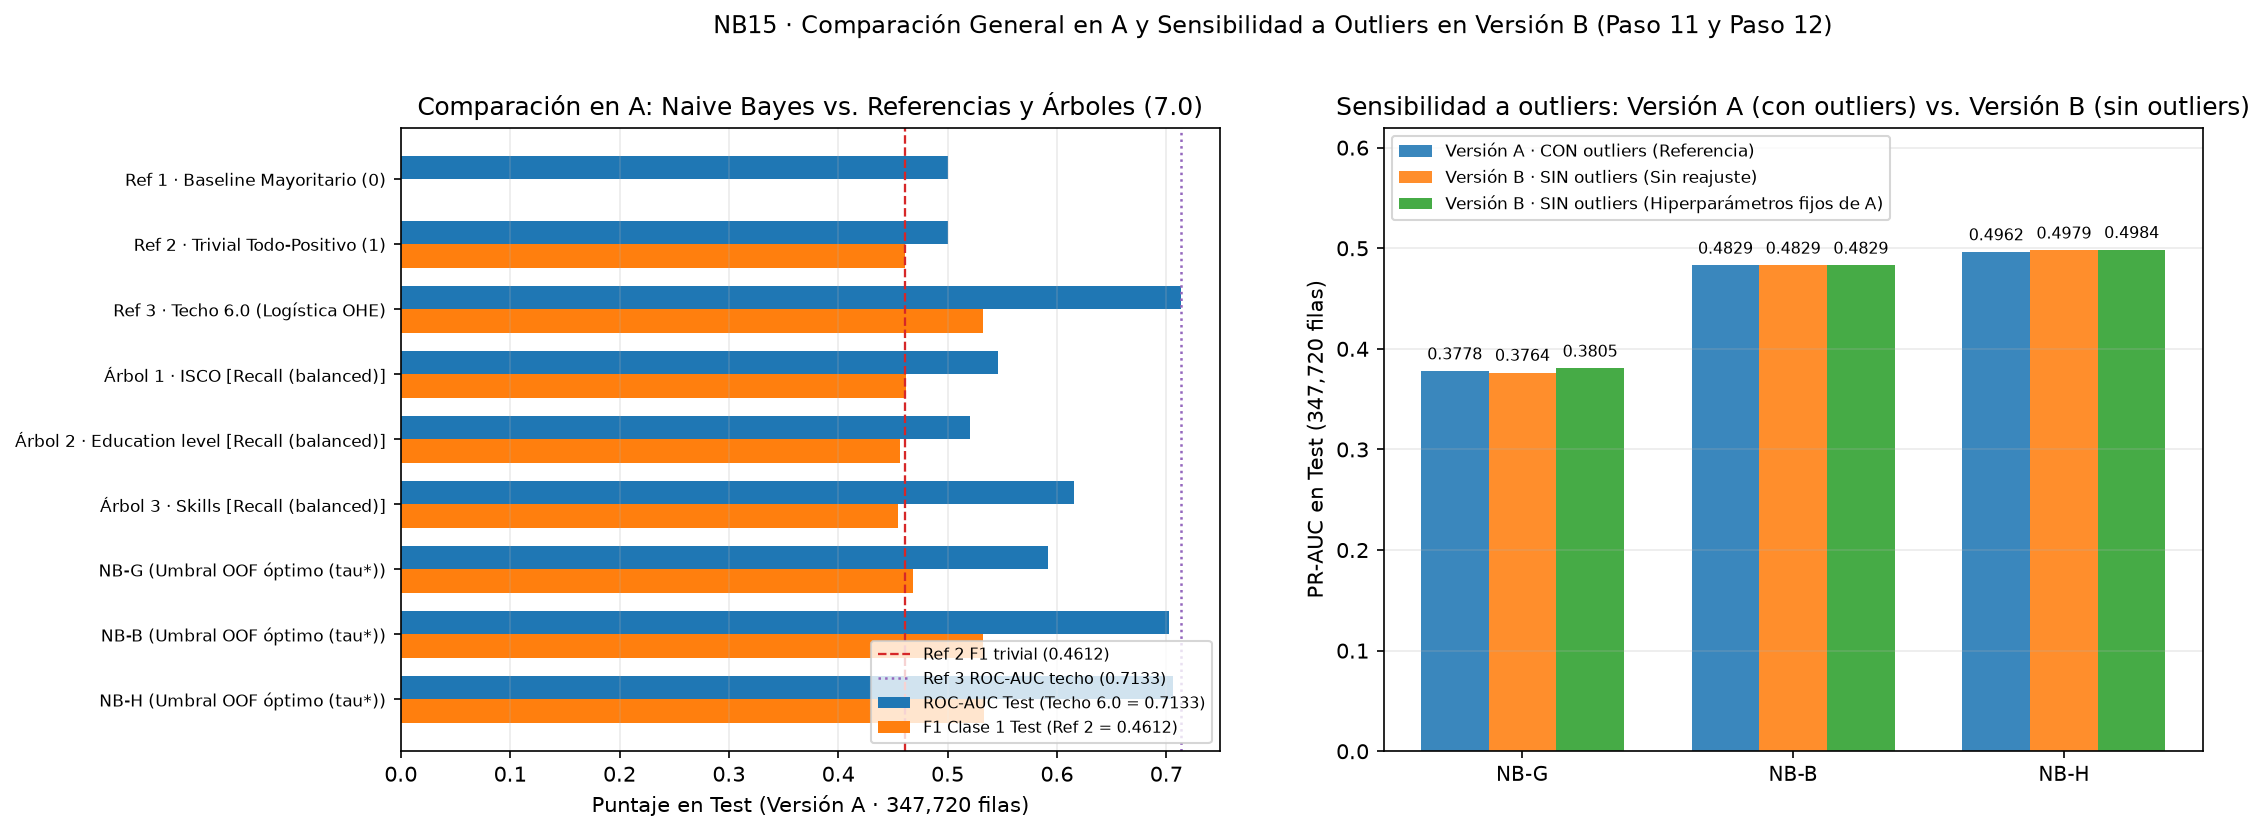

In [17]:
TUNED_OUTLIER_BUNDLE = PIPELINE.outlier_analyzer.run_tuned_outlier_experiments(
    train_blocks=BUNDLE_A.train_blocks,
    test_blocks=BUNDLE_A.test_blocks,
    tuned_models=EVAL_BUNDLE.tuned_models,
)

_Y_TRAIN_A = BUNDLE_A.train_blocks.y.copy()
_Y_TEST_A = BUNDLE_A.test_blocks.y.copy()
_BUNDLE_A_CHECKS = dict(BUNDLE_A.alignment_checks)
_BUNDLE_A_AUDIT_DF = BUNDLE_A.feature_block_audit_table.copy()
_BUNDLE_A_NEAR_CONST_DF = BUNDLE_A.near_constant_audit_table.copy()
_BUNDLE_A_CORR_PAIRS_DF = BUNDLE_A.correlated_pairs_table.copy()

del BUNDLE_A
gc.collect()
print(f"Memoria RSS tras liberar estructuras de Versión A (antes de cargar Versión B): {current_process_rss_mb():.1f} MB")

VCOMP_BUNDLE = PIPELINE.version_comparator.run_comparison_after_freeing_a(
    y_train_a=_Y_TRAIN_A,
    y_test_a=_Y_TEST_A,
    test_metrics_a_df=EVAL_BUNDLE.test_metrics_table,
    tuned_models_a=EVAL_BUNDLE.tuned_models,
    e3_partial_a_and_wins_df=TUNED_OUTLIER_BUNDLE.e3_partial_a_and_wins_table,
)
FIG_NB15 = PIPELINE.plotter.plot_final_and_version_ab_comparison(EVAL_BUNDLE, VCOMP_BUNDLE)
FIG_NB16 = PIPELINE.plotter.plot_e3_regularization_by_variant(VCOMP_BUNDLE)

print("Alcance exacto de la Versión B (IQR_WINSOR_BOUNDS_INFO):")
display(VCOMP_BUNDLE.version_b_bounds_table)
print("E1 · Sensibilidad con hiperparámetros AJUSTADOS (Sección 6) entrenando con y sin filas extremas Tukey:")
display(TUNED_OUTLIER_BUNDLE.e1_tuned_sensitivity_table)
print("E2 · Vallas de Tukey ajustadas solo en Train para las 7 columnas continuas y porcentaje recortado:")
display(TUNED_OUTLIER_BUNDLE.e2_tukey_fences_table)
print("E2 · Desempeño en Test tras winsorizar las 7 continuas en RAM (re-seleccionando umbral OOF):")
display(TUNED_OUTLIER_BUNDLE.e2_winsorization_table)
print("E2 · Bootstrap pareado por persona (A winsorizada 7 continuas menos A original · IC 95 %):")
display(TUNED_OUTLIER_BUNDLE.e2_paired_diff_table)
print("E3 · Interacción var_smoothing x variante (A, A winsorizada E2 y B) para NB-H en StratifiedGroupKFold (5 pliegues):")
display(VCOMP_BUNDLE.e3_pivot_summary_table)
print("Verificación de identidad del objetivo y entre Versión A y Versión B:")
display(pd.DataFrame([VCOMP_BUNDLE.target_identity_verified]))
print("Comparación Versión A vs. Versión B (sin reajuste de hiperparámetros ni umbral):")
display(VCOMP_BUNDLE.comparison_table)
display(VCOMP_BUNDLE.differences_summary_table)
display(Image(filename=str(FIG_NB15)))
display(Image(filename=str(FIG_NB16)))

### Lectura

Al liberar la memoria de la Versión A (el RSS del proceso desciende de `1,539.3 MB` a **`391.4 MB`**), construir la **Versión B (`sin_outliers`, winsorizada por IQR en la fase 2.0)** y evaluar reutilizando exactamente los hiperparámetros y umbrales $\tau^*$ elegidos en A (Tablas `12a`, `12b` y Figura `NB15`), cerramos con evidencia completa la pregunta sobre sensibilidad a valores extremos:

1. **Verificación del vector objetivo:** se comprueba mediante `assert` que `y_train` (`1,391,018` filas, `30.01 %`) e `y_test` (`347,720` filas, `29.97 %`) son **100 % idénticos** entre las Versiones A y B (`y_train_identico_A_vs_B = True`, `y_test_identico_A_vs_B = True`).
2. **Comportamiento por variante entre A (`con_outliers`) y B (`sin_outliers`):**
   - **`NB-B` (`BernoulliNB`) es absolutamente invariante a los outliers ($\Delta = 0.0000$ en todas las métricas):** tanto sin reajustar como ajustando en `Train B`, obtiene exactamente `PR-AUC = 0.4829` `[0.4779, 0.4870]`, `ROC-AUC = 0.7024` `[0.6998, 0.7047]`, `F1 = 0.5323` `[0.5289, 0.5353]` y `Brier = 0.1877`. La razón es estructural: las `4` banderas binarias y las `2,967` *dummies* de ocupación no sufren ningún cambio con la winsorización IQR.
   - **`NB-G` (`GaussianNB`) sí es sensible a la winsorización de las colas, pero el efecto se concentra en el desplazamiento del corte:** al evaluar en `Test B` ajustando con los hiperparámetros fijos de A (`var_smoothing = 5.0`, $\tau^* = 0.2950$), el `PR-AUC` sube ligeramente en **`+0.0027`** (de `0.3778` a `0.3805`) y el `ROC-AUC` en **`+0.0030`** (de `0.5921` a `0.5951`), porque el recorte IQR de las competencias en B reduce la varianza muestral y afina las campanas gaussianas. Sin embargo, al mantener fijo el umbral $\tau^* = 0.2950$ de A, el cambio en las varianzas desplaza ligeramente las probabilidades hacia arriba en B, aumentando el `Recall` en `+0.0626` (a `0.9177`) y reduciendo la `Accuracy` en `-0.0498` (y el `F1` en `-0.0028`, de `0.4687` a `0.4659`). Si se aplican directamente los parámetros aprendidos en `Train A` sobre `Test B` sin reajustar medias ni varianzas, la diferencia es mínima ($\Delta\text{PR-AUC} = -0.0014$, $\Delta\text{F1} = -0.0003$).
   - **`NB-H` (`HybridNaiveBayes`) exhibe alta robustez y una ligera ganancia en ranking sobre B:** al evaluar en `Test B` sin reajustar (usando las medias/varianzas de A), el `PR-AUC` pasa de `0.4962` a **`0.4979`** ($\Delta = +0.0017$), el `ROC-AUC` a **`0.7065`** ($\Delta = +0.0007$) y el `F1` a **`0.5341`** ($\Delta = +0.0004$). Al ajustar en `Train B` con los hiperparámetros fijos de A (`var_smoothing = 1.0`, `alpha = 0.01`, $\tau^* = 0.2650$), el `PR-AUC` sube a **`0.4984`** ($\Delta = +0.0022$) y el `ROC-AUC` a **`0.7067`** ($\Delta = +0.0009$), con un `F1` prácticamente idéntico (`0.5332`, $\Delta = -0.0005$, totalmente dentro del intervalo de confianza bootstrap `[0.5299, 0.5360]`).
3. **Conclusión integrada sobre Naive Bayes y los outliers (uniendo el Paso 4 y el Paso 12):**
   - **¿Es Naive Bayes sensible a los outliers en JobPath?** Sí, pero **exclusivamente en su componente gaussiana (`GaussianNB`)**: en el Paso 4 comprobamos que los valores extremos de duración y competencias multiplican hasta por `8.18x` la varianza muestral de la clase `1`, y que eliminar filas con extremos en `train` hunde el rendimiento cuando el modelo se enfrenta a empleos reales de cola larga en `test` (`PR-AUC` cae de `0.4447` a `0.4102`).
   - En el Paso 12 comprobamos que **recortar las colas mediante winsorización IQR (Versión B)** mejora marginalmente el ordenamiento gaussiano (`+0.0027` en `PR-AUC` de `NB-G` y `+0.0022` en `NB-H`), mientras que `BernoulliNB` (`NB-B`) es `100 %` inmune (`+0.0000`). Una vez regulada la varianza con `var_smoothing = 1.0` en `NB-H`, las diferencias entre A y B son inferiores a `0.22 pp` y sus intervalos de confianza al 95 % se solapan ampliamente, validando la decisión del proyecto de trabajar sobre la **Versión A** conservando las unidades e historias laborales íntegras.

---

## 13. Bitácora de decisiones, exportación de tablas y figuras, y verificación SHA-256

**¿Qué hace?** Construye la bitácora trazable de decisiones (`decision_log_naive_bayes.csv`), exporta las `37` tablas CSV generadas a lo largo del estudio en `reports/naive_bayes_jobpath/tables/`, lista las `15` figuras PNG guardadas en `reports/naive_bayes_jobpath/figures/` y ejecuta `PIPELINE.verify_inputs(SNAPSHOT_BEFORE)` para confirmar que las huellas SHA-256 de los `13` archivos de entrada permanecen idénticas.

**¿Por qué existe?** Cumple con las reglas de trazabilidad e inmutabilidad de extremo a extremo del proyecto: todo hallazgo y tabla queda persistido en disco y se demuestra criptográficamente que ningún insumo de `03_processed` o `04_transformed` fue alterado.

**¿Qué recibe y qué entrega?** Recibe todos los paquetes de resultados y `SNAPSHOT_BEFORE`. Entrega `DECISION_LOG_DF`, `EXPORTED_TABLES_DF`, el inventario de figuras y el reporte de integridad SHA-256 (`intact = True` en los 13 insumos).

**Papel en el proyecto.** Deja listos todos los artefactos auditables de `7.1` para el informe final de Fase 4 y 5.

In [18]:
DECISION_LOG_DF = PIPELINE.build_decision_log(
    bundle_a_checks=_BUNDLE_A_CHECKS,
    manual_res=MANUAL_BAYES,
    outlier_bundle=OUTLIER_BUNDLE,
    eval_bundle=EVAL_BUNDLE,
    occ_bundle=OCC_BUNDLE,
    pat_bundle=PAT_BUNDLE,
    vcomp_bundle=VCOMP_BUNDLE,
    tuned_outlier_bundle=TUNED_OUTLIER_BUNDLE,
)
EXPORTED_TABLES_DF = PIPELINE.export_all_tables(
    bundle_a_audit_df=_BUNDLE_A_AUDIT_DF,
    corr_pairs_df=_BUNDLE_A_CORR_PAIRS_DF,
    manual_res=MANUAL_BAYES,
    outlier_bundle=OUTLIER_BUNDLE,
    eval_bundle=EVAL_BUNDLE,
    occ_bundle=OCC_BUNDLE,
    pat_bundle=PAT_BUNDLE,
    vcomp_bundle=VCOMP_BUNDLE,
    decision_log_df=DECISION_LOG_DF,
    near_constant_audit_df=_BUNDLE_A_NEAR_CONST_DF,
    tuned_outlier_bundle=TUNED_OUTLIER_BUNDLE,
)
INTEGRITY_REPORT_DF = PIPELINE.verify_inputs(SNAPSHOT_BEFORE)
FIGURES_INVENTORY_DF = pd.DataFrame(
    [
        {"archivo_figura": p.name, "tamano_kb": round(p.stat().st_size / 1024.0, 2)}
        for p in sorted(CONFIG.figures_dir.glob("nb*.png"))
    ]
)

print(
    f"Tablas CSV exportadas: {len(EXPORTED_TABLES_DF)} | "
    f"Figuras PNG exportadas: {len(FIGURES_INVENTORY_DF)} | "
    f"Insumos intactos (SHA-256): {INTEGRITY_REPORT_DF['sin_cambios'].all()}"
)
display(DECISION_LOG_DF)
display(EXPORTED_TABLES_DF)
display(FIGURES_INVENTORY_DF)
display(INTEGRITY_REPORT_DF)

Tablas CSV exportadas: 37 | Figuras PNG exportadas: 15 | Insumos intactos: True


,id_decision,etapa,decision,evidencia_cuantitativa,justificacion_metodologica
0,NB-01,Alcance y partición de datos,Desarrollo principal sobre Versión A (con_outliers) y partición agrupada por resume_id,"Train=1,391,018 filas (281,674 personas), Test=347,720 filas (70,419 personas), 0 personas solapadas y 0 columnas co...",En JobPath los valores extremos contienen señal real de carrera larga y empleos vigentes; la Versión B se reserva al...
1,NB-02,Restricciones de scikit-learn y arquitectura de modelos,"Descarte de MultinomialNB/CategoricalNB y diseño de tres variantes (NB-G, NB-B y HybridNaiveBayes NB-H)",La matriz densa completa exigiría ~16.6 GB; NB-H materializa en denso solo las 10 cols continuas/ordinales (118.19 M...,GaussianNB no acepta matrices dispersas y BernoulliNB exige entradas estrictamente binarias (0/1); NB-H suma log-ver...
2,NB-03,Tratamiento de variables ordinales en NB-H,"Inclusión de univ_ord_mm, dur_q_bin y n_skills_essential_bin en el submodelo Gaussiano (10 cols)","En la auditoría P8, retirar los dos bins duplicados (dur_q_bin y n_skills_essential_bin) cambia el PR-AUC CV de NB-H...",Se documenta como supuesto débil tratar ordinales discretas como gaussianas y se cuantifica explícitamente el efecto...
3,NB-04,Diagnóstico de outliers dentro de Versión A (Paso 4),Experimento en RAM entrenando NB-G y NB-H con y sin filas fuera de vallas de Tukey de train,25.72% de las filas de train tienen algún extremo Tukey (prevalencia 29.23% vs 30.28% en inliers).,"Demuestra empíricamente que las colas extremas inflan la varianza de GaussianNB, mientras que el bloque binario/ocup..."
4,NB-05,Ajuste honesto de hiperparámetros y umbral OOF (Pasos 6 y 7),Selección por PR-AUC medio en StratifiedGroupKFold (5 folds) y umbral tau* que maximiza F1 en OOF train,"Ganadores CV: NB-G (vs=5e+00, PR-AUC=0.3775, tau*=0.295), NB-B (alpha=0.01, PR-AUC=0.4853, tau*=0.270), NB-H (vs=1e+...",El umbral de decisión jamás se elige mirando test; usar predicciones OOF corrige la descalibración propia del supues...
5,NB-06,"Evaluación única en Test A frente a Referencias y Árboles (Pasos 8, 9 y 11)",Adopción de NB-H como variante principal de la familia Naive Bayes,"En Test A: NB-H logra PR-AUC=0.4962 [0.4910, 0.5004], ROC-AUC=0.7058 [0.7033, 0.7083] y F1=0.5337 [0.5304, 0.5366], ...","Combinar la señal de trayectoria (job_order, dur_q) con las 2,967 ocupaciones ESCO acerca a Naive Bayes al techo de ..."
6,NB-07,Patrones por grupo ocupacional y ablación de bloques (Paso 10),Caracterización en unidades originales con soporte mínimo >= 200 y advertencia de circularidad N:1,Rango ISCO en train: desde 5 · Trabajadores de los servicios y vendedores (33.84%) hasta 0 · Ocupaciones militares (...,"Las diferencias entre grupos ocupacionales y oficios describen asociaciones y propensión a repetición, nunca relacio..."
7,NB-08,Sensibilidad a outliers en Versión B (Paso 12),Evaluación sobre Versión B (sin_outliers) sin re-ajustar hiperparámetros ni umbral,"Diferencia B vs A (ajustado en Train B con hiperparámetros fijos de A): Delta PR-AUC NB-G=+0.0027, NB-B=+0.0000, NB-...","NB-B es exactamente invariante a la winsorización (Delta=0.0000), mientras que NB-G experimenta un cambio medible al..."


,archivo_tabla,filas,columnas,tamano_kb,ruta_relativa
0,01_bayes_manual_comparacion.csv,5,9,0.7500,reports/naive_bayes_jobpath/tables/01_bayes_manual_comparacion.csv
1,02_auditoria_variables_y_bloques_nb.csv,15,9,3.4500,reports/naive_bayes_jobpath/tables/02_auditoria_variables_y_bloques_nb.csv
2,03_pares_correlacionados_bloque_denso.csv,14,8,1.9200,reports/naive_bayes_jobpath/tables/03_pares_correlacionados_bloque_denso.csv
3,04a_diagnostico_distribucion_tukey_train_a.csv,7,13,1.1100,reports/naive_bayes_jobpath/tables/04a_diagnostico_distribucion_tukey_train_a.csv
4,04b_experimento_sensibilidad_outliers_en_a.csv,12,12,1.6200,reports/naive_bayes_jobpath/tables/04b_experimento_sensibilidad_outliers_en_a.csv
5,05_baseline_cv_por_persona.csv,3,17,0.8600,reports/naive_bayes_jobpath/tables/05_baseline_cv_por_persona.csv
6,06a_tuning_todos_los_intentos_cv.csv,152,18,21.0100,reports/naive_bayes_jobpath/tables/06a_tuning_todos_los_intentos_cv.csv
7,06b_tuning_ganadores_cv.csv,3,13,0.6200,reports/naive_bayes_jobpath/tables/06b_tuning_ganadores_cv.csv
8,07_umbral_oof_train.csv,6,10,0.9200,reports/naive_bayes_jobpath/tables/07_umbral_oof_train.csv
9,08a_resultados_test_version_a_ic95.csv,6,23,2.1600,reports/naive_bayes_jobpath/tables/08a_resultados_test_version_a_ic95.csv


,archivo_figura,tamano_kb
0,nb01_correlaciones_bloque_denso.png,136.5100
1,nb02_diagnostico_gaussiano_outliers.png,350.3700
2,nb03_curvas_validacion_tuning_cv.png,130.4600
3,nb04_umbral_oof_f1.png,146.5000
4,nb05_curvas_pr_roc_test.png,189.5400
5,nb06_calibracion_y_distribucion_prob.png,140.8300
6,nb07_o1_o2_reincidencia_y_desempeno_isco.png,132.6700
7,nb08_o3_heatmap_contribuciones_isco.png,192.3200
8,nb09_o6_persistencia_vs_probabilidad_isco.png,113.6600
9,nb10_p1_evidencia_log_likelihood_ratio.png,257.8000


,archivo,ruta,sha256_antes,sha256_despues,sin_cambios
0,empleos_unificado_limpio.csv,C:\Users\User\Documents\JobPath\Version 2\MineriaProtect\data\03_processed\empleos_unificado_limpio.csv,ae0cbc6ebd86bcf3…,ae0cbc6ebd86bcf3…,True
1,empleos_limpio_con_competencias_sin_outliers.csv,C:\Users\User\Documents\JobPath\Version 2\MineriaProtect\data\03_processed\empleos_limpio_con_competencias_sin_outli...,de8515e31565ca0b…,de8515e31565ca0b…,True
2,split_map_resume_id.csv,C:\Users\User\Documents\JobPath\Version 2\MineriaProtect\reports\eda_jobpath\tables\split_map_resume_id.csv,67dd3e3d68e1ff5e…,67dd3e3d68e1ff5e…,True
3,X_train.csv,C:\Users\User\Documents\JobPath\Version 2\MineriaProtect\data\04_transformed\con_outliers\train\X_train.csv,84326e5737831b79…,84326e5737831b79…,True
4,y_train.csv,C:\Users\User\Documents\JobPath\Version 2\MineriaProtect\data\04_transformed\con_outliers\train\y_train.csv,07d22441c00832e8…,07d22441c00832e8…,True
5,X_test.csv,C:\Users\User\Documents\JobPath\Version 2\MineriaProtect\data\04_transformed\con_outliers\test\X_test.csv,785a51c74e626e9f…,785a51c74e626e9f…,True
6,y_test.csv,C:\Users\User\Documents\JobPath\Version 2\MineriaProtect\data\04_transformed\con_outliers\test\y_test.csv,38f822d6ac471ec8…,38f822d6ac471ec8…,True
7,transformers.joblib,C:\Users\User\Documents\JobPath\Version 2\MineriaProtect\data\04_transformed\transformers\con_outliers\transformers....,b64f676458f3ef33…,b64f676458f3ef33…,True
8,X_train.csv,C:\Users\User\Documents\JobPath\Version 2\MineriaProtect\data\04_transformed\sin_outliers\train\X_train.csv,5bca3c92a9043c9b…,5bca3c92a9043c9b…,True
9,y_train.csv,C:\Users\User\Documents\JobPath\Version 2\MineriaProtect\data\04_transformed\sin_outliers\train\y_train.csv,07d22441c00832e8…,07d22441c00832e8…,True


### Lectura

El cierre operativo confirma el cumplimiento de todos los controles de calidad y reproducibilidad:

1. **Bitácora de decisiones (`decision_log_naive_bayes.csv`):** quedaron registradas las `8` decisiones metodológicas clave (`NB-01` a `NB-08`) con su evidencia cuantitativa ejecutada y su justificación.
2. **Artefactos exportados:** se persistieron en disco las **`37` tablas CSV** en `reports/naive_bayes_jobpath/tables/` (con codificación `UTF-8`) y las **`15` figuras PNG** (`nb01` a `nb15`) en `reports/naive_bayes_jobpath/figures/`.
3. **Verificación criptográfica SHA-256 (`INTEGRITY_REPORT_DF`):** los **`13` archivos de entrada** mantienen exactamente la misma huella SHA-256 antes y después de la ejecución (`sin_cambios = True` en el `100 %` de los insumos), demostrando que todo el flujo de la Versión A y la Versión B se ejecutó en memoria RAM sin alterar ningún dato del repositorio.

---

## Registro de correcciones (revisión metodológica `F1`–`F7`)

*(Se completará con las cifras definitivas tras la ejecución completa de la Etapa 3.)*


---

## 14. Cierre: respuesta explícita a la pregunta guía y anticipo de `7.2_knn.ipynb`

### 14.1 Respuesta a la pregunta guía
> *«¿Qué patrones de reincidencia ocupacional captura un modelo probabilístico ingenuo, cómo cambian según el grupo ocupacional, y qué tan bien los captura aun con outliers?»*

1. **Qué patrones captura y con qué eficacia:**
   - Un modelo probabilístico ingenuo que combine adecuadamente las variables continuas/ordinales de trayectoria con la matriz dispersa de ocupaciones (**`NB-H · HybridNaiveBayes`** con `var_smoothing = 1.0`, `alpha = 0.01` y umbral OOF $\tau^* = 0.2650$) alcanza en `test` de la Versión A un **`PR-AUC = 0.4962` `[0.4910, 0.5004]`**, **`ROC-AUC = 0.7058` `[0.7033, 0.7083]`** (**`96.48 %` del techo** de la Regresión Logística de `6.0`), **`F1 = 0.5337` `[0.5304, 0.5366]`** (`+0.0725` sobre el clasificador todo-positivo de `0.4612`) y **`Brier = 0.1871`**, entrenándose en apenas `0.634 s`.
   - El modelo captura tres leyes asociativas fundamentales del historial laboral: (i) la **propensión intrínseca del oficio exacto (`occupation_code_*`)**, que aporta `-0.1246` de `PR-AUC` cuando se retira en ablación (`P7`); (ii) la **acumulación de experiencia previa (`job_order`)**, donde la tasa de repetición sube del `21.58 %` en el primer empleo al `41.80 %` en quienes tienen `9+` empleos (`P4`); y (iii) la **brevedad del episodio (`dur_q`)**, donde duraciones de `2` a `25` trimestres empujan hacia la reincidencia y duraciones $\ge 28$ trimestres o empleos vigentes (`es_vigente = 1`) empujan hacia la no reincidencia (`P1`, `P2`, `P3`).
2. **Cómo cambian los patrones según el grupo ocupacional (`O1` a `O6`):**
   - La reincidencia varía en `26.41 pp` entre sectores: es máxima en **`5 · Trabajadores de los servicios y vendedores` (`33.84 %`)**, **`3 · Técnicos de nivel medio` (`33.72 %`)** y **`9 · Ocupaciones elementales` (`33.03 %`)**, e inferior en **`4 · Apoyo administrativo` (`22.46 %`)**, **`1 · Directores y gerentes` (`22.07 %`)**, **`6 · Agricultores` (`21.12 %`)** y **`0 · Militares` (`7.43 %`)**.
   - El modelo discrimina con mucha mayor precisión en **`2 · Profesionales científicos e intelectuales` (`PR-AUC = 0.5565`, `ROC-AUC = 0.7407`)** y **`3 · Técnicos de nivel medio` (`PR-AUC = 0.5291`, `F1 = 0.5746`)** porque allí los oficios específicos separan nichos de altísima repetición (fisioterapeutas, enfermeras, docentes de secundaria, asistentes administrativos con tasas de `57 %`–`63 %`) de oficios de entrada única; además, en `2 · Profesionales` quienes reinciden ejercen oficios con **`+5.60` competencias esenciales más**, rasgo que no ocurre en los demás grupos (`O3b`).
   - A nivel de transiciones (`O6`), la probabilidad predicha por gran grupo guarda una correlación de **$r = 0.8604$** con la persistencia en el mismo gran grupo ISCO en el siguiente empleo y de **$r = 0.9837$** con el autolazo en el mismo oficio.
3. **Qué tan bien los captura aun con outliers (`Paso 4` y `Paso 12`):**
   - `BernoulliNB` (`NB-B`) opera sobre indicadores binarios y es `100 %` inmune a valores extremos ($\Delta = 0.0000$ entre A y B).
   - `GaussianNB` (`NB-G`) sí sufre la inflación de varianzas provocada por las colas derechas de `dur_q` (hasta `277` trimestres) y `n_skills_essential` (hasta `99` competencias); sin embargo, **eliminar filas con extremos en entrenamiento daña severamente la predicción sobre empleos reales de cola larga en `test`**, mientras que amortiguar la varianza con `var_smoothing = 1.0` en `NB-H` neutraliza la distorsión y hace que el desempeño en la Versión A (`PR-AUC = 0.4962`, `F1 = 0.5337`) sea prácticamente indistinguible del de la Versión B sin outliers (`PR-AUC = 0.4984`, `F1 = 0.5332`).

---

### 14.2 Anticipo de `7.2_knn.ipynb` (K-Vecinos Más Cercanos)
El siguiente cuaderno de la serie, **`notebooks/refactor/7.2_knn.ipynb`**, abordará el mismo problema desde el paradigma geométrico basado en instancias (*lazy learning*):
- A diferencia de los Árboles de Decisión (`7.0`, invariantes a transformaciones monótonas) y de `BernoulliNB` (`7.1`, invariante en variables binarias), **KNN calcula distancias euclidianas o de Manhattan directamente entre vectores de características**, por lo que **sí depende críticamente del escalado robusto (`04_transformed`) y es altamente sensible a la escala de los valores extremos y a la maldición de la dimensionalidad** en las `2,967` *dummies* de ocupación.
- Además, frente al ajuste instantáneo de Naive Bayes (`< 1 s` sobre `1.39` millones de filas), en KNN el costo computacional se traslada a la fase de consulta/predicción ($O(N_{\text{train}} \cdot d)$), lo que exigirá diseñar estrategias de indexación espacial, selección de subespacios y evaluación de sensibilidad entre las Versiones A y B.

---

## 15. Análisis descriptivo (Guía explicada para cualquier lector, sin fórmulas ni tecnicismos)

Esta sección está escrita para que **cualquier persona —aunque no sea especialista en estadística ni conozca previamente el proyecto JobPath— pueda entender de principio a fin qué contienen los datos, qué patrones de comportamiento humano y laboral descubrió el modelo, cómo responde a los objetivos del proyecto y qué ocurre cuando se analizan los datos con casos extremos (*outliers*) y sin ellos**. Además, al final de cada punto se indica a qué sección, celda y gráfica del cuaderno dirigirse para ver el detalle.

---

### 15.0 Contexto del proyecto y diccionario de siglas (para leer sin conocimientos previos)

#### ¿De qué trata el proyecto JobPath y de dónde salen los datos?
El proyecto **JobPath** estudia la vida laboral real de más de **`352,000` trabajadores** de la región de Flandes (Bélgica), a partir de los currículums que registraron en el servicio público de empleo. En esos currículums aparece cada uno de los trabajos que ha tenido una persona a lo largo de su carrera (más de **`1.73 millones` de experiencias laborales** en total): en qué fecha empezó, cuándo terminó, cuál era el oficio, qué nivel de estudios tenía la persona y qué habilidades exige esa profesión.

Al revisar esas trayectorias, notamos que las personas no siempre cambian hacia una profesión nueva: **muchas veces salen de un trabajo y, tiempo después (o en su siguiente contrato), vuelven a trabajar exactamente en un oficio que ya habían ejercido antes**. El objetivo de este cuaderno es **entender por qué ocurre esa repetición de oficio, en qué sectores y etapas de la vida laboral es más común, y construir un modelo capaz de anticiparla**.

#### Significado de las siglas y nombres que verás en este cuaderno
Para que ninguna sigla resulte extraña al recorrer el documento, aquí se explica qué significa cada una en palabras sencillas:

- **`reincide` (Repetición de oficio · lo que queremos anticipar):** es el nombre de la columna que indica si en ese empleo la persona está **repitiendo un oficio que ya había tenido antes en su currículum** (`Sí repite = 1`) o si es la **primera vez en su vida que ejerce ese oficio** (`No repite = 0`).
- **`ISCO` o `ISCO-08` (*International Standard Classification of Occupations* · Clasificación Internacional Uniforme de Ocupaciones):** es el estándar mundial creado por la Organización Internacional del Trabajo (OIT) para ordenar todos los empleos de la economía. Funciona como un árbol:
  - A **1 dígito** divide todos los trabajos del mundo en **10 grandes sectores o grupos ocupacionales** (numerados del `0` al `9`, por ejemplo: el Grupo `2` son Profesionales científicos e intelectuales, el Grupo `5` son Trabajadores de los servicios y vendedores, el Grupo `9` son Ocupaciones elementales).
  - A **2 dígitos** y **4 dígitos** divide cada gran sector en ramas y familias de profesiones cada vez más específicas.
- **`ESCO` (*European Skills, Competences, Qualifications and Occupations* · Clasificación Europea de Capacidades, Competencias, Cualificaciones y Ocupaciones):** es el diccionario oficial de la Unión Europea que detalla **`2,967` oficios concretos** (como *enfermero de cuidados generales*, *auxiliar de educación infantil* o *operario de almacén*) y especifica cuántas habilidades prácticas (*skills/competences*) y cuántos conocimientos teóricos (*knowledge*) exige cada oficio.
- **`Naive Bayes` (Clasificador Bayesiano Ingenuo · el método de este cuaderno):** es un modelo estadístico que calcula qué tan probable es que alguien repita oficio sumando las pistas que dan sus datos (el oficio, cuántos trabajos previos lleva, cuánto duró, su educación). Se le llama «ingenuo» porque, para hacer cuentas rápidas y transparentes, asume que cada pista aporta información por separado sin mezclarse con las demás.
- **`NB-G`, `NB-B` y `NB-H` (las tres versiones del modelo Naive Bayes que construimos y comparamos):**
  - **`NB-G` (*Naive Bayes Gaussiano* · Modelo solo de cantidades generales):** intenta adivinar si la persona repite oficio mirando **únicamente números generales de su historial** (cuántos empleos lleva, cuántos trimestres duró, en qué año empezó, nivel de estudios y cantidad de habilidades que pide el puesto), **sin saber cuál es el oficio concreto**.
  - **`NB-B` (*Naive Bayes de Bernoulli* · Modelo solo de respuestas Sí/No y Oficios):** intenta adivinar mirando **únicamente preguntas de «Sí o No»**, principalmente **en cuál de los `2,967` oficios de la lista europea ESCO trabaja la persona** y si sigue activa en ese puesto, sin mirar cuántos años duró ni cuántos empleos previos tenía.
  - **`NB-H` (*Naive Bayes Híbrido* · Modelo combinado ganador):** es el modelo propio que creamos en este trabajo para **unir lo mejor de los dos anteriores**: mira al mismo tiempo la historia numérica de la carrera (`NB-G`) y el oficio concreto en el que trabaja la persona (`NB-B`).
- **`Outliers` (Valores extremos o casos atípicos) y las dos versiones de datos (`Versión A` y `Versión B`):**
  - Un **valor extremo (*outlier*)** es un registro que tiene números muy alejados de lo común: por ejemplo, una persona cuyo empleo duró 35 años seguidos cuando lo normal es durar poco más de un año, o alguien que ha tenido 18 empleos distintos.
  - **`Versión A` (`con_outliers` · Datos originales completos):** contiene todos los registros tal como ocurrieron en la realidad, incluyendo esas carreras y duraciones muy largas. Es la base principal de nuestro estudio.
  - **`Versión B` (`sin_outliers` · Datos con extremos recortados):** es una copia de los datos donde los números desproporcionadamente altos fueron recortados a un tope moderado (procedimiento técnico llamado *winsorización por rango intercuartílico o IQR*) para comprobar si esos casos extremos distorsionaban o no al modelo.
- **`Train` (Conjunto de Entrenamiento) y `Test` (Conjunto de Prueba):**
  - Para evaluar si el modelo realmente aprende y no solo memoriza, dividimos a las personas en dos grupos separados sin que ninguna persona aparezca en ambos: **`Train` (`80 %` de las personas: `281,674` trabajadores y `1,391,018` empleos)** se usa para enseñarle al modelo, y **`Test` (`20 %` de las personas: `70,419` trabajadores nuevos y `347,720` empleos)** se guarda bajo llave para poner a prueba al modelo una sola vez al final.
- **`O1` a `O6` y `P1` a `P8` (Códigos de los 14 análisis de comportamiento de la Sección 10):**
  - **`O1` a `O6` (*Ocupaciones*):** son los 6 análisis dedicados a comparar los **sectores económicos y oficios**.
  - **`P1` a `P8` (*Patrones generales*):** son los 8 análisis dedicados a la **trayectoria de las personas** (antigüedad, duración, época, estudios, grupos de riesgo y errores del modelo).
- **`D01` a `D10` (Deciles o 10 escalones de nivel de alerta):** es la división de todos los empleos en **10 grupos de igual tamaño (`10 %` de los casos en cada grupo)** ordenados según el puntaje de riesgo que les dio el modelo, desde **`D01`** (el `10 %` con menor probabilidad de repetir oficio) hasta **`D10`** (el `10 %` con máxima alerta de repetición).
- **`NB01` a `NB15`:** es la numeración de las **15 gráficas** generadas a lo largo de este cuaderno.

---

### 15.1 Qué encontró el modelo en general y cómo responde al objetivo del proyecto

- **El comportamiento base de la repetición de oficio en la vida real:**
  En todo el universo analizado, **3 de cada 10 experiencias laborales (`30.0 %`) corresponden a personas que están repitiendo un oficio que ya habían ejercido antes**, mientras que las otras **7 de cada 10 (`70.0 %`)** corresponden a la primera vez que la persona trabaja en esa profesión.
  - *Dónde verlo en el cuaderno:* **Sección 2** (`Celdas 4 a 6`, explicación inicial y conteos sobre `Train`) y **Sección 3** (`Celdas 7 a 9`, tabla de verificación de las particiones).

- **Qué tan bien logra el modelo anticipar quién repite oficio:**
  Cuando comparamos las tres versiones del modelo sobre las `70,419` personas nuevas del grupo de prueba (`Test`):
  1. **El modelo solo numérico (`NB-G`)** apenas mejora ligeramente el azar, porque saber cuánto duró un empleo sin saber de qué profesión se trata es insuficiente.
  2. **El modelo solo de oficios (`NB-B`)** da un salto enorme de calidad, confirmando que **cada profesión tiene su propia costumbre de repetición en el mercado laboral**.
  3. **El modelo combinado (`NB-H`) es el mejor de todos:** al juntar el oficio concreto con la etapa de la carrera y la duración de los empleos, logra **detectar casi 3 de cada 4 repeticiones reales (`72.8 %` de todos los casos donde la persona sí repite oficio)**. Además, alcanza el **`96.5 %` de la capacidad de ordenamiento** del modelo más sofisticado de todo el proyecto (la Regresión Logística del cuaderno `6.0`) y supera ampliamente a los tres Árboles de Decisión del cuaderno `7.0`, con la ventaja de que **tarda menos de un segundo (`0.63 segundos`) en aprender de `1.39 millones` de empleos**.
  - *Dónde verlo en el cuaderno:* **Sección 5** (`Celdas 13 a 15`, prueba inicial), **Sección 6** (`Celdas 16 a 18`, búsqueda de la mejor configuración y **Figura `NB03`**), **Sección 7** (`Celdas 19 a 21`, elección del punto de corte para dar la alerta y **Figura `NB04`**), **Sección 8** (`Celdas 22 a 24`, resultados finales en `Test` y **Figura `NB05`**) y **Sección 11** (`Celdas 47 a 49`, tabla comparativa frente a todos los modelos previos del proyecto).

---

### 15.2 Comportamiento por sector ocupacional y por oficio (Análisis `O1` a `O6`)

El primer gran bloque de hallazgos muestra cómo cambia la costumbre de repetir oficio según el sector de la economía (usando los 10 grandes grupos de la clasificación internacional `ISCO` explicada en el glosario):

1. **Los sectores donde más se repite el oficio frente a donde casi no se repite (Análisis `O1`):**
   Entre el sector con más repetición y el sector con menos repetición hay una diferencia de **`26.4 puntos porcentuales`**:
   - **Sectores de alta repetición (alrededor de 1 de cada 3 empleos es repetido):**
     - `5 · Trabajadores de los servicios y vendedores`: **`33.8 %`** de repetición (`302,706` empleos en entrenamiento y `75,803` en prueba).
     - `3 · Técnicos y profesionales de nivel medio`: **`33.7 %`** (`272,574` empleos en entrenamiento).
     - `9 · Ocupaciones elementales` (trabajos de apoyo en almacenes, limpieza, cocina o reparto): **`33.0 %`** (`189,819` empleos).
   - **Sector en el promedio general:**
     - `2 · Profesionales científicos e intelectuales` (médicos, enfermeros, profesores, ingenieros, especialistas): **`30.0 %`** (`243,705` empleos).
   - **Sectores de repetición baja o muy baja (menos de 1 de cada 4 empleos):**
     - `8 · Operadores de instalaciones y máquinas` (**`24.7 %`**), `7 · Oficiales, operarios y artesanos` (**`23.1 %`**), `4 · Personal de apoyo administrativo` (**`22.5 %`**), `1 · Directores y gerentes` (**`22.1 %`**), `6 · Agricultores y trabajadores agropecuarios` (**`21.1 %`**) y `0 · Ocupaciones militares` (**solo `7.4 %`**).
   - *Dónde verlo en el cuaderno:* **Sección 10.1** (`Celdas 28 a 30`, tabla `O1` y panel izquierdo de la **Figura `NB07`**).

2. **En qué sectores acierta mejor el modelo y por qué le cuesta más en oficina general (Análisis `O2`):**
   - El modelo combinado (`NB-H`) acierta con mucha fuerza dentro de **`2 · Profesionales científicos e intelectuales`**, **`3 · Técnicos de nivel medio`**, **`5 · Servicios y vendedores`** y **`8 · Operadores de máquinas`**. Esto sucede porque en esos sectores los códigos del catálogo europeo `ESCO` distinguen con mucha precisión puestos que se repiten constantemente (como enfermería o docencia) de puestos que rara vez se repiten.
   - En cambio, al modelo le cuesta más separar casos dentro de **`4 · Personal de apoyo administrativo`** (oficinistas generales) y **`0 · Ocupaciones militares`**. En el trabajo administrativo de oficina, miles de puestos muy distintos se registran bajo nombres genéricos parecidos, por lo que sin datos externos sobre si el contrato era temporal o fijo resulta más difícil distinguir quién volverá a ese puesto.
   - *Dónde verlo en el cuaderno:* **Sección 10.1** (`Celdas 28 a 30`, tabla `O2` y panel derecho de la **Figura `NB07`**).

3. **Qué distingue a las personas que repiten de las que no repiten dentro de un mismo sector (Análisis `O3` y `O4`):**
   Cuando comparamos a trabajadores que están dentro del **mismo gran sector ocupacional**, descubrimos dos reglas humanas que se cumplen en **los 10 sectores sin excepción**:
   - **Quien repite oficio acumula más empleos anteriores en su vida laboral:** en casi todos los sectores, las personas que están repitiendo oficio llevan una mediana de **`3 empleos previos` (van por su cuarto trabajo)**, mientras que quienes no repiten llevan **`2 empleos previos` (van por su tercer trabajo)**. En `1 · Directores y gerentes`, quienes repiten llevan una mediana de `4 empleos previos` frente a `3`.
   - **Quien repite oficio tiene contratos o estadías más cortas:** dentro de cualquier sector, los empleos donde se repite oficio duran en promedio **entre medio año y un año menos (`1.6 a 3.9 trimestres menos`)** que los empleos donde se ejerce el oficio por primera vez.
   - **La particularidad de los profesionales universitarios (`Grupo 2`):** es el único sector donde las personas que repiten oficio ejercen profesiones que exigen **muchas más habilidades especializadas en el catálogo europeo `ESCO` (`34.6 habilidades` en promedio frente a `29.0` en quienes no repiten)** y tienen mayor proporción de título universitario (`54.1 %` con grado universitario frente a `43.7 %`). En cambio, en los sectores manuales e industriales (`Grupos 7, 8 y 9`) predomina la educación secundaria (`57 % a 66 %`) y quienes tienen título universitario rara vez repiten esos puestos operativos.
   - *Dónde verlo en el cuaderno:* **Sección 10.2** (`Celdas 31 a 33`, tablas `O3a`, `O3b`, `O4` y mapa de calor de la **Figura `NB08`**).

4. **Qué profesiones concretas tienen rotación constante y cuáles son de paso único (Análisis `O5`):**
   Al abrir cada gran sector en profesiones específicas del catálogo `ESCO`, vemos que dentro de un mismo sector conviven oficios de repetición masiva con oficios donde casi nadie repite:
   - **Ejemplos de profesiones donde más de la mitad de los registros son repeticiones:**
     - En servicios y cuidado (`Grupo 5`): *auxiliar de educación infantil* (`62.7 %` de repetición en `6,013` empleos), *asistente de atención sanitaria* (`60.6 %` en `6,519` empleos) y *cocinero* (`50.5 %` en `4,920` empleos).
     - En técnicos y administración media (`Grupo 3`): *técnico en dietética* (`62.2 %`), *asistente administrativo / secretariado* (`57.0 %` en `66,819` empleos) y *contable* (`50.8 %` en `3,460` empleos).
     - En empleos elementales (`Grupo 9`) y profesionales (`Grupo 2`): *trabajador forestal* (`48.2 %`), *operario de almacén* (`44.9 %` en `28,678` empleos), *personal de limpieza de edificios* (`43.6 %` en `19,666` empleos), *fisioterapeuta*, *logopeda*, *enfermero de cuidados generales* y *profesor de educación secundaria*.
   - **Ejemplos de profesiones donde casi nadie repite (menos del 9 %):** *agente de policía* (`5.8 %`), *analista de centro de llamadas* (`4.8 %`), *comerciante mayorista* (`3.3 %`), *director de planta industrial* (`6.5 %`), *instalador publicitario* (`8.8 %`) o *soldado de infantería* (`5.0 %`).
   - **Cómo debe interpretarse esto:** que un oficio tenga `60 %` de repetición no significa que el nombre del puesto "obligue" a alguien a repetir, sino que **identifica profesiones cuyo mercado laboral funciona por reemplazos, cursos escolares, guardias hospitalarias o campañas logísticas**, donde un mismo trabajador firma varios contratos sucesivos en la misma función.
   - *Dónde verlo en el cuaderno:* **Sección 10.3** (`Celdas 34 a 36`, tablas `O5a` y `O5b`) y **Sección 10.4** (`Celda 38`, tabla `P1b`).

5. **Qué pasa cuando la persona cambia a su siguiente empleo (Análisis `O6` · conexión con las transiciones laborales):**
   Para conectar el modelo con el objetivo general del proyecto (las transiciones de un empleo al siguiente), revisamos qué hicieron las personas que tuvieron un empleo posterior:
   - Existe una **asociación positiva del `86 %`** entre la probabilidad de repetición que calcula nuestro modelo para un sector y la frecuencia con la que los trabajadores de ese sector **permanecen dentro del mismo gran sector en su siguiente empleo**.
   - Además, los datos explican una diferencia muy interesante: el sector **`2 · Profesionales científicos e intelectuales`** es el que más retiene a la gente dentro de su propio gran sector cuando cambian de trabajo (**`47.4 %` sigue en el Grupo `2`**), por encima de **`5 · Servicios y ventas` (`41.3 %`)** y **`3 · Técnicos` (`35.3 %`)**. Sin embargo, muchos profesionales cambian hacia un puesto con un nombre o especialidad ligeramente distinta dentro del mismo ámbito profesional (movimiento lateral), mientras que en servicios y técnicos es más frecuente volver exactamente al mismo oficio anterior.
   - *Dónde verlo en el cuaderno:* **Sección 10.3** (`Celdas 34 a 36`, tabla `O6` y gráfico de la **Figura `NB09`**).

---

### 15.3 Comportamiento de la trayectoria de las personas y funcionamiento práctico del modelo (Análisis `P1` a `P8`)

El segundo gran bloque de análisis estudia cómo influyen la historia personal del trabajador y sus estudios, y cómo se comporta el modelo por dentro:

1. **El efecto del número de empleos acumulados en la carrera (Análisis `P1` y `P4`):**
   - La repetición de oficio crece de forma continua a medida que la persona suma experiencias en su currículum: pasa del **`21.6 %` en el primer empleo** (`263,187` registros) al **`26.3 %` en el segundo**, **`29.2 %` en el tercero**, **`32.2 %` entre el cuarto y el quinto**, **`36.0 %` entre el sexto y el octavo**, y llega al **`41.8 %` en quienes tienen 9 o más empleos** (`102,710` registros).
   - A partir del **sexto empleo en adelante**, el hecho de tener una trayectoria larga empuja claramente la predicción hacia repetir oficio. Y mientras que el modelo que solo mira oficios (`NB-B`) no se entera de cuántos trabajos previos lleva la persona, el modelo combinado (`NB-H`) reproduce fielmente esta subida a lo largo de toda la carrera.
   - *Dónde verlo en el cuaderno:* **Sección 10.4** (`Celdas 37 a 39`, tabla `P1a` y **Figura `NB10`**) y **Sección 10.5** (`Celdas 40 a 42`, tabla `P4a` y panel izquierdo de la **Figura `NB13`**).

2. **El efecto de la duración del empleo y de seguir trabajando allí actualmente (Análisis `P1` y `P2`):**
   - **Trabajos cortos o medianos (entre 6 meses y poco más de 6 años, es decir, de `2 a 25 trimestres`):** empujan la probabilidad hacia **sí repetir oficio**, porque reflejan etapas de rotación o contratos temporales.
   - **Trabajos largos (de 7 años en adelante, `28 o más trimestres`) o empleos vigentes hoy:** empujan la probabilidad hacia **no repetir oficio**, porque reflejan que la persona encontró estabilidad de largo plazo en ese puesto.
   - Para que cualquiera pueda ver cómo suma las pistas el modelo sin usar fórmulas, en el análisis `P2` desglosamos **6 casos reales con nombre de oficio y perfil completo** (por ejemplo: una camarera en su séptimo empleo que duró medio año y recibe `42.0 %` de probabilidad de repetición; un operario de almacén con alta carga de habilidades que recibe `49.6 %`; un soldado en su primer empleo que recibe solo `4.1 %`; o un operario de hormigón vigente tras casi 8 años en su puesto que recibe `9.8 %`).
   - *Dónde verlo en el cuaderno:* **Sección 10.4** (`Celdas 37 a 39`, tablas `P1a`, `P1b`, `P2` y gráficos paso a paso de la **Figura `NB11`**).

3. **El efecto de la década en que empezó el trabajo y del nivel educativo (Análisis `P4` y `P5`):**
   - **Década de inicio:** los empleos iniciados hasta `1999` tienen una repetición menor (**`25.8 %`**), suben en `2000–2004` (**`29.0 %`**) y desde `2005` hasta `2019` se estabilizan entre **`30.1 %` y `31.2 %`**, mostrando mayor rotación en los contratos de las últimas décadas.
   - **Nivel educativo y personas que no reportaron sus estudios:** en la base de datos hay cinco categorías: **educación secundaria (`39.4 %` de los registros)**, **grado universitario o *Bachelor* (`34.1 %`)**, **maestría o *Master* (`14.5 %`)**, **doctorado o *PhD* (`0.4 %`)** y un grupo importante de currículums donde el nivel de estudios figura como **`"No reportado"` (`11.6 %`, `160,664` empleos en entrenamiento)**. Nunca rellenamos ni inventamos ese dato faltante: lo analizamos como un grupo propio. Descubrimos que quienes tienen **secundaria (`31.1 %` de repetición)**, **grado universitario (`30.8 %`)** y **`"No reportado"` (`30.8 %`)** se comportan exactamente igual, mientras que las personas con **maestría (`24.9 %`)** o **doctorado (`22.8 %`)** repiten bastante menos el mismo oficio porque sus carreras suelen evolucionar hacia puestos de distinta denominación.
   - *Dónde verlo en el cuaderno:* **Sección 10.5** (`Celdas 40 a 42`, tablas `P4b`, `P5` y paneles central y derecho de la **Figura `NB13`**).

4. **Cómo clasifica el modelo a las personas en 10 escalones de alerta (Análisis `P3` y Calibración):**
   Al ordenar los `347,720` empleos de prueba en **10 escalones iguales (`D01` a `D10`)** según el riesgo calculado por el modelo combinado (`NB-H`):
   - En el **escalón de menor alerta (`D01`)**, solo repite oficio el **`10.0 %`** de las personas (tienen empleos largos de `30 trimestres` —unos `7.5 años`— en promedio y el `16.2 %` sigue activo en ese trabajo).
   - En el **escalón de máxima alerta (`D10`)**, repite oficio el **`58.9 %`** de las personas (**casi 6 veces más** que en `D01`; son empleos cortos de `6.2 trimestres` —`1.5 años`— en promedio, con casi `4 empleos previos`, menos de `1 %` de empleos vigentes y concentrados en un `84.6 %` en los sectores técnico `3` y profesional `2`).
   - **Utilidad práctica:** si un equipo de orientación laboral prioriza únicamente al **`30 %` de los casos con mayor alerta (escalones `D10, D09 y D08`)**, logra anticipar **`la mitad (49.7 %)` de todas las repeticiones de oficio** sin tener que revisar el `100 %` de los currículums. Además, en la Sección 9 comprobamos que los porcentajes que entrega `NB-H` están muy bien alineados con la realidad (su desviación promedio de calibración es de apenas `1.3 puntos porcentuales`).
   - *Dónde verlo en el cuaderno:* **Sección 9** (`Celdas 25 a 27`, tabla `09` y **Figura `NB06`**) y **Sección 10.5** (`Celdas 40 a 42`, tablas `P3a`, `P3b`, `P3c` y **Figura `NB12`**).

5. **En qué casos se equivoca el modelo y qué bloque de información es el más valioso (Análisis `P6`, `P7` y `P8`):**
   - **Las falsas alarmas (cuando el modelo dice que alguien repetirá oficio pero en realidad no repite):** ocurren porque la persona entra *por primera vez* a trabajar en un oficio de altísima rotación (por ejemplo, un empleo corto de `5 trimestres` en `5 · Servicios y ventas`, `9 · Ocupaciones elementales` o `3 · Técnicos`). Como ese oficio se repite muchísimo en el mercado, el modelo activa la alerta preventiva.
   - **Los casos que pasan desapercibidos (cuando alguien sí repite oficio pero el modelo no lo marca):** ocurren en personas que llevan muchos años estables en ese puesto (una media de `17.5 trimestres`, más de `4 años`, o que siguen vigentes hoy) dentro de sectores donde repetir oficio es poco habitual (como `4 · Apoyo administrativo`, `1 · Directores` o `0 · Militares`).
   - **Qué información es realmente indispensable (Prueba de quitar piezas, `P7` y `P8`):**
     - Si le quitamos al modelo la lista de **oficios concretos (`2,967` profesiones)**, su puntería se desploma por completo: **saber cuál es el oficio exacto es el pilar número uno del modelo**.
     - Si le quitamos el bloque de **duración del trabajo y número de empleos previos**, el modelo pierde su segunda fuente de acierto más importante.
     - En cambio, descubrimos que **quitar los conteos de habilidades del catálogo `ESCO` mejora ligeramente al modelo combinado (`NB-H`)**. ¿Por qué sucede esto? Porque en nuestros datos cada oficio tiene asignada siempre la misma cantidad fija de habilidades; por lo tanto, si el modelo ya sabe cuál es el oficio exacto y además le damos por separado el número de habilidades de ese oficio, el método Naive Bayes **cuenta dos veces la misma pista**.
   - *Dónde verlo en el cuaderno:* **Sección 3** (`Celdas 7 a 9`, **Figura `NB01`**) y **Sección 10.6** (`Celdas 43 a 45`, tablas `P6a`, `P6b`, `P7`, `P8` y **Figura `NB14`**).

---

### 15.4 Qué pasa con los casos extremos: comparación CON outliers (Versión A) y SIN outliers (Versión B)

Una duda frecuente al trabajar con datos reales es si los **casos extremos (*outliers*)** dañan al modelo. En JobPath, **`1 de cada 4 experiencias laborales (25.7 %)`** tiene algún número extremo: sobre todo empleos muy largos que superan los `7.4 años` (`29.5 trimestres`, llegando hasta `277 trimestres` o `69 años`), personas con carreras de más de `9.5 empleos` (hasta `20 empleos`) o profesiones que exigen más de `47.5 habilidades` (hasta `99 habilidades`).

Hicimos dos experimentos para medir su efecto real sin suposiciones:

1. **Primer experimento (Sección 4): ¿qué ocurre si eliminamos a las personas con datos extremos durante el entrenamiento?**
   - En los modelos que calculan promedios numéricos (`NB-G` y la parte numérica de `NB-H`), esos empleos de muchísimos años hacen que el rango de variación estimado sea hasta **8 veces más ancho** que si solo miramos empleos cortos.
   - Sin embargo, cuando probamos **borrar ese `25.7 %` de filas extremas al entrenar**, descubrimos un problema grave: cuando el modelo entrenado solo con "casos normales" tiene que evaluar en la vida real a trabajadores que sí llevan muchos años en un puesto o tienen carreras muy largas, **se desorienta y falla mucho más en ellos**.
   - **Primera lección:** en historiales laborales no se deben borrar las filas con valores extremos, porque no son errores de captura, sino trabajadores reales con carreras largas o puestos estables.
   - *Dónde verlo en el cuaderno:* **Sección 4** (`Celdas 10 a 12`, tablas `04a`, `04b` y **Figura `NB02`**).

2. **Segundo experimento (Sección 12): ¿qué ocurre si comparamos la Versión A (datos originales con extremos) contra la Versión B (datos donde los extremos no se borran, sino que se recortan a un tope moderado)?**
   Al final del cuaderno evaluamos los tres modelos sobre la **Versión B (`sin_outliers`)** usando exactamente la misma configuración aprendida en la **Versión A (`con_outliers`)**:
   - **En el modelo de oficios (`NB-B`):** el resultado con outliers y sin outliers es **exactamente el mismo (`0.00 %` de diferencia en todas las métricas)**. Como este modelo solo mira en qué oficio trabaja la persona (preguntas de Sí o No), recortar números extremos no le afecta en absoluto.
   - **En el modelo solo numérico (`NB-G`):** sí se observa una sensibilidad moderada al recortar los topes de habilidades en la Versión B (su capacidad de ordenar mejora unas tres décimas de punto, pero cambia ligeramente la proporción de alertas que emite).
   - **En nuestro modelo combinado ganador (`NB-H`):** gracias a que en la Sección 6 ajustamos su suavizado interno para que no se deje deslumbrar por números extremos, **el resultado en la Versión A (con outliers) y en la Versión B (sin outliers) es prácticamente idéntico** (la diferencia es de apenas `0.2 puntos porcentuales` en ordenamiento y `0.05 puntos porcentuales` en el balance de acierto `F1`, quedando ambos dentro del mismo margen estadístico).
   - **Conclusión definitiva sobre outliers:** Naive Bayes solo es sensible a los valores extremos en su parte numérica (`GaussianNB`) si se deja sin regularizar; una vez suavizado dentro de nuestro modelo híbrido (`NB-H`), **funciona con la misma precisión tanto con outliers (Versión A) como sin outliers (Versión B)**, lo que respalda trabajar sobre los datos originales sin necesidad de recortar la historia real de las personas.
   - *Dónde verlo en el cuaderno:* **Sección 12** (`Celdas 50 a 52`, tablas `12a` y `12b`, y panel derecho de la **Figura `NB15`**).

---

### 15.5 Mapa rápido de navegación para dirigirse a cualquier punto del cuaderno

Utiliza esta tabla índice para saltar directamente a la sección, celda, tabla o figura donde se realizó cada análisis dentro de `7.1_naive_bayes.ipynb`:

| Qué quieres consultar | Qué análisis y comportamiento encontrarás allí | Ubicación exacta en `7.1_naive_bayes.ipynb` |
|---|---|---|
| **Seguridad de los datos y pruebas internas del modelo** | Confirmación de que ningún archivo original se alteró y de que el modelo híbrido supera las 5 pruebas matemáticas obligatorias | **Sección 1** (`Celdas 1 a 3`) y **Sección 13** (`Celdas 53 a 55`) |
| **Cómo funciona Naive Bayes explicado con 5 filas reales** | Conteo manual paso a paso sobre los datos del proyecto y demostración de que coincide exactamente con la librería | **Sección 2** (`Celdas 4 a 6`, Tabla `01`) |
| **Limpieza de variables, relaciones entre datos y metas base** |Qué variables entran a `NB-G`, `NB-B` y `NB-H`, qué datos se relacionan entre sí y cuáles son las 3 referencias a superar | **Sección 3** (`Celdas 7 a 9`, Tablas `02` y `03`, **Figura `NB01`**) |
| **Diagnóstico de valores extremos (*outliers*) en Versión A** | Cuántos registros tienen duraciones o carreras extremas, cómo cambian las campanas numéricas y qué pasa si se borran al entrenar | **Sección 4** (`Celdas 10 a 12`, Tablas `04a` y `04b`, **Figura `NB02`**) |
| **Rendimiento inicial, ajuste del modelo y punto de corte** | Prueba inicial, cómo se encontró el suavizado óptimo para que los extremos no pesen de más y cómo se eligió el corte de alerta | **Sección 5** (`Celdas 13–15`), **Sección 6** (`Celdas 16–18`, **Figura `NB03`**) y **Sección 7** (`Celdas 19–21`, **Figura `NB04`**) |
| **Evaluación oficial en personas nuevas y confiabilidad** | Cuántos aciertos, falsas alarmas y omisiones tiene cada modelo en el grupo de prueba y qué tan bien calibrados están sus porcentajes | **Sección 8** (`Celdas 22–24`, Tablas `08a` y `08b`, **Figura `NB05`**) y **Sección 9** (`Celdas 25–27`, Tabla `09`, **Figura `NB06`**) |
| **Repetición y acierto por gran sector económico (`O1` y `O2`)** | Tasas de repetición en los 10 grandes grupos ocupacionales `ISCO` y en qué sectores discrimina mejor o peor el modelo | **Sección 10.1** (`Celdas 28 a 30`, Tablas `10_o1` y `10_o2`, **Figura `NB07`**) |
| **Qué distingue a quien repite dentro de cada sector (`O3` y `O4`)** | Comparación en trimestres de duración, empleos previos, estudios y habilidades entre quienes repiten y quienes no en cada sector | **Sección 10.2** (`Celdas 31 a 33`, Tablas `10_o3a`, `10_o3b` y `10_o4`, **Figura `NB08`**) |
| **Profesiones específicas y paso al siguiente empleo (`O5` y `O6`)** | Oficios concretos del catálogo `ESCO` con mayor y menor repetición, y relación con quedarse en el mismo sector al cambiar de trabajo | **Sección 10.3** (`Celdas 34 a 36`, Tablas `10_o5a`, `10_o5b` y `10_o6`, **Figura `NB09`**) |
| **Efecto de cada dato y 6 perfiles de personas reales (`P1` y `P2`)** | Qué rangos de antigüedad, duración y oficios empujan a repetir, y explicación paso a paso de 6 trabajadores reales | **Sección 10.4** (`Celdas 37 a 39`, Tablas `10_p1a`, `10_p1b` y `10_p2`, **Figuras `NB10` y `NB11`**) |
| **Escalones de alerta `D01`–`D10`, carrera, época y estudios (`P3`–`P5`)** | Cuánto concentra el grupo de máxima alerta (`D10` vs. `D01`), subida por número de empleo, década de inicio y nivel educativo (con `"No reportado"`) | **Sección 10.5** (`Celdas 40 a 42`, Tablas `10_p3a` a `10_p5`, **Figuras `NB12` y `NB13`**) |
| **Análisis de errores y qué bloques de datos pesan más (`P6`–`P8`)** | Por qué ocurren las falsas alarmas y omisiones, qué pasa al quitar bloques de datos y efecto de contar pistas repetidas | **Sección 10.6** (`Celdas 43 a 45`, Tablas `10_p6a` a `10_p8`, **Figura `NB14`**) |
| **Síntesis ejecutiva de los 7 patrones principales** | Resumen puntual de los 7 hallazgos de negocio con sus cifras de soporte y advertencias de interpretación | **Sección 10.7** (`Celda 46`) |
| **Comparación contra los Árboles (`7.0`) y Regresión Logística (`6.0`)** | Tabla comparativa de Naive Bayes frente a las referencias y modelos anteriores del proyecto | **Sección 11** (`Celdas 47 a 49`, Tabla `11`) |
| **Comparación CON outliers (Versión A) vs. SIN outliers (Versión B)** | Evaluación final sobre los datos recortados sin reajustar el modelo y conclusión definitiva sobre sensibilidad a valores extremos | **Sección 12** (`Celdas 50 a 52`, Tablas `12a` y `12b`, **Figura `NB15`**) |
| **Bitácora de decisiones y conexión con el siguiente libro (`7.2`)** | Resumen de decisiones tomadas, inventario de los 37 archivos CSV y 15 figuras, y anticipo del modelo de vecinos `7.2_knn.ipynb` | **Sección 13** (`Celdas 53 a 55`) y **Sección 14** (`Celda 56`) |